In [1]:
#
# Partie 1 Exploration du jeu de données
#
# 1 - 1 : Chargement des données
# 1 - 2 : Indicateurs statistiques basiques
# 1 - 3 : Préparation du jeu de données
#
#
# Partie 2 Etude des différents types de magasins
#
# 2 - 1 : Comparaison des volumes de ventes au mois et à l'année
# 2 - 2 : Etude de corrélation des volumes de vente
# 2 - 3 : Catégorisation des magasins avec l'algorithme K-means
#
#
# Partie 3 Modèle de prévision des ventes
#
# 3 - 1 : Préparation du jeu de données
# 3 - 2 : Entrainement d'un modèle sur les groupes de magasins
# 3 - 3 : Deuxième approche de modélisation
#
#
# Partie 4 Evaluation de la performance des modèles de prévisions
#
# 4 - 1 Définition de la métrique la plus adaptée
# 4 - 2 Evaluation baseline simple
# 4 - 3 Comparaison méthode série temporelle
#

In [2]:
# Partie 1 Exploration du jeu de données
#
# 1 - 1 : Chargement des données
# 1 - 2 : Indicateurs statistiques basiques
# 1 - 3 : Préparation du jeu de données

In [3]:
# Partie 1 Exploration du jeu de données
#
# 1 - 1 : Chargement des données
#

In [4]:
## chargement des librairies
import pandas as pd
import numpy as np
import datetime
import time
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.preprocessing import StandardScaler

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from prophet import Prophet
from itables import show
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error,root_mean_squared_error

In [5]:
## chemin du dataset
train_file = "train.csv"
store_file = "store.csv"

In [6]:
# chargement du dataset des ventes
df = pd.read_csv(train_file)
df

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\1046477820.py:2: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(train_file)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [7]:
# chargement du dataset
df_store = pd.read_csv(store_file)
df_store

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [8]:
# Fusion des jeux de données ventes et magasins
df_merge = pd.merge(df, df_store, on='Store', how='left')
df_merge

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [9]:
# affichage cinq premières lignes
df_merge.head(5)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [10]:
# affichage cinq dernières lignes
df_merge.tail(5)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN
1017208,1115,2,2013-01-01,0,0,0,0,a,1,d,c,5350.0,NaN,NaN,1,22.0,2012.0,"Mar,Jun,Sept,Dec"


In [11]:
#
# 1 - 2 : Déterminez les ordres de grandeur et indicateurs statistiques basiques
#

In [12]:
# Informations sur les colonnes de données
df_merge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  object 
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  object 
 10  Assortment                 1017209 non-null  object 
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionO

In [13]:
# Statistiques sur les colonnes numériques
#df_merge.describe()
df_merge.describe().apply(lambda s: s.apply('{0:.2f}'.format))

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1017209.00,1017209.00,1017209.00,1017209.00,1017209.00,1017209.00,1017209.00,1014567.00,693861.00,693861.00,1017209.00,509178.00,509178.00
mean,558.43,4.00,5773.82,633.15,0.83,0.38,0.18,5430.09,7.22,2008.69,0.50,23.27,2011.75
std,321.91,2.00,3849.93,464.41,0.38,0.49,0.38,7715.32,3.21,5.99,0.50,14.10,1.66
min,1.00,1.00,0.00,0.00,0.00,0.00,0.00,20.00,1.00,1900.00,0.00,1.00,2009.00
25%,280.00,2.00,3727.00,405.00,1.00,0.00,0.00,710.00,4.00,2006.00,0.00,13.00,2011.00
50%,558.00,4.00,5744.00,609.00,1.00,0.00,0.00,2330.00,8.00,2010.00,1.00,22.00,2012.00
75%,838.00,6.00,7856.00,837.00,1.00,1.00,0.00,6890.00,10.00,2013.00,1.00,37.00,2013.00
max,1115.00,7.00,41551.00,7388.00,1.00,1.00,1.00,75860.00,12.00,2015.00,1.00,50.00,2015.00


In [14]:
#
# 1 - 3 Préparation du jeu de données
#

In [15]:
# Conversion format colonne date
df_merge['Date'] = pd.to_datetime(df_merge['Date'], format='%Y-%m-%d')
df_merge = df_merge.sort_values(by=['Date','Store'], ascending=True)
df_merge = df_merge.reset_index(drop=True)
#df_merge

In [16]:
# transformation et modification des données (feature engineering) pour les analyses graphiques et statistiques
df_modif = df_merge
#df_modif = df_modif[df_modif['Open'] == 1]
df_modif['year'] = df_modif["Date"].dt.year
df_modif['month'] = df_modif["Date"].dt.month
df_modif['week'] = df_modif["Date"].dt.isocalendar().week
df_modif['year_month'] = df_modif['year'].astype(str) +"-"+ df_modif["month"].astype(str)
df_modif['year_week'] = df_modif['year'].astype(str) +"-"+ df_modif["week"].astype(str)
df_modif['sales_customers'] = df_modif['Sales'] / df_modif['Customers']
df_modif['distancekm'] = (df_modif['CompetitionDistance'] / 1000).round(0)
df_modif['StoreType_LabelEncoded'] = ""
df_modif['StoreType_LabelEncoded'] = np.where( df_modif['StoreType'] == 'a',1,df_modif['StoreType_LabelEncoded'])
df_modif['StoreType_LabelEncoded'] = np.where( df_modif['StoreType'] == 'b',2,df_modif['StoreType_LabelEncoded'])
df_modif['StoreType_LabelEncoded'] = np.where( df_modif['StoreType'] == 'c',3,df_modif['StoreType_LabelEncoded'])
df_modif['StoreType_LabelEncoded'] = np.where( df_modif['StoreType'] == 'd',4,df_modif['StoreType_LabelEncoded'])
df_modif['Assortment_LabelEncoded'] = ""
df_modif['Assortment_LabelEncoded'] = np.where( df_modif['Assortment'] == 'a',1,df_modif['Assortment_LabelEncoded'])
df_modif['Assortment_LabelEncoded'] = np.where( df_modif['Assortment'] == 'b',2,df_modif['Assortment_LabelEncoded'])
df_modif['Assortment_LabelEncoded'] = np.where( df_modif['Assortment'] == 'c',3,df_modif['Assortment_LabelEncoded'])
df_modif['StateHoliday_LabelEncoded'] = ""
df_modif['StateHoliday_LabelEncoded'] = np.where( df_modif['StateHoliday'] == 'a',1,df_modif['StateHoliday_LabelEncoded'])
df_modif['StateHoliday_LabelEncoded'] = np.where( df_modif['StateHoliday'] == 'b',2,df_modif['StateHoliday_LabelEncoded'])
df_modif['StateHoliday_LabelEncoded'] = np.where( df_modif['StateHoliday'] == 'c',3,df_modif['StateHoliday_LabelEncoded'])
df_modif['PromoInterval_LabelEncoded'] = ""
df_modif['PromoInterval_LabelEncoded'] = np.where( df_modif['PromoInterval'] == 'Jan,Apr,Jul,Oct',1,df_modif['PromoInterval_LabelEncoded'])
df_modif['PromoInterval_LabelEncoded'] = np.where( df_modif['PromoInterval'] == 'Feb,May,Aug,Nov',2,df_modif['PromoInterval_LabelEncoded'])
df_modif['PromoInterval_LabelEncoded'] = np.where( df_modif['PromoInterval'] == 'Mar,Jun,Sept,Dec',3,df_modif['PromoInterval_LabelEncoded'])
df_modif["Type_Assort"] = df_modif['StoreType'].astype(str) +"-"+ df_modif["Assortment"].astype(str)
df_modif['sales_month'] = df_modif.groupby(['StoreType','year_month'])['Sales'].transform('mean')
df_modif['customers_month'] = df_modif.groupby(['Customers','year_month'])['Sales'].transform('mean')
df_modif['StoreType_LabelEncoded'] = pd.to_numeric(df_modif.StoreType_LabelEncoded, errors='coerce')
df_modif['Assortment_LabelEncoded'] = pd.to_numeric(df_modif.Assortment_LabelEncoded, errors='coerce')
df_modif['StateHoliday_LabelEncoded'] = pd.to_numeric(df_modif.StateHoliday_LabelEncoded, errors='coerce')
df_modif['PromoInterval_LabelEncoded'] = pd.to_numeric(df_modif.PromoInterval_LabelEncoded, errors='coerce')
df_modif

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,year_week,sales_customers,distancekm,StoreType_LabelEncoded,Assortment_LabelEncoded,StateHoliday_LabelEncoded,PromoInterval_LabelEncoded,Type_Assort,sales_month,customers_month
0,1,2,2013-01-01,0,0,0,0,a,1,c,...,2013-1,NaN,1.0,3,1,1.0,NaN,c-a,5166.859852,0.000000
1,2,2,2013-01-01,0,0,0,0,a,1,a,...,2013-1,NaN,1.0,1,1,1.0,1.0,a-a,5295.606773,0.000000
2,3,2,2013-01-01,0,0,0,0,a,1,a,...,2013-1,NaN,14.0,1,1,1.0,1.0,a-a,5295.606773,0.000000
3,4,2,2013-01-01,0,0,0,0,a,1,c,...,2013-1,NaN,1.0,3,3,1.0,NaN,c-c,5166.859852,0.000000
4,5,2,2013-01-01,0,0,0,0,a,1,a,...,2013-1,NaN,30.0,1,1,1.0,NaN,a-a,5295.606773,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,5,2015-07-31,5723,422,1,1,0,1,a,...,2015-31,13.561611,2.0,1,1,NaN,1.0,a-a,6027.736899,4629.485714
1017205,1112,5,2015-07-31,9626,767,1,1,0,1,c,...,2015-31,12.550196,2.0,3,3,NaN,NaN,c-c,6066.334133,8023.791667
1017206,1113,5,2015-07-31,7289,720,1,1,0,1,a,...,2015-31,10.123611,9.0,1,3,NaN,NaN,a-c,6027.736899,7621.900000
1017207,1114,5,2015-07-31,27508,3745,1,1,0,1,a,...,2015-31,7.345260,1.0,1,3,NaN,NaN,a-c,6027.736899,27508.000000


In [17]:
# tableau croisé dynamique des données de ventes par identifiant magasin
table_store = pd.pivot_table(df_modif, index=['Store'], values=['Sales','Customers','CompetitionDistance','distancekm','Open','Promo','Promo2','Assortment_LabelEncoded','StoreType_LabelEncoded','PromoInterval_LabelEncoded','StateHoliday_LabelEncoded','SchoolHoliday','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2SinceWeek','Promo2SinceYear','PromoInterval_LabelEncoded','sales_customers'], aggfunc='mean')
table_store["Type_Assort_LabelEncoded"] = table_store['StoreType_LabelEncoded'].astype(str) +"-"+ table_store["Assortment_LabelEncoded"].astype(str)
table_store = table_store.sort_values(by=['Store'], ascending=True)
table_store = table_store.round(2)
table_store['StoreType_LabelEncoded'] = table_store['StoreType_LabelEncoded'].astype(int)
table_store['Assortment_LabelEncoded'] = table_store['Assortment_LabelEncoded'].astype(int)
table_store["Type_Assort_LabelEncoded"] = table_store['StoreType_LabelEncoded'].astype(str) +"-"+ table_store["Assortment_LabelEncoded"].astype(str)
table_store = table_store.reset_index()
table_store

,Store,Assortment_LabelEncoded,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Customers,Open,Promo,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval_LabelEncoded,PromoInterval_LabelEncoded,Sales,SchoolHoliday,StateHoliday_LabelEncoded,StoreType_LabelEncoded,distancekm,sales_customers,Type_Assort_LabelEncoded
0,1,1,1270.0,9.0,2008.0,467.65,0.83,0.38,0.0,NaN,NaN,NaN,NaN,3945.70,0.20,1.52,3,1.0,8.39,3-1
1,2,1,570.0,11.0,2007.0,486.05,0.83,0.38,1.0,13.0,2010.0,1.0,1.0,4122.99,0.18,1.56,1,1.0,8.41,1-1
2,3,1,14130.0,12.0,2006.0,620.29,0.83,0.38,1.0,14.0,2011.0,1.0,1.0,5741.25,0.18,1.48,1,14.0,9.12,1-1
3,4,3,620.0,9.0,2009.0,1100.06,0.83,0.38,0.0,NaN,NaN,NaN,NaN,8021.77,0.18,1.58,3,1.0,7.25,3-3
4,5,1,29910.0,4.0,2015.0,444.36,0.83,0.38,0.0,NaN,NaN,NaN,NaN,3867.11,0.18,1.45,1,30.0,8.61,1-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1110,1111,1,1900.0,6.0,2014.0,373.55,0.83,0.38,1.0,31.0,2013.0,1.0,1.0,4342.97,0.18,1.48,1,2.0,11.55,1-1
1111,1112,3,1880.0,4.0,2006.0,693.50,0.83,0.38,0.0,NaN,NaN,NaN,NaN,8465.28,0.18,1.48,3,2.0,11.99,3-3
1112,1113,3,9260.0,NaN,NaN,596.76,0.83,0.38,0.0,NaN,NaN,NaN,NaN,5516.18,0.17,1.58,1,9.0,9.21,1-3
1113,1114,3,870.0,NaN,NaN,2664.06,0.83,0.38,0.0,NaN,NaN,NaN,NaN,17200.20,0.18,1.58,1,1.0,6.45,1-3


In [18]:
# tableau croisé dynamique du nombre de magasins par typologie
table_typo_count = pd.pivot_table(table_store, index=['StoreType_LabelEncoded'], values=['Store'], aggfunc='count')
table_typo_count = table_typo_count.reset_index()
table_typo_count

,StoreType_LabelEncoded,Store
0,1,602
1,2,17
2,3,148
3,4,348


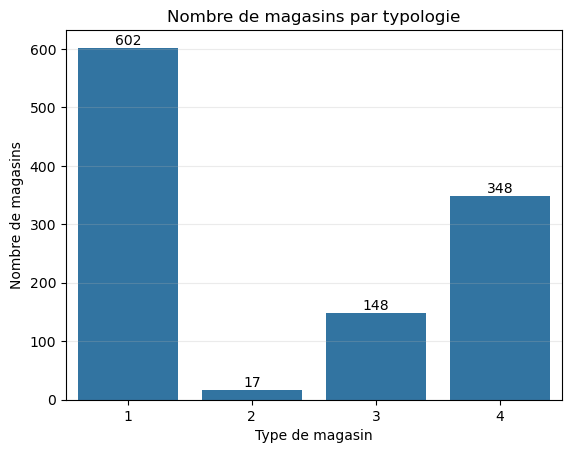

In [19]:
# Graphique en barre du nombre de magasins par typologie
ax = sns.barplot(x='StoreType_LabelEncoded', y='Store', data = table_typo_count)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Nombre de magasins par typologie')
plt.xlabel('Type de magasin')
#plt.xticks(['A','B','C','D'])
plt.ylabel('Nombre de magasins')
plt.grid(axis='y', alpha=0.25)

In [20]:
# tableau croisé dynamique du nombre de magasins par type d'assortiment
table_assort_count = pd.pivot_table(table_store, index=['Assortment_LabelEncoded'], values=['Store'], aggfunc='count')
table_assort_count = table_assort_count.reset_index()
table_assort_count

,Assortment_LabelEncoded,Store
0,1,593
1,2,9
2,3,513


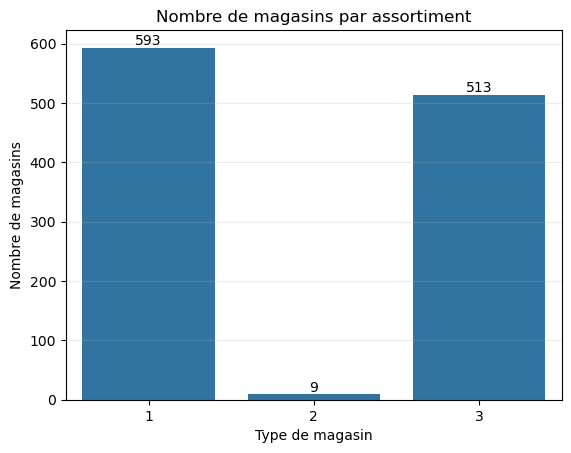

In [21]:
# Graphique en barres du nombre de magasins par type d'assortiment
ax = sns.barplot(x='Assortment_LabelEncoded', y='Store', data = table_assort_count)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Nombre de magasins par assortiment')
plt.xlabel('Type de magasin')
plt.ylabel('Nombre de magasins')
plt.grid(axis='y', alpha=0.25)

In [22]:
# tableau croisé dynamique du nombre de magasins par type de magasin et type d'assortiment
table_typo_assort_count = pd.pivot_table(table_store, index=['Type_Assort_LabelEncoded'], values=['Store'], aggfunc='count')
table_typo_assort_count = table_typo_assort_count.reset_index()
table_typo_assort_count

,Type_Assort_LabelEncoded,Store
0,1-1,381
1,1-3,221
2,2-1,7
3,2-2,9
4,2-3,1
5,3-1,77
6,3-3,71
7,4-1,128
8,4-3,220


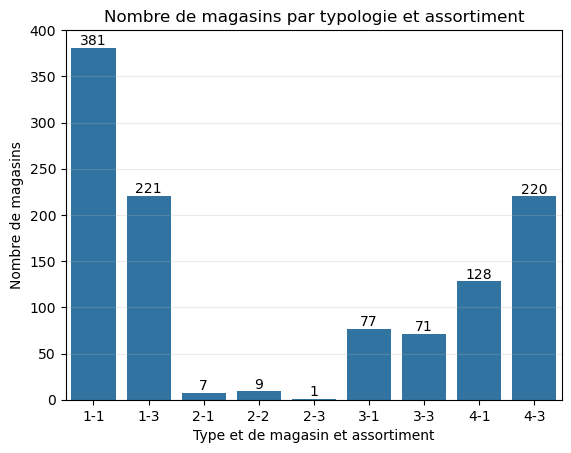

In [23]:
# Graphique en barres du nombre de magasins par type de magasin et type d'assortiment
ax = sns.barplot(x='Type_Assort_LabelEncoded', y='Store', data = table_typo_assort_count)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Nombre de magasins par typologie et assortiment')
plt.xlabel('Type et de magasin et assortiment')
plt.ylabel('Nombre de magasins')
plt.grid(axis='y', alpha=0.25)

In [24]:
# tableau croisé dynamique du nombre de magasins par type de promo
table_assort_promo = pd.pivot_table(table_store, index=['Promo2'], values=['Store'], aggfunc='count')
#table_typo_count = table_typo_count.sort_values(by=['Customers'], ascending=True)
#table_typo_count = table_typo_count.round(3)
table_assort_promo = table_assort_promo.reset_index()
table_assort_promo

,Promo2,Store
0,0.0,544
1,1.0,571


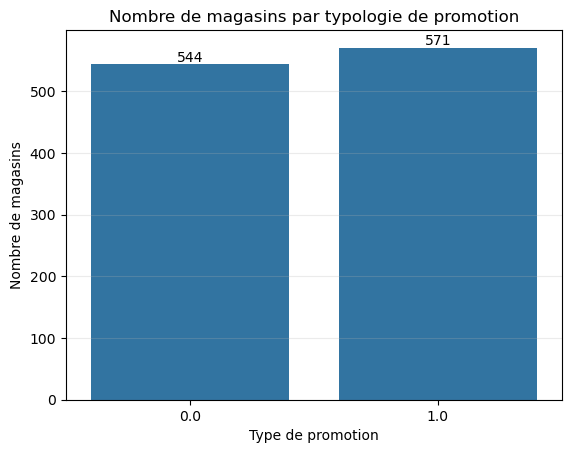

In [25]:
# Graphique en barres du nombre de magasins par type de magasin et type d'assortiment
ax = sns.barplot(x='Promo2', y='Store', data = table_assort_promo)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Nombre de magasins par typologie de promotion')
plt.xlabel('Type de promotion')
plt.ylabel('Nombre de magasins')
plt.grid(axis='y', alpha=0.25)

In [26]:
# tableau croisé dynamique des données de ventes par type de magasin
table_typo = pd.pivot_table(table_store, index=['StoreType_LabelEncoded'], values=['Sales','Customers','Open','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2','Promo2SinceWeek','Promo2SinceYear'], aggfunc='mean')
table_typo = table_typo.round(3)
table_typo = table_typo.reset_index()
table_typo = table_typo[['StoreType_LabelEncoded','Sales','Customers','Open','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2','Promo2SinceWeek','Promo2SinceYear']]
table_typo

,StoreType_LabelEncoded,Sales,Customers,Open,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
0,1,5727.014,656.345,0.829,5123.062,7.181,2008.549,0.480,24.073,2011.882
1,2,10005.497,1979.426,0.983,1060.588,6.667,2007.778,0.294,21.600,2012.800
2,3,5709.546,670.357,0.825,3522.568,7.075,2008.514,0.507,21.573,2011.547
3,4,5641.763,499.736,0.827,6913.064,7.406,2009.014,0.580,23.713,2011.649


In [27]:
# tableau croisé dynamique des données de ventes par type d'assortiment
table_assort = pd.pivot_table(table_store, index=['Assortment_LabelEncoded'], values=['Sales','Customers','Open','Promo','SchoolHoliday','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2','Promo2SinceWeek','Promo2SinceYear'], aggfunc='mean')
table_assort = table_assort.round(3)
table_assort = table_assort.reset_index()
table_assort = table_assort[['Assortment_LabelEncoded','Sales','Customers','Open','Promo','SchoolHoliday','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2','Promo2SinceWeek','Promo2SinceYear']]
table_assort

,Assortment_LabelEncoded,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
0,1,5468.452,615.164,0.828,0.38,0.177,4400.338,7.221,2008.365,0.513,24.707,2011.684
1,2,8485.839,2029.422,0.990,0.38,0.178,1177.778,7.333,2003.000,0.444,19.250,2012.750
2,3,6056.409,621.508,0.830,0.38,0.176,6638.770,7.228,2009.138,0.513,22.376,2011.840


In [28]:
# tableau croisé dynamique des données de ventes par type de promotion
table_type_assort = pd.pivot_table(table_store, index=['Type_Assort_LabelEncoded'], values=['Sales','Customers','Open','Promo','Promo2','SchoolHoliday','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2SinceWeek','Promo2SinceYear'], aggfunc='mean')
table_type_assort = table_type_assort.round(3)
table_type_assort = table_type_assort.reset_index()
table_type_assort = table_type_assort[['Type_Assort_LabelEncoded','Sales','Customers','Open','Promo','Promo2','SchoolHoliday','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2SinceWeek','Promo2SinceYear']]
table_type_assort

,Type_Assort_LabelEncoded,Sales,Customers,Open,Promo,Promo2,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2SinceWeek,Promo2SinceYear
0,1-1,5388.975,624.069,0.826,0.38,0.491,0.178,4058.661,7.339,2008.180,24.989,2011.877
1,1-3,6309.788,711.988,0.833,0.38,0.462,0.175,6966.409,6.824,2009.382,22.392,2011.892
2,2-1,10821.620,1754.343,0.971,0.38,0.143,0.180,888.571,6.333,2010.167,31.000,2013.000
3,2-2,8485.839,2029.422,0.990,0.38,0.444,0.178,1177.778,7.333,2003.000,19.250,2012.750
4,2-3,17969.560,3105.050,1.000,0.38,0.000,0.220,1210.000,NaN,NaN,NaN,NaN
5,3-1,5639.417,691.237,0.825,0.38,0.506,0.178,2710.519,7.054,2008.446,23.513,2011.256
6,3-3,5785.601,647.713,0.825,0.38,0.507,0.179,4403.239,7.098,2008.588,19.472,2011.861
7,4-1,5309.421,480.597,0.827,0.38,0.602,0.175,6661.270,6.975,2008.852,24.545,2011.416
8,4-3,5835.125,510.871,0.827,0.38,0.568,0.176,7057.273,7.659,2009.109,23.200,2011.792


In [29]:
# tableau croisé dynamique des données de ventes par type de promotion
table_promo = pd.pivot_table(table_store, index=['Promo2'], values=['Sales','Customers','Open','Promo','SchoolHoliday','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2SinceWeek','Promo2SinceYear'], aggfunc='mean')
table_promo = table_promo.round(3)
table_promo = table_promo.reset_index()
table_promo = table_promo[['Promo2','Sales','Customers','Open','Promo','SchoolHoliday','CompetitionDistance','CompetitionOpenSinceMonth','CompetitionOpenSinceYear','Promo2SinceWeek','Promo2SinceYear']]
table_promo

,Promo2,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2SinceWeek,Promo2SinceYear
0,0.0,6126.569,701.754,0.833,0.38,0.180,6549.520,7.260,2009.124,NaN,NaN
1,1.0,5417.248,560.660,0.827,0.38,0.173,4316.509,7.186,2008.175,23.595,2011.764


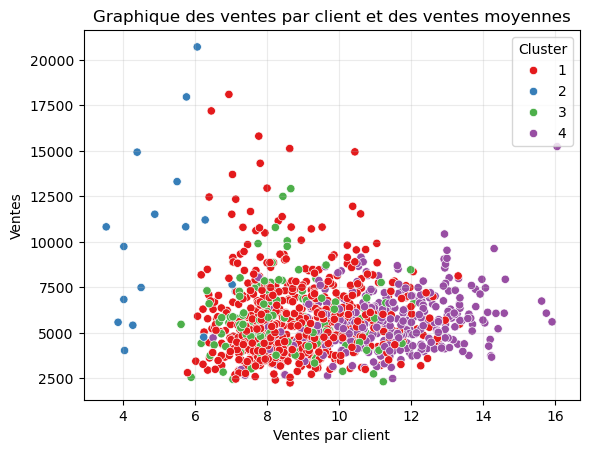

In [30]:
# Graphique nuage de point des clusters avec les variables panier moyen / ventes
sns.scatterplot(data=table_store, x="sales_customers", y="Sales", hue="StoreType_LabelEncoded",palette="Set1")
plt.legend(loc='upper right', title='Cluster')
plt.title('Graphique des ventes par client et des ventes moyennes')
plt.xlabel('Ventes par client')
plt.ylabel('Ventes')
plt.grid(axis='x', alpha=0.25)
plt.grid(axis='y', alpha=0.25)

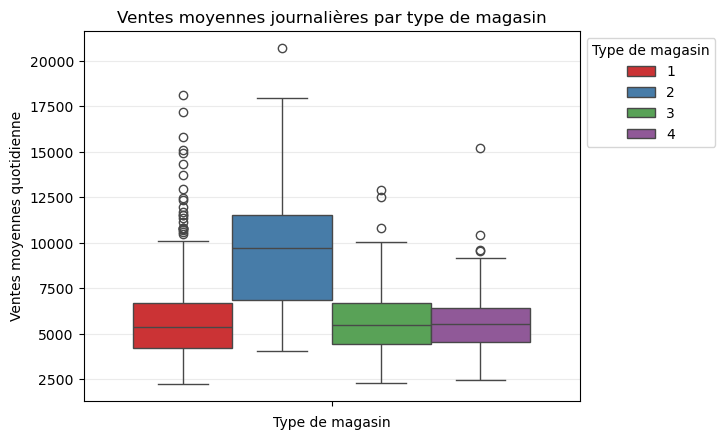

In [31]:
# boite à moustache variable ventes par type de magasin
sns.boxplot(y="Sales",hue="StoreType_LabelEncoded",palette="Set1",data = table_store)
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Type de magasin")
plt.title('Ventes moyennes journalières par type de magasin')
plt.xlabel('Type de magasin')
plt.ylabel('Ventes moyennes quotidienne')
plt.grid(axis='y', alpha=0.25)

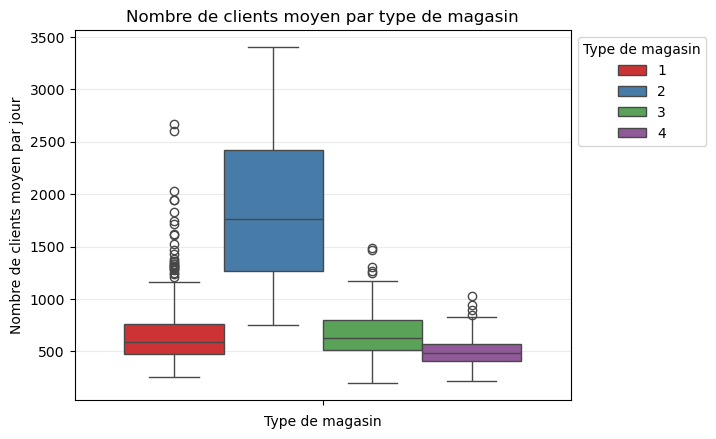

In [32]:
# boite à moustache variable clients par type de magasin
sns.boxplot(y="Customers",hue="StoreType_LabelEncoded",palette="Set1",data = table_store)
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Type de magasin")
plt.title('Nombre de clients moyen par type de magasin')
plt.xlabel('Type de magasin')
plt.ylabel('Nombre de clients moyen par jour')
plt.grid(axis='y', alpha=0.25)

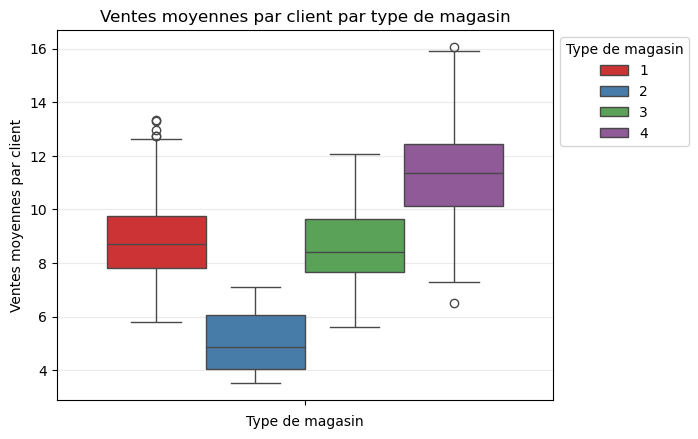

In [33]:
# boite à moustache variable ventes par type de magasin
sns.boxplot(y="sales_customers",hue="StoreType_LabelEncoded",palette="Set1",data = table_store)
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Type de magasin")
plt.title('Ventes moyennes par client par type de magasin')
plt.xlabel('Type de magasin')
plt.ylabel('Ventes moyennes par client')
plt.grid(axis='y', alpha=0.25)

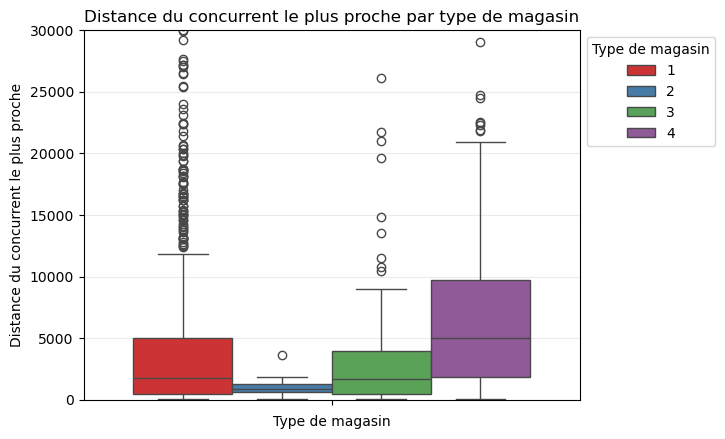

In [34]:
# boite à moustache variable clients par type de magasin
sns.boxplot(y="CompetitionDistance",hue="StoreType_LabelEncoded",palette="Set1",data = table_store)
plt.ylim(0,30000)
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Type de magasin")
plt.title('Distance du concurrent le plus proche par type de magasin')
plt.xlabel('Type de magasin')
plt.ylabel('Distance du concurrent le plus proche')
plt.grid(axis='y', alpha=0.25)

In [35]:
# Partie 2 Etude des différents types de magasins
#
# 2 - 1 : Comparaison des volumes de ventes au mois et à l'année
# 2 - 2 : Etude de corrélation des volumes de vente
# 2 - 3 : Catégorisation des magasins avec l'algorithme K-means

In [36]:
#
# 2 - 1 Comparaison des volumes de ventes à l'année
#

In [37]:
# tableau croisé dynamnique des données de ventes
table_sales = pd.pivot_table(df_modif, index=['year','month','year_month'], values='Sales', aggfunc='sum')
table_sales = table_sales.reset_index()
#table_sales

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\338407510.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Ventes totales")


([<matplotlib.axis.XTick at 0x1f7022302d0>,
 [Text(0.0, 0, '2013-1'),
  Text(6.0, 0, '2013-7'),
  Text(12.0, 0, '2014-1'),
  Text(18.0, 0, '2014-7'),
  Text(24.0, 0, '2015-1'),
  Text(30.0, 0, '2015-7')])

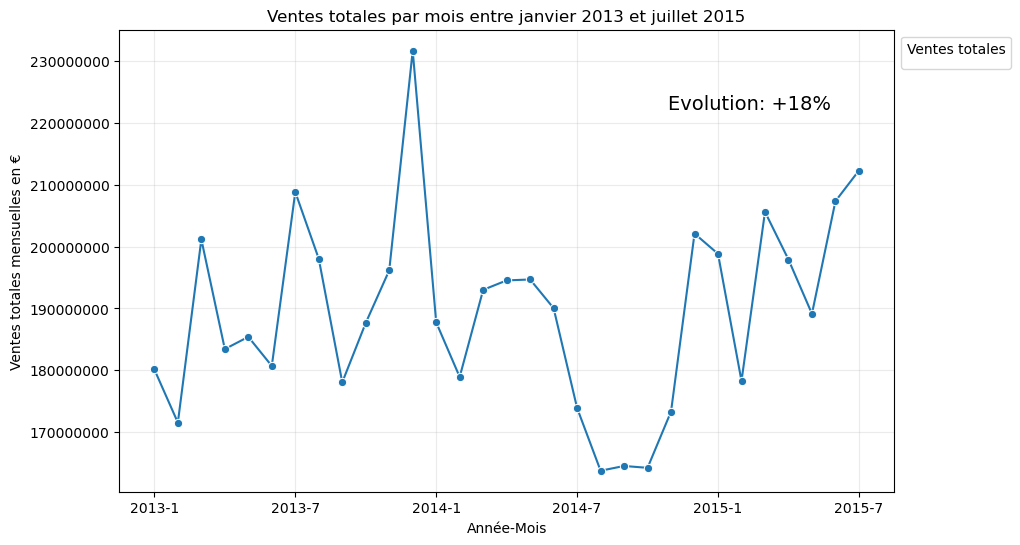

In [38]:
## Graphique comparatif des ventes par produits et par année
fig = plt.subplots(figsize=(10, 6))
sns.lineplot(x="year_month", y="Sales", marker="o", data = table_sales)
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Ventes totales")
plt.title('Ventes totales par mois entre janvier 2013 et juillet 2015')
plt.xlabel('Année-Mois')
plt.ylabel('Ventes totales mensuelles en €')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.grid(axis='x', alpha=0.25)
plt.text(1.35, 1.05, 'Evolution: +18%', fontsize=14, horizontalalignment='center',verticalalignment='center', transform=ax.transAxes)
labels = ['2013-1', '2013-7','2014-1','2014-7', '2015-1','2015-7']
plt.xticks(labels, rotation='horizontal')

In [39]:
# tableau croisé dynamnique des données de ventes
table_sales_typo = pd.pivot_table(df_modif, index=['StoreType','StoreType_LabelEncoded','year','month','year_month'], values='Sales', aggfunc='sum')
table_sales_typo = table_sales_typo.reset_index()
table_sales_typo

,StoreType,StoreType_LabelEncoded,year,month,year_month,Sales
0,a,1,2013,1,2013-1,98821318
1,a,1,2013,2,2013-2,93685217
2,a,1,2013,3,2013-3,108820294
3,a,1,2013,4,2013-4,100222624
4,a,1,2013,5,2013-5,99900140
...,...,...,...,...,...,...
119,d,4,2015,3,2015-3,63757380
120,d,4,2015,4,2015-4,61230116
121,d,4,2015,5,2015-5,58803060
122,d,4,2015,6,2015-6,64263846


([<matplotlib.axis.XTick at 0x1f7022f9bd0>,
 [Text(0.0, 0, '2013-1'),
  Text(6.0, 0, '2013-7'),
  Text(12.0, 0, '2014-1'),
  Text(18.0, 0, '2014-7'),
  Text(24.0, 0, '2015-1'),
  Text(30.0, 0, '2015-7')])

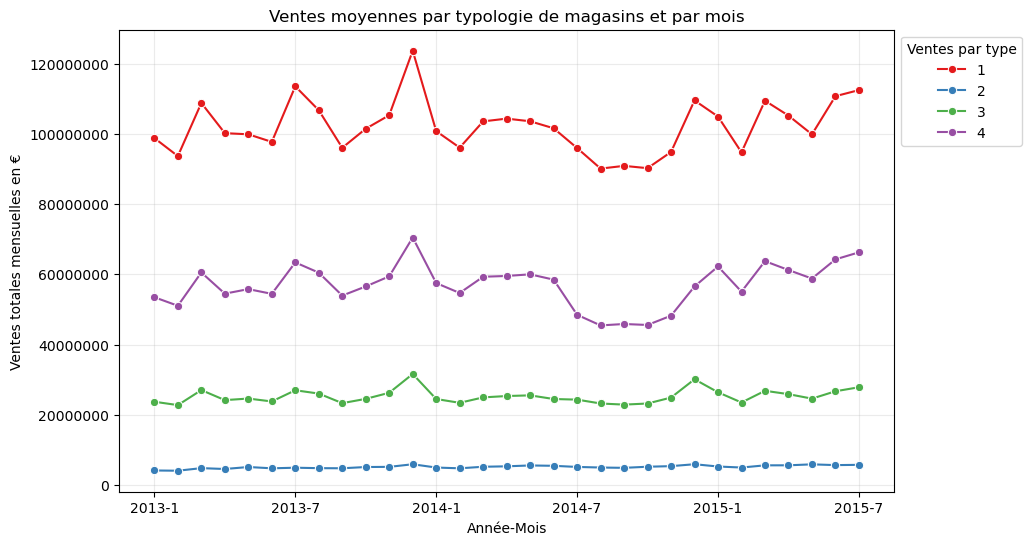

In [40]:
## graphique ventes par mois et par typologie de magasin
fig = plt.subplots(figsize=(10, 6))
sns.lineplot(x="year_month", y="Sales", marker="o", hue='StoreType_LabelEncoded',palette="Set1",data = table_sales_typo)
plt.legend(bbox_to_anchor=(1,1), loc="upper left",title = "Ventes par type")
plt.title('Ventes moyennes par typologie de magasins et par mois')
plt.xlabel('Année-Mois')
plt.ylabel('Ventes totales mensuelles en €')
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.grid(axis='x', alpha=0.25)
labels = ['2013-1', '2013-7','2014-1','2014-7', '2015-1','2015-7']
plt.xticks(labels, rotation='horizontal')

In [41]:
## identification par z-score des données abérrantes des ventes du Top 5
table_zscore = table_store
median_value = table_zscore["CompetitionDistance"].median()
table_zscore["CompetitionDistance"] = table_zscore["CompetitionDistance"].fillna(value=median_value)
table_zscore['salesmean'] = table_zscore["Sales"].mean()
table_zscore['customersmean'] = table_zscore["Customers"].mean()
table_zscore['distancemean'] = table_zscore["CompetitionDistance"].mean()
table_zscore['salesstd'] = table_zscore["Sales"].std()
table_zscore['customersstd'] = table_zscore["Customers"].std()
table_zscore['distancestd'] = table_zscore["CompetitionDistance"].std()
table_zscore["sales_z_score"] = (table_zscore["Sales"] - table_zscore['salesmean']) / table_zscore['salesstd']
table_zscore["customers_z_score"] = (table_zscore["Customers"] - table_zscore['customersmean']) / table_zscore['customersstd']
table_zscore["distance_z_score"] = (table_zscore["CompetitionDistance"] - table_zscore['distancemean']) / table_zscore['distancestd']
table_zscore["sales_z_outliers"] = np.where( ((table_zscore["sales_z_score"] < -3) | (table_zscore["sales_z_score"] > 3)), 1,0) 
table_zscore["customers_z_outliers"] = np.where( ((table_zscore["customers_z_score"] < -3) | (table_zscore["customers_z_score"] > 3)), 1,0) 
table_zscore["distance_z_outliers"] = np.where( ((table_zscore["distance_z_score"] < -3) | (table_zscore["distance_z_score"] > 3)), 1,0)

In [42]:
## comptage du nombre outliers par produit
print("- Nombre de données aberrantes pour les données sales:",len(table_zscore[table_zscore['sales_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données customers:",len(table_zscore[table_zscore['customers_z_outliers']==1]))
print("- Nombre de données aberrantes pour les données distance:",len(table_zscore[table_zscore['distance_z_outliers']==1]))

- Nombre de données aberrantes pour les données sales: 18
- Nombre de données aberrantes pour les données customers: 21
- Nombre de données aberrantes pour les données distance: 22


In [43]:
## proportion du nombre outliers par produit
print("- Pourcentage de données aberrantes pour les données sales:", round(len(table_zscore[table_zscore['sales_z_outliers']==1]) / len(table_zscore),3) )
print("- Pourcentage de données aberrantes pour les données customers:", round(len(table_zscore[table_zscore['customers_z_outliers']==1]) / len(table_zscore),3) )
print("- Pourcentage de données aberrantes pour les données distance:", round(len(table_zscore[table_zscore['distance_z_outliers']==1]) / len(table_zscore),3) )

- Pourcentage de données aberrantes pour les données sales: 0.016
- Pourcentage de données aberrantes pour les données customers: 0.019
- Pourcentage de données aberrantes pour les données distance: 0.02


In [44]:
# Suppression des données aberrantes
table_store_clean = table_zscore[table_zscore['sales_z_outliers'] != 1]
table_store_clean = table_store_clean[table_store_clean['customers_z_outliers'] != 1]
table_store_clean = table_store_clean[table_store_clean['distance_z_outliers'] != 1]
table_store_clean

,Store,Assortment_LabelEncoded,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Customers,Open,Promo,Promo2,Promo2SinceWeek,...,distancemean,salesstd,customersstd,distancestd,sales_z_score,customers_z_score,distance_z_score,sales_z_outliers,customers_z_outliers,distance_z_outliers
0,1,1,1270.0,9.0,2008.0,467.65,0.83,0.38,0.0,NaN,...,5396.61435,2046.447359,318.586374,7654.513635,-0.888183,-0.508021,-0.539109,0,0,0
1,2,1,570.0,11.0,2007.0,486.05,0.83,0.38,1.0,13.0,...,5396.61435,2046.447359,318.586374,7654.513635,-0.801550,-0.450266,-0.630558,0,0,0
2,3,1,14130.0,12.0,2006.0,620.29,0.83,0.38,1.0,14.0,...,5396.61435,2046.447359,318.586374,7654.513635,-0.010785,-0.028905,1.140946,0,0,0
3,4,3,620.0,9.0,2009.0,1100.06,0.83,0.38,0.0,NaN,...,5396.61435,2046.447359,318.586374,7654.513635,1.103595,1.477029,-0.624026,0,0,0
5,6,1,310.0,12.0,2013.0,525.99,0.83,0.38,0.0,NaN,...,5396.61435,2046.447359,318.586374,7654.513635,-0.586842,-0.324900,-0.664525,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1109,1110,3,900.0,9.0,2010.0,449.00,0.83,0.38,0.0,NaN,...,5396.61435,2046.447359,318.586374,7654.513635,-0.975520,-0.566561,-0.587446,0,0,0
1110,1111,1,1900.0,6.0,2014.0,373.55,0.83,0.38,1.0,31.0,...,5396.61435,2046.447359,318.586374,7654.513635,-0.694057,-0.803388,-0.456804,0,0,0
1111,1112,3,1880.0,4.0,2006.0,693.50,0.83,0.38,0.0,NaN,...,5396.61435,2046.447359,318.586374,7654.513635,1.320317,0.200892,-0.459417,0,0,0
1112,1113,3,9260.0,NaN,NaN,596.76,0.83,0.38,0.0,NaN,...,5396.61435,2046.447359,318.586374,7654.513635,-0.120766,-0.102762,0.504720,0,0,0


In [45]:
#
# 2 - 2  Corrélations avec la variable de volume des ventes
#

In [46]:
# préparation jeu de données pour les tables de corrélation

In [47]:
# données pour le jeu de données complet
table_correlation_complet = df_modif[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
#table_correlation_complet

In [48]:
# données pour le jeu de données des magasins
table_correlation_store = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
#table_correlation_store

In [49]:
# données pour le jeu de données des magasins nettoyé
table_correlation_store_clean = table_store_clean[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
#table_correlation_store_clean

In [50]:
# données pour le jeu de données des magasins de typologie 1
table_correlation_store_type1 = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
table_correlation_store_type1 = table_correlation_store_type1[table_correlation_store_type1['StoreType_LabelEncoded'] == 1]
#table_correlation_store_type1

In [51]:
# données pour le jeu de données des magasins de typologie 2
table_correlation_store_type2 = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
table_correlation_store_type2 = table_correlation_store_type2[table_correlation_store_type2['StoreType_LabelEncoded'] == 2]
#table_correlation_store_type2

In [52]:
# données pour le jeu de données des magasins de typologie 3
table_correlation_store_type3 = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
table_correlation_store_type3 = table_correlation_store_type3[table_correlation_store_type3['StoreType_LabelEncoded'] == 3]
#table_correlation_store_type3

In [53]:
# données pour le jeu de données des magasins de typologie 4
table_correlation_store_type4 = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
table_correlation_store_type4 = table_correlation_store_type4[table_correlation_store_type4['StoreType_LabelEncoded'] == 4]
#table_correlation_store_type4

In [54]:
# données pour le jeu de données des magasins avec promotion inactive
table_correlation_store_promo0 = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
table_correlation_store_promo0 = table_correlation_store_promo0[table_correlation_store_promo0['Promo2'] == 0]
#table_correlation_store_promo0

In [55]:
# données pour le jeu de données des magasins avec promotion active
table_correlation_store_promo1 = table_store[['Sales','Customers','Promo2','CompetitionDistance','Assortment_LabelEncoded','StoreType_LabelEncoded','sales_customers']]
table_correlation_store_promo1 = table_correlation_store_promo1[table_correlation_store_promo1['Promo2'] == 1]
#table_correlation_store_promo1

In [56]:
## matrice de correlation jeu de données complet hors dimanche
correlation_matrix_complet = table_correlation_complet.corr()
correlation_matrix_complet = correlation_matrix_complet.round(2)
#correlation_matrix_complet

In [57]:
## matrice de correlation magasin complet
correlation_matrix_store = table_correlation_store.corr()
correlation_matrix_store = correlation_matrix_store.round(2)
#correlation_matrix_store

In [58]:
## matrice de correlation magasin type 1
correlation_matrix_store_type1 = table_correlation_store_type1.corr()
correlation_matrix_store_type1 = correlation_matrix_store_type1.round(2)
#correlation_matrix_store_type1

In [59]:
## matrice de correlation magasin type 2
correlation_matrix_store_type2 = table_correlation_store_type2.corr()
correlation_matrix_store_type2 = correlation_matrix_store_type2.round(2)
#correlation_matrix_store_type2

In [60]:
## matrice de correlation magasin type 3
correlation_matrix_store_type3 = table_correlation_store_type3.corr()
correlation_matrix_store_type3 = correlation_matrix_store_type3.round(2)
#correlation_matrix_store_type3

In [61]:
## matrice de correlation magasin type 4
correlation_matrix_store_type4 = table_correlation_store_type4.corr()
correlation_matrix_store_type4 = correlation_matrix_store_type4.round(2)
#correlation_matrix_store_type4

Text(0.5, 1.0, 'Matrice de corrélation des variables')

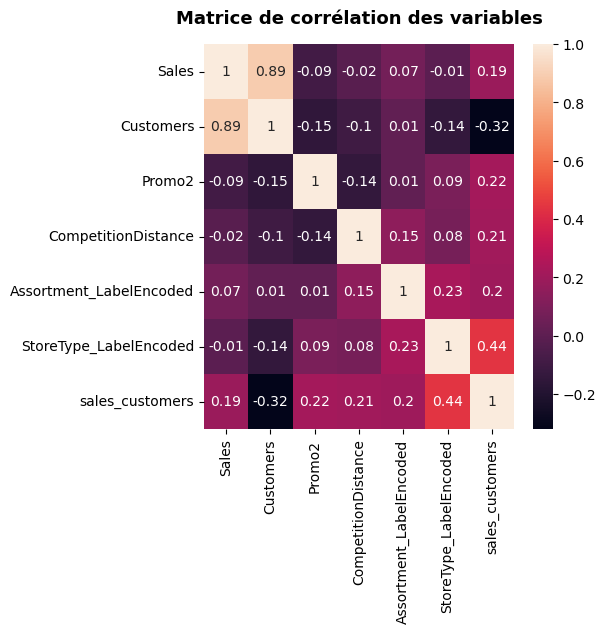

In [62]:
## matrice de correlation jeu de données complet hors dimanche
plt.figure(figsize=(5,5))
sns.heatmap(correlation_matrix_complet, annot=True)
plt.title("Matrice de corrélation des variables", fontsize = 13, weight='bold', pad=15, loc = 'center')

Text(0.5, 1.0, 'Matrice de corrélation des principales variables')

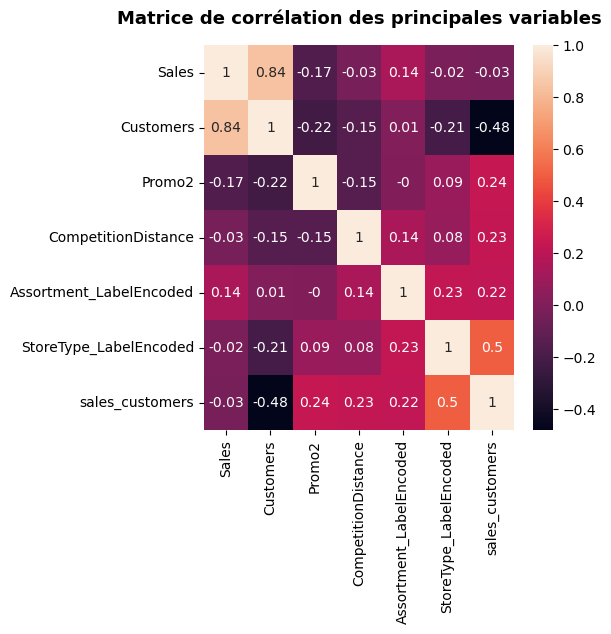

In [63]:
## matrice de correlation magasins complet
plt.figure(figsize=(5,5))
sns.heatmap(correlation_matrix_store, annot=True)
plt.title("Matrice de corrélation des principales variables", fontsize = 13, weight='bold', pad=15, loc = 'center')

Text(0.5, 1.0, 'Matrice de corrélation des variables')

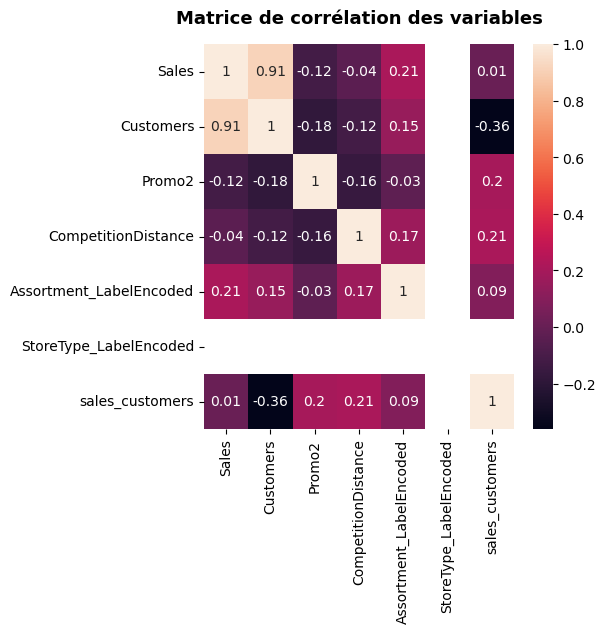

In [64]:
## matrice de correlation magasins type 1
plt.figure(figsize=(5,5))
sns.heatmap(correlation_matrix_store_type1, annot=True)
plt.title("Matrice de corrélation des variables", fontsize = 13, weight='bold', pad=15, loc = 'center')

Text(0.5, 1.0, 'Matrice de corrélation des variables')

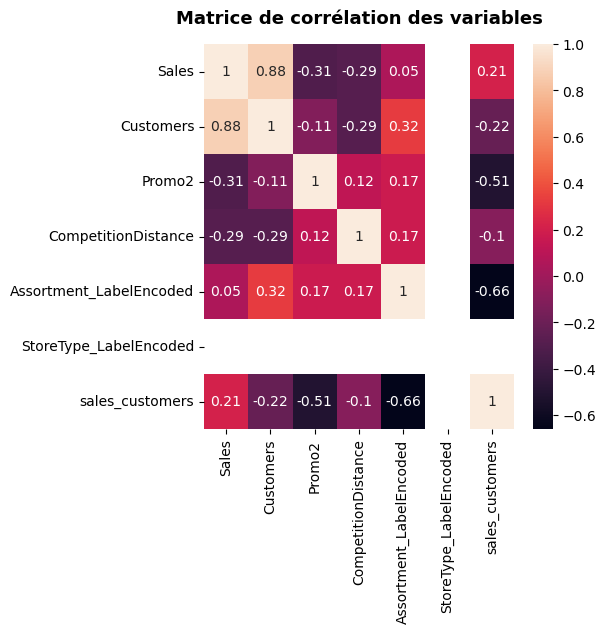

In [65]:
## matrice de correlation magasins type 2
plt.figure(figsize=(5,5))
sns.heatmap(correlation_matrix_store_type2, annot=True)
plt.title("Matrice de corrélation des variables", fontsize = 13, weight='bold', pad=15, loc = 'center')

Text(0.5, 1.0, 'Matrice de corrélation des variables')

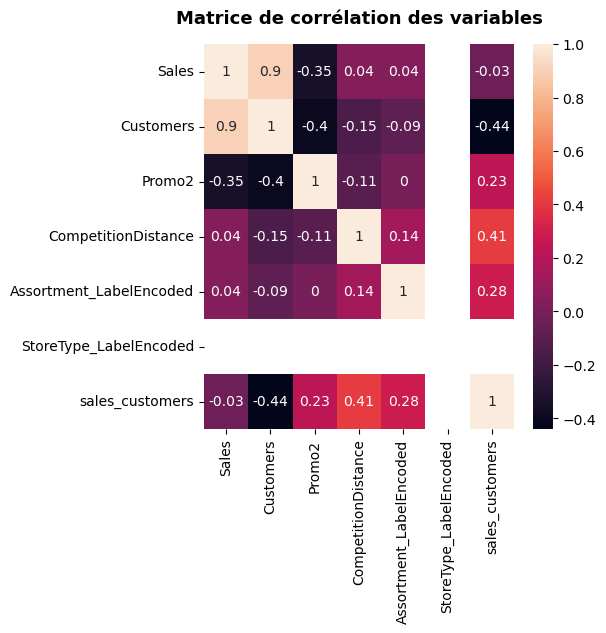

In [66]:
## matrice de correlation magasins type 3
plt.figure(figsize=(5,5))
sns.heatmap(correlation_matrix_store_type3, annot=True)
plt.title("Matrice de corrélation des variables", fontsize = 13, weight='bold', pad=15, loc = 'center')

Text(0.5, 1.0, 'Matrice de corrélation des variables')

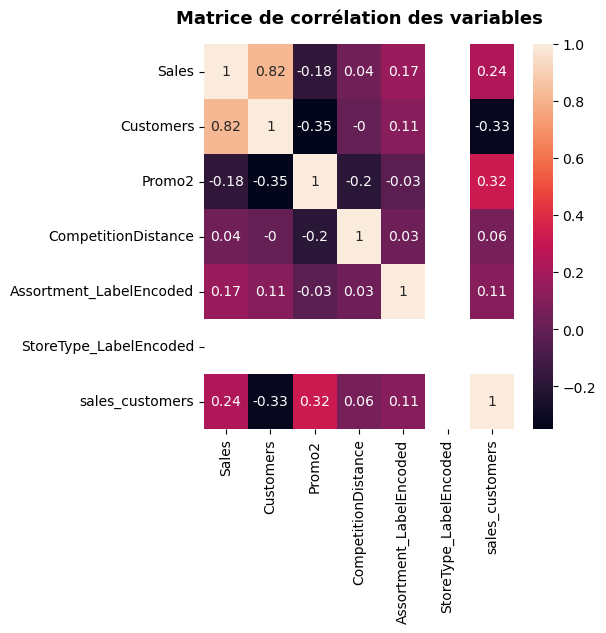

In [67]:
## matrice de correlation magasins type 4
plt.figure(figsize=(5,5))
sns.heatmap(correlation_matrix_store_type4, annot=True)
plt.title("Matrice de corrélation des variables", fontsize = 13, weight='bold', pad=15, loc = 'center')

In [68]:
#
# Graphique de corrélation
#

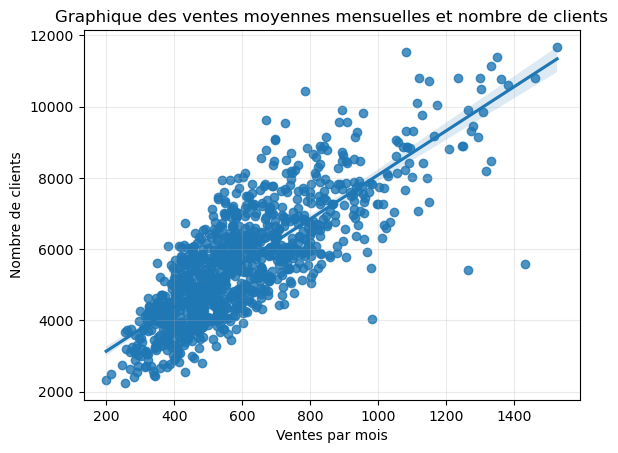

In [69]:
## Graphique nuage de points nombre de clients par jour / ventes quotidiennes moyennes
sns.regplot(data=table_store_clean, x="Customers", y="Sales")
plt.title('Graphique des ventes moyennes mensuelles et nombre de clients')
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel('Ventes par mois')
plt.ylabel('Nombre de clients')
plt.grid(axis='y', alpha=0.25)
plt.grid(axis='x', alpha=0.25)

In [70]:
# Calcul des données de régression linéaire clients / ventes 
x = table_store_clean['Customers']
y = table_store_clean['Sales']
slope, intercept, r, p, std_err = stats.linregress(x, y)

# Données de régression linéaire clients / ventes 
print('Statistiques de la régression linéaire')
print('--------------------------------------')
print('Pente:', round(slope,2))
print('Origine:',round(intercept,2))
print('                                      ')
print('Coefficient de détermination:',round(r,3))
print('p value:',p)
print('Ecart Type:',round(std_err,3))
print('--------------------------------------')

Statistiques de la régression linéaire
--------------------------------------
Pente: 6.18
Origine: 1903.75
                                      
Coefficient de détermination: 0.801
p value: 1.7290413594678771e-239
Ecart Type: 0.142
--------------------------------------


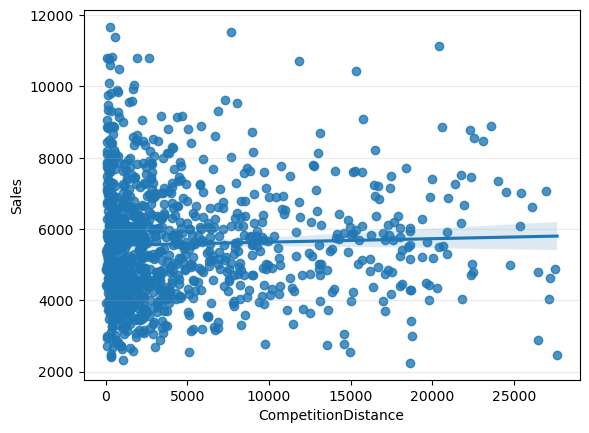

In [71]:
## Graphique nuage de points : distance magasin concurrent / ventes quotidiennes moyennes
sns.regplot(data=table_store_clean, x="CompetitionDistance", y="Sales")
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.ticklabel_format(style='plain', axis='x')

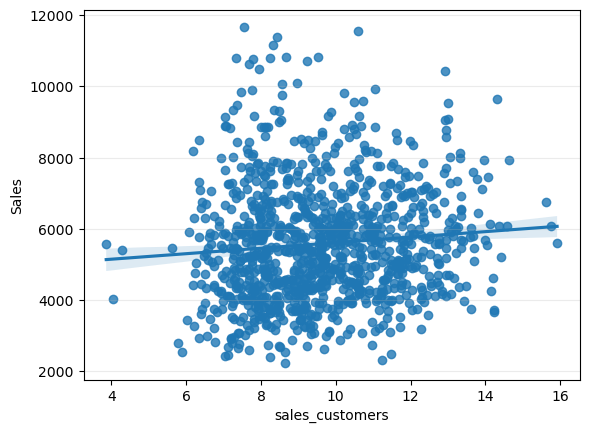

In [72]:
## Graphique nuage de points ventes par client / ventes quotidiennes moyennes
sns.regplot(data=table_store_clean, x="sales_customers", y="Sales")
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.ticklabel_format(style='plain', axis='x')

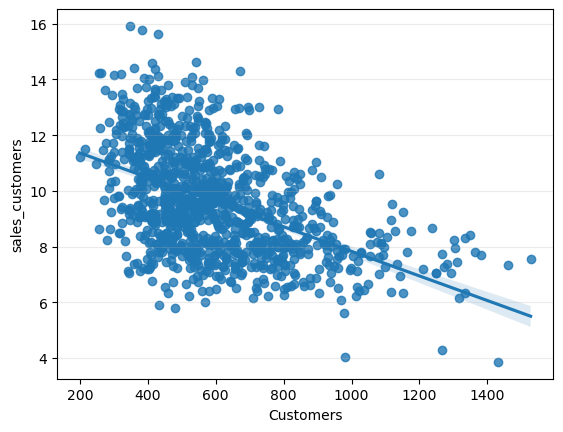

In [73]:
## Graphique nuage de points : nombre de clients moyen par jour / ventes par client
sns.regplot(data=table_store_clean, x="Customers", y="sales_customers")
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.ticklabel_format(style='plain', axis='x')

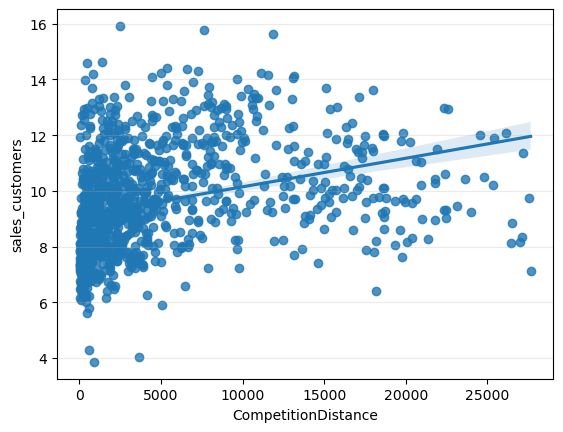

In [74]:
## Graphique nuage de points distance magasin concurrent / nombre de clients moyen par jour
sns.regplot(data=table_store_clean, x="CompetitionDistance", y="sales_customers")
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.ticklabel_format(style='plain', axis='x')

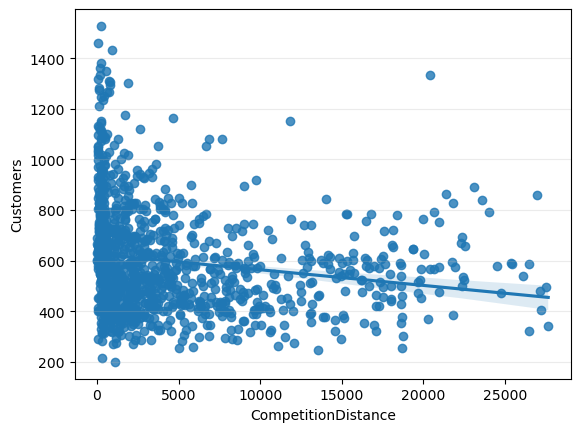

In [75]:
## Graphique nuage de points distance magasin concurrent / nombre de clients moyen par jour
sns.regplot(data=table_store_clean, x="CompetitionDistance", y="Customers")
plt.ticklabel_format(style='plain', axis='y')
plt.grid(axis='y', alpha=0.25)
plt.ticklabel_format(style='plain', axis='x')

In [76]:
#
# 2 - 3 : Catégorisation des magasins
#

In [77]:
# Sélection des variables pour la clusterisation
X = table_store[['Sales','Customers','CompetitionDistance','sales_customers']]
X = pd.DataFrame(X)
X['CompetitionDistance'] = X['CompetitionDistance'].fillna((X['CompetitionDistance'].median()))
X

,Sales,Customers,CompetitionDistance,sales_customers
0,3945.70,467.65,1270.0,8.39
1,4122.99,486.05,570.0,8.41
2,5741.25,620.29,14130.0,9.12
3,8021.77,1100.06,620.0,7.25
4,3867.11,444.36,29910.0,8.61
...,...,...,...,...
1110,4342.97,373.55,1900.0,11.55
1111,8465.28,693.50,1880.0,11.99
1112,5516.18,596.76,9260.0,9.21
1113,17200.20,2664.06,870.0,6.45


In [78]:
# Standardisation des données de 0 à 1
X = (X - X.min()) / (X.max() - X.min())
X

,Sales,Customers,CompetitionDistance,sales_customers
0,0.092086,0.083799,0.016482,0.387869
1,0.101683,0.089541,0.007252,0.389465
2,0.189279,0.131435,0.186050,0.446129
3,0.312724,0.281160,0.007911,0.296887
4,0.087832,0.076531,0.394119,0.405427
...,...,...,...,...
1110,0.113590,0.054433,0.024789,0.640064
1111,0.336731,0.154282,0.024525,0.675180
1112,0.177096,0.124091,0.121835,0.453312
1113,0.809553,0.769250,0.011208,0.233041


In [79]:
# Identification du nombre de clusters avec la méthode du coude
inertie_list = [ ]
i_list = range(1, 10) 
for i in i_list :     
    kmeans = KMeans(n_clusters=i)   
    kmeans.fit(X)    
    inertie_list.append(kmeans.inertia_)

C:\Users\Ced\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\Ced\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\Ced\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
C:\Users\Ced\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with M

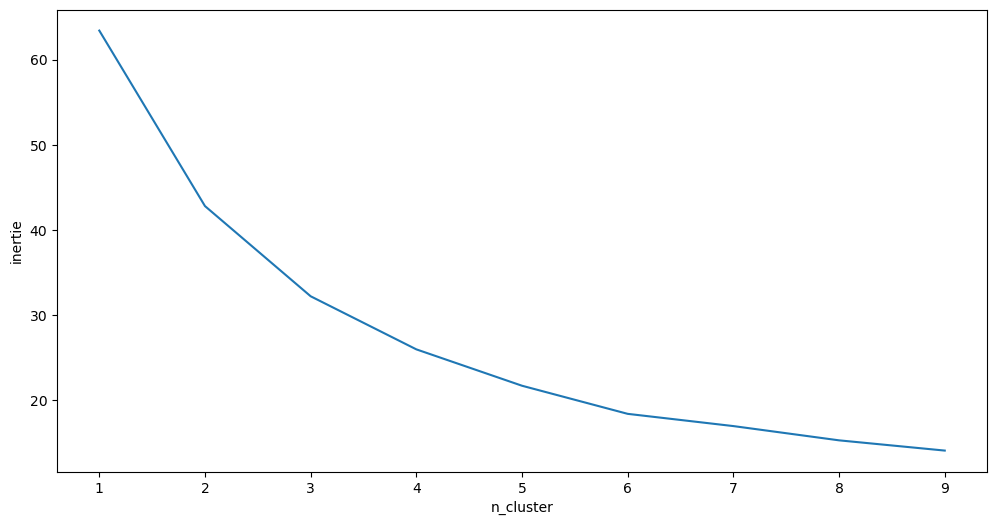

In [80]:
# Graphique du nombre de clusters optimal
fig, ax = plt.subplots(1,1,figsize=(12,6))
ax.set_ylabel("inertie")
ax.set_xlabel("n_cluster")
ax = plt.plot(i_list, inertie_list)

In [81]:
# Entrainement algorithme Kmeans
kmeans = KMeans(n_clusters=5, max_iter = 1000, random_state = 42)
kmeans.fit(X)

C:\Users\Ced\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


,n_clusters,5
,init,'k-means++'
,n_init,'auto'
,max_iter,1000
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [82]:
# Modofication des étiquettes de données
kmeans.labels_
liste_labels_modif = {i:j for i,j in enumerate(list("12345"))}
labels = [liste_labels_modif[i] for i in kmeans.labels_]

In [83]:
# table des centres des clusters par rapport au variables
cluster_centroids = kmeans.cluster_centers_
cluster_centroids

array([[0.1211435 , 0.10090369, 0.0308479 , 0.40061213],
       [0.61709078, 0.59927673, 0.00749934, 0.2561519 ],
       [0.1790247 , 0.11671638, 0.29999907, 0.48828076],
       [0.2738972 , 0.22151629, 0.02529344, 0.36183504],
       [0.18770606, 0.08808484, 0.07591161, 0.660714  ]])

In [84]:
# Fusion des étiquettes de données sur le jeu de données magasin
X["cluster"] = labels
X['Store'] = X.index + 1
X = X[['Store','cluster','Sales','Customers','CompetitionDistance','sales_customers']]
X

,Store,cluster,Sales,Customers,CompetitionDistance,sales_customers
0,1,1,0.092086,0.083799,0.016482,0.387869
1,2,1,0.101683,0.089541,0.007252,0.389465
2,3,3,0.189279,0.131435,0.186050,0.446129
3,4,4,0.312724,0.281160,0.007911,0.296887
4,5,3,0.087832,0.076531,0.394119,0.405427
...,...,...,...,...,...,...
1110,1111,5,0.113590,0.054433,0.024789,0.640064
1111,1112,5,0.336731,0.154282,0.024525,0.675180
1112,1113,1,0.177096,0.124091,0.121835,0.453312
1113,1114,2,0.809553,0.769250,0.011208,0.233041


In [85]:
# Nombre de magasins par cluster
X['cluster'].value_counts().sort_index()

cluster
1    392
2     24
3    114
4    232
5    353
Name: count, dtype: int64

In [86]:
# Calcul du score de silhouette
silhouette_value = silhouette_score(X, kmeans.labels_)
print("Silhouette Score:", silhouette_value)

Silhouette Score: -0.14286728147447197


In [87]:
# Calcul du score davis bouldin
davies_bouldin_value = davies_bouldin_score(X, kmeans.labels_)
print("davies_bouldin_score:", davies_bouldin_value)

davies_bouldin_score: 73.05866055190653


In [88]:
# dataframe des centres des clusters
df_centroids = pd.DataFrame(cluster_centroids)
df_centroids

,0,1,2,3
0,0.121143,0.100904,0.030848,0.400612
1,0.617091,0.599277,0.007499,0.256152
2,0.179025,0.116716,0.299999,0.488281
3,0.273897,0.221516,0.025293,0.361835
4,0.187706,0.088085,0.075912,0.660714


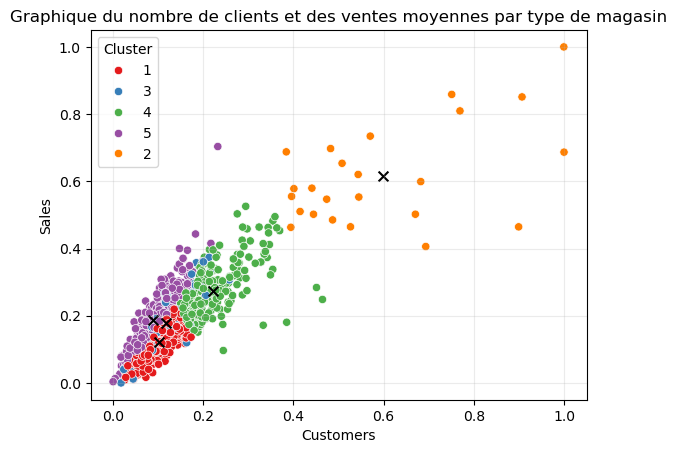

In [89]:
# Graphique nuage de point des clusters avec les variables nombre de clients / ventes
ax = sns.scatterplot(data=X, x="Customers", y="Sales", hue="cluster",palette="Set1")
ax.legend(loc="upper left", title="Cluster")
plt.title('Graphique du nombre de clients et des ventes moyennes par type de magasin')
plt.scatter(df_centroids[1][0], df_centroids[0][0], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][1], df_centroids[0][1], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][2], df_centroids[0][2], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][3], df_centroids[0][3], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][4], df_centroids[0][4], c='black',marker='x', s=50)
plt.grid(axis='x', alpha=0.25)
plt.grid(axis='y', alpha=0.25)

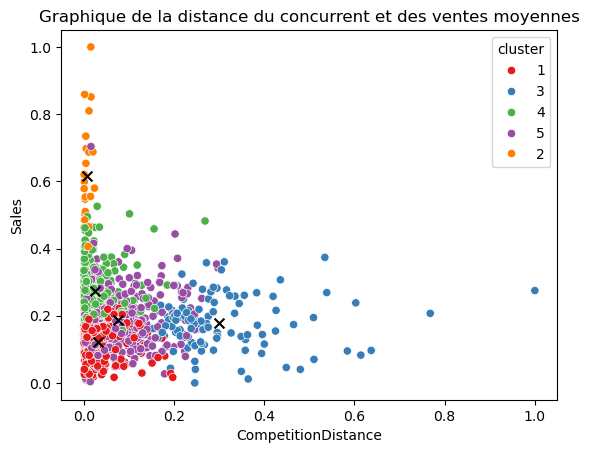

In [90]:
# Graphique nuage de point des clusters avec les variables distance du concurrent / ventes
sns.scatterplot(data=X, x="CompetitionDistance", y="Sales", hue="cluster",palette="Set1")
#plt.legend([1,2,3,4], loc='upper right', title='Type magasin')
plt.title('Graphique de la distance du concurrent et des ventes moyennes')
plt.scatter(df_centroids[2][0], df_centroids[0][0], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][1], df_centroids[0][1], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][2], df_centroids[0][2], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][3], df_centroids[0][3], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][4], df_centroids[0][4], c='black',marker='x', s=50)

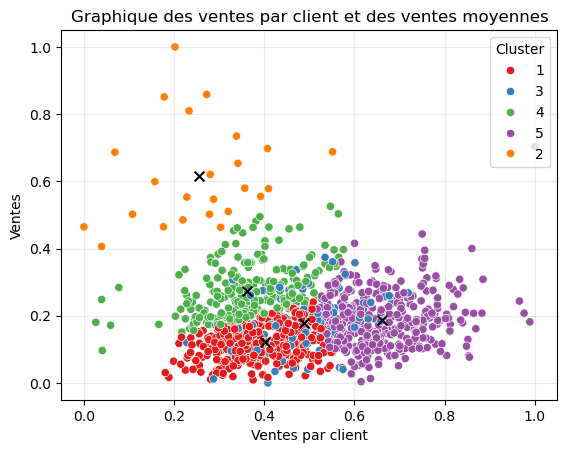

In [91]:
# Graphique nuage de point des clusters avec les variables panier moyen / ventes
sns.scatterplot(data=X, x="sales_customers", y="Sales", hue="cluster",palette="Set1")
plt.legend(loc='upper right', title='Cluster')
plt.title('Graphique des ventes par client et des ventes moyennes')
plt.xlabel('Ventes par client')
plt.ylabel('Ventes')
plt.grid(axis='x', alpha=0.25)
plt.grid(axis='y', alpha=0.25)
plt.scatter(df_centroids[3][0], df_centroids[0][0], c='black',marker='x', s=50)
plt.scatter(df_centroids[3][1], df_centroids[0][1], c='black',marker='x', s=50)
plt.scatter(df_centroids[3][2], df_centroids[0][2], c='black',marker='x', s=50)
plt.scatter(df_centroids[3][3], df_centroids[0][3], c='black',marker='x', s=50)
plt.scatter(df_centroids[3][4], df_centroids[0][4], c='black',marker='x', s=50)

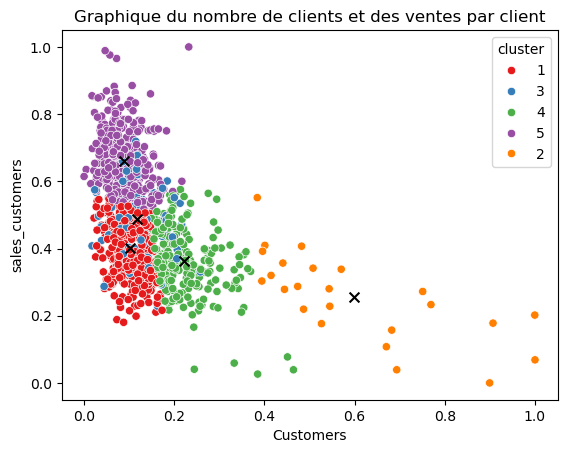

In [92]:
# Graphique nuage de point des clusters avec les variables panier moyen / nombre de clients
sns.scatterplot(data=X, x="Customers", y="sales_customers", hue="cluster",palette="Set1")
#plt.legend([1,2,3,4], loc='upper right', title='Type magasin')
plt.title('Graphique du nombre de clients et des ventes par client')
plt.scatter(df_centroids[1][0], df_centroids[3][0], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][1], df_centroids[3][1], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][2], df_centroids[3][2], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][3], df_centroids[3][3], c='black',marker='x', s=50)
plt.scatter(df_centroids[1][4], df_centroids[3][4], c='black',marker='x', s=50)

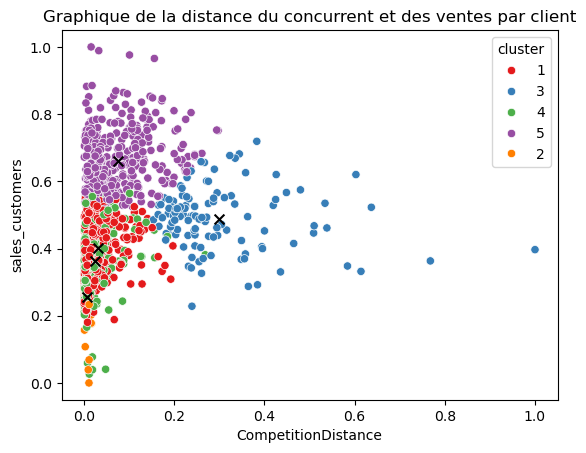

In [93]:
# Graphique nuage de point des clusters avec les variables distance du concurrent / panier moyen par client
sns.scatterplot(data=X, x="CompetitionDistance", y="sales_customers", hue="cluster",palette="Set1")
#plt.legend([1,2,3,4], loc='upper right', title='Type magasin')
plt.title('Graphique de la distance du concurrent et des ventes par client')
plt.scatter(df_centroids[2][0], df_centroids[3][0], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][1], df_centroids[3][1], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][2], df_centroids[3][2], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][3], df_centroids[3][3], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][4], df_centroids[3][4], c='black',marker='x', s=50)

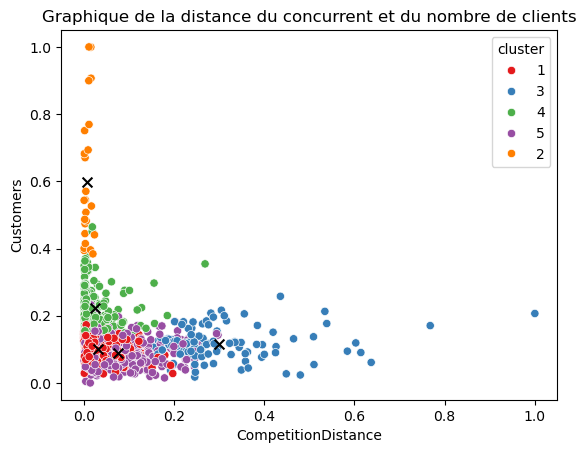

In [94]:
# Graphique nuage de point des clusters avec les variables distance du concurrent / nombre de clients
sns.scatterplot(data=X, x="CompetitionDistance", y="Customers", hue="cluster",palette="Set1")
#plt.legend([1,2,3,4], loc='upper right', title='Type magasin')
plt.title('Graphique de la distance du concurrent et du nombre de clients')
plt.scatter(df_centroids[2][0], df_centroids[1][0], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][1], df_centroids[1][1], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][2], df_centroids[1][2], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][3], df_centroids[1][3], c='black',marker='x', s=50)
plt.scatter(df_centroids[2][4], df_centroids[1][4], c='black',marker='x', s=50)

In [95]:
# Partie 3 Modèle de prévision des ventes
#
# 3 - 1 : Préparation du jeu de données
# 3 - 2 : Entrainement d'un modèle sur les groupes de magasins
# 3 - 3 : Deuxième approche de modélisation

In [96]:
# 3 - 1 : Préparation du jeu de données

In [97]:
# liste des jours fériés sans ventes
list_holidays = ['2013-01-01','2014-01-01','2015-01-01',
                 '2013-03-29','2014-04-18','2014-04-21','2015-04-03','2015-04-06',
                 '2013-05-01','2014-05-01','2015-05-01',
                '2013-05-09','2013-05-20','2014-05-29','2015-05-14','2015-05-25','2014-06-09',
                '2013-10-03','2014-10-03','2013-11-01','2014-11-01',
                '2013-12-25','2014-12-25','2013-12-26','2014-12-26']

In [98]:
## préparation des données de ventes totales
df_forecast = df_merge
df_forecast = df_forecast[['Date','DayOfWeek','Sales']]
df_forecast['Sales_day'] = df_modif.groupby(['Date'])['Sales'].transform('sum')
df_forecast = df_forecast[df_forecast['DayOfWeek'] != 7]
df_forecast = df_forecast[~df_forecast['Date'].isin(list_holidays)]
df_forecast = df_forecast[['Date','Sales_day']]
df_forecast = df_forecast.drop_duplicates(subset=['Date'],keep='first')
#df_forecast = df_forecast.dropna()
df_forecast['Sales_day'] = df_forecast['Sales_day'].fillna(0)
df_forecast = df_forecast.reset_index(drop=True)
df_forecast

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\2310824517.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_forecast['Sales_day'] = df_modif.groupby(['Date'])['Sales'].transform('sum')
C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\2310824517.py:6: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_forecast = df_forecast[~df_forecast['Date'].isin(list_holidays)]


,Date,Sales_day
0,2013-01-02,6949829
1,2013-01-03,6347820
2,2013-01-04,6638954
3,2013-01-05,5951593
4,2013-01-07,10826848
...,...,...
778,2015-07-27,10707292
779,2015-07-28,9115073
780,2015-07-29,8499962
781,2015-07-30,8798854


In [99]:
# 3 - 2 : Entrainement d'un modèle sur les groupes de magasins

In [100]:
# Calcul de la moyenne mobile 15 jours
df_rolling_sales = df_forecast
df_rolling_sales['SMA_15'] = df_rolling_sales['Sales_day'].rolling(window=15).mean()
df_rolling_sales = df_rolling_sales.dropna()
df_rolling_sales = df_rolling_sales.reset_index(drop=True)
df_rolling_sales

,Date,Sales_day,SMA_15
0,2013-01-18,6137010,6.882356e+06
1,2013-01-19,6010192,6.819713e+06
2,2013-01-21,8761074,6.980597e+06
3,2013-01-22,8320289,7.092686e+06
4,2013-01-23,7746563,7.212351e+06
...,...,...,...
764,2015-07-27,10707292,7.657365e+06
765,2015-07-28,9115073,7.794043e+06
766,2015-07-29,8499962,7.943239e+06
767,2015-07-30,8798854,7.807078e+06


In [101]:
# Calcul de la prévision moyenne mobile 15 jours : dernière donnée
next_forecast = df_rolling_sales['SMA_15'].iloc[-1]
print(next_forecast)

7858366.8


In [102]:
# modification des données pour le graphique de visualisation
df_rolling_sales_forecast = df_rolling_sales
df_forecast_list = pd.date_range(start="8/1/2015", periods=153)
df_forecast_rolling = pd.DataFrame(df_forecast_list)
df_forecast_rolling = df_forecast_rolling.rename(columns={0: 'Date'})
df_forecast_rolling['Sales_day'] = np.nan
df_forecast_rolling['SMA_15'] = next_forecast
df_rolling_sales = pd.concat([df_rolling_sales,df_forecast_rolling], ignore_index=True)

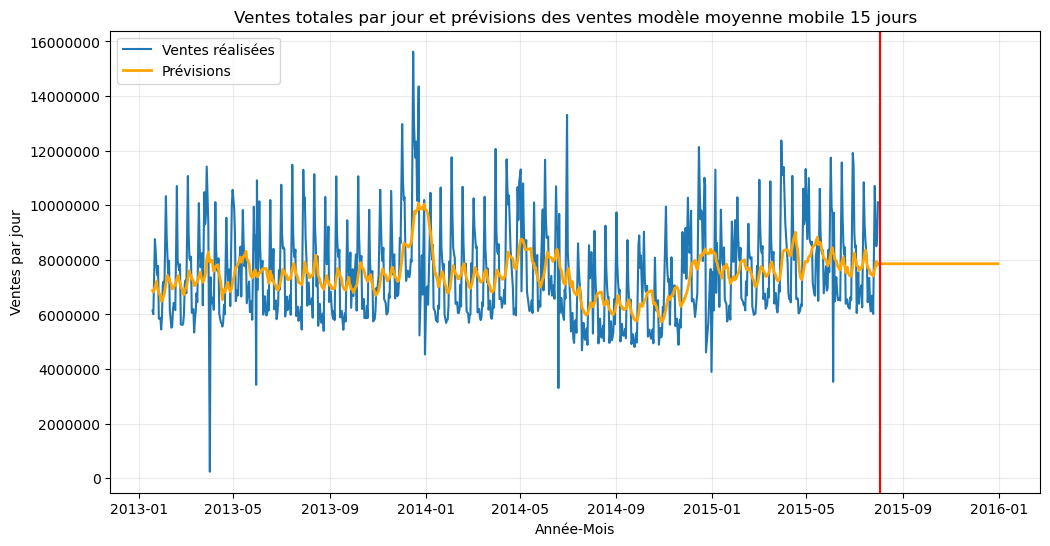

In [103]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_rolling_sales['Date'],df_rolling_sales['Sales_day'], label='Ventes réalisées')
plt.plot(df_rolling_sales['Date'],df_rolling_sales['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours")
plt.xlabel("Année-Mois")
plt.ylabel("Ventes par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.grid(axis='x', alpha=0.25)
plt.axvline(x = 16650, color = 'r',)
plt.show()

In [104]:
# 3 - 3 : Deuxième approche de modélisation

In [105]:
## Entrainement du modèle de prévision avec l'algorithme SARIMAX
p, d, q = 4, 1, 1
P, D, Q, s = 4, 1, 1, 6
model = SARIMAX(df_forecast['Sales_day'], order=(p, d, q), seasonal_order=(P, D, Q, s))
model_sarima = model.fit()

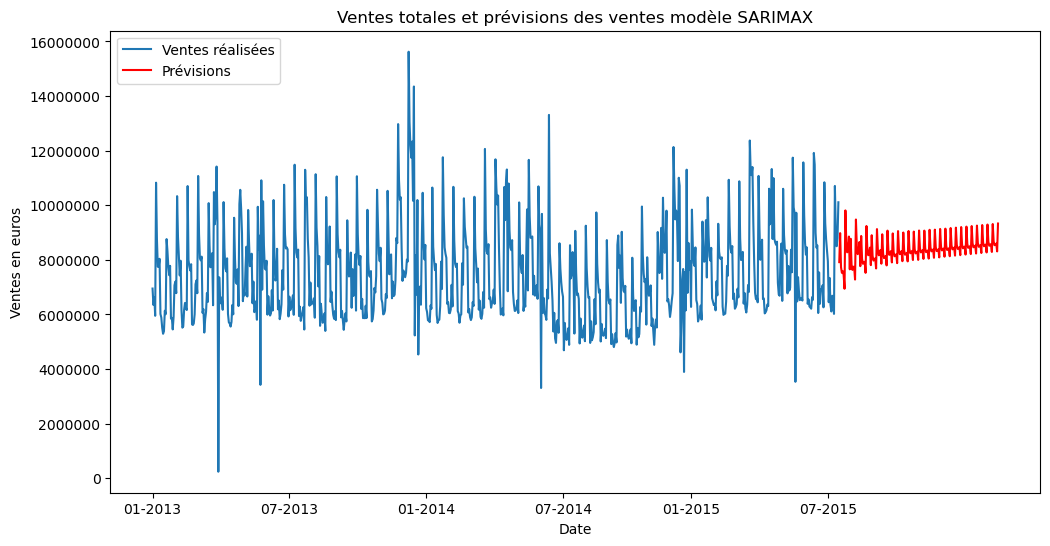

In [106]:
# Graphique des ventes et prévisions du modèle SARIMAX
forecast_periods = 182
forecast_sales = model_sarima.forecast(steps=forecast_periods)
plt.figure(figsize=(12, 6))
plt.ticklabel_format(style='plain', axis='y')
plt.plot(df_forecast['Sales_day'], label='Ventes réalisées')
plt.plot(forecast_sales, label='Prévisions', color='red')
plt.title("Ventes totales et prévisions des ventes modèle SARIMAX")
plt.xlabel("Date")
plt.ylabel("Ventes en euros")
plt.legend(loc="upper left")
x_ticks = [0,156,312,468,614,770]
x_labels = ['01-2013','07-2013','01-2014','07-2014','01-2015','07-2015'] 
plt.xticks(ticks=x_ticks, labels=x_labels)
plt.show()

In [107]:
#
# Prévision prophet
#

In [108]:
## Préparation des données pour le modèle facebook prophet
df_prophet = df_forecast
df_prophet = df_prophet[['Date','Sales_day']]
df_prophet.columns = ["ds", "y"]
df_prophet

,ds,y
0,2013-01-02,6949829
1,2013-01-03,6347820
2,2013-01-04,6638954
3,2013-01-05,5951593
4,2013-01-07,10826848
...,...,...
778,2015-07-27,10707292
779,2015-07-28,9115073
780,2015-07-29,8499962
781,2015-07-30,8798854


In [109]:
# Modèlisation de la prévision avec l'algorithme Facebook Prophet
m = Prophet()
m.add_country_holidays(country_name='FR')
m.fit(df_prophet)
future = m.make_future_dataframe(periods=153)
forecast = m.predict(future)

16:10:47 - cmdstanpy - INFO - Chain [1] start processing
16:10:48 - cmdstanpy - INFO - Chain [1] done processing


In [110]:
#show(forecast)

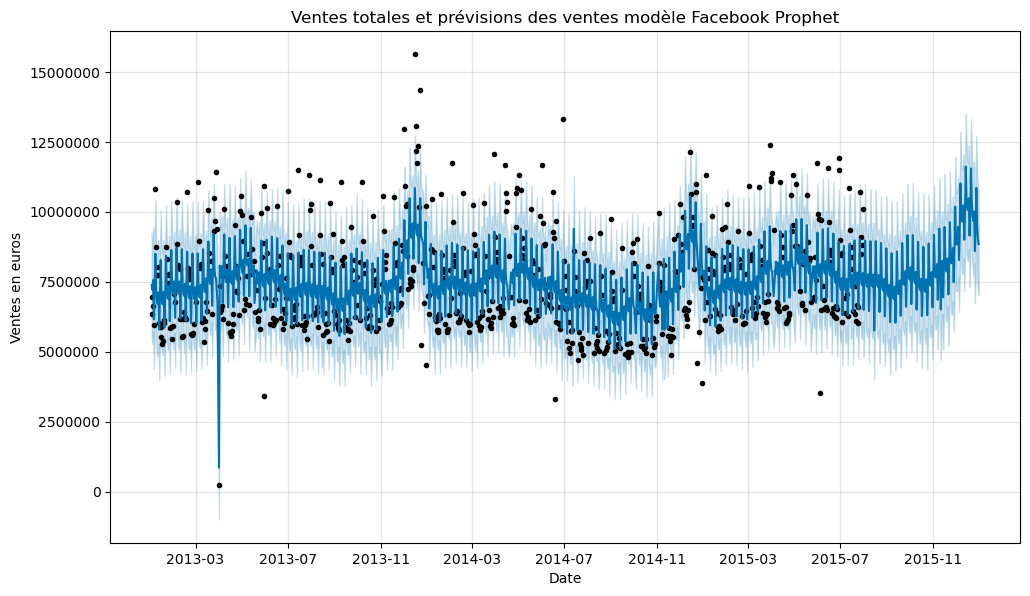

In [111]:
# Graphique des prévisions de ventes du modèle Facebook Prophet
m.plot(forecast)
plt.title("Ventes totales et prévisions des ventes modèle Facebook Prophet")
plt.xlabel("Date")
plt.ylabel("Ventes en euros")
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [112]:
#fig_components = m.plot_components(forecast)

In [113]:
#
# Prévisions par type de magasins 1/2/3/4/5
#

In [114]:
df_clusterid = X
df_clusterid = df_clusterid[['Store','cluster']]
#df_clusterid

In [115]:
# Préparation des données
df_merge_cluster = pd.merge(df_modif, df_clusterid, on='Store', how='left')
df_merge_cluster = df_merge_cluster[['Store','DayOfWeek','Date','Sales','cluster']]
df_merge_cluster['cluster'] = pd.to_numeric(df_merge_cluster.cluster, errors='coerce')
#df_merge_cluster

In [116]:
# table de données des magasins de type 1
df_cluster_type1 = df_merge_cluster
df_cluster_type1 = df_cluster_type1[df_cluster_type1['cluster'] == 1]
df_cluster_type1 = df_cluster_type1[~df_cluster_type1['Date'].isin(list_holidays)]
df_cluster_type1 = df_cluster_type1[['Date','DayOfWeek','Sales']]
df_cluster_type1['Sales_day'] = df_cluster_type1.groupby(['Date'])['Sales'].transform('sum')
df_cluster_type1 = df_cluster_type1[df_cluster_type1['DayOfWeek'] != 7]
df_cluster_type1 = df_cluster_type1[['Date','Sales_day']]
df_cluster_type1 = df_cluster_type1.drop_duplicates(subset=['Date'],keep='first')
df_cluster_type1 = df_cluster_type1.dropna()
df_cluster_type1 = df_cluster_type1.sort_values(by='Date', ascending=True) 
df_cluster_type1 = df_cluster_type1.reset_index(drop=True)
#df_cluster_type1

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\2600909962.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_cluster_type1 = df_cluster_type1[~df_cluster_type1['Date'].isin(list_holidays)]


In [117]:
# table de données des magasins de type 2
df_cluster_type2 = df_merge_cluster
df_cluster_type2 = df_cluster_type2[df_cluster_type2['cluster'] == 2]
df_cluster_type2 = df_cluster_type2[~df_cluster_type2['Date'].isin(list_holidays)]
df_cluster_type2 = df_cluster_type2[['Date','DayOfWeek','Sales']]
df_cluster_type2['Sales_day'] = df_cluster_type2.groupby(['Date'])['Sales'].transform('sum')
df_cluster_type2 = df_cluster_type2[df_cluster_type2['DayOfWeek'] != 7]
df_cluster_type2 = df_cluster_type2[['Date','Sales_day']]
df_cluster_type2 = df_cluster_type2.drop_duplicates(subset=['Date'],keep='first')
df_cluster_type2 = df_cluster_type2.dropna()
df_cluster_type2 = df_cluster_type2.sort_values(by='Date', ascending=True) 
df_cluster_type2 = df_cluster_type2.reset_index(drop=True)
#df_cluster_type2

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\431313837.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_cluster_type2 = df_cluster_type2[~df_cluster_type2['Date'].isin(list_holidays)]


In [118]:
# table de données des magasins de type 3
df_cluster_type3 = df_merge_cluster
df_cluster_type3 = df_cluster_type3[df_cluster_type3['cluster'] == 3]
df_cluster_type3 = df_cluster_type3[~df_cluster_type3['Date'].isin(list_holidays)]
df_cluster_type3 = df_cluster_type3[['Date','DayOfWeek','Sales']]
df_cluster_type3['Sales_day'] = df_cluster_type3.groupby(['Date'])['Sales'].transform('sum')
df_cluster_type3 = df_cluster_type3[df_cluster_type3['DayOfWeek'] != 7]
df_cluster_type3 = df_cluster_type3[['Date','Sales_day']]
df_cluster_type3 = df_cluster_type3.drop_duplicates(subset=['Date'],keep='first')
df_cluster_type3 = df_cluster_type3.dropna()
df_cluster_type3 = df_cluster_type3.sort_values(by='Date', ascending=True) 
df_cluster_type3 = df_cluster_type3.reset_index(drop=True)
#df_cluster_type3

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\3918932288.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_cluster_type3 = df_cluster_type3[~df_cluster_type3['Date'].isin(list_holidays)]


In [119]:
# table de données des magasins de type 4
df_cluster_type4 = df_merge_cluster
df_cluster_type4 = df_cluster_type4[df_cluster_type4['cluster'] == 4]
df_cluster_type4 = df_cluster_type4[~df_cluster_type4['Date'].isin(list_holidays)]
df_cluster_type4 = df_cluster_type4[['Date','DayOfWeek','Sales']]
df_cluster_type4['Sales_day'] = df_cluster_type4.groupby(['Date'])['Sales'].transform('sum')
df_cluster_type4 = df_cluster_type4[df_cluster_type4['DayOfWeek'] != 7]
df_cluster_type4 = df_cluster_type4[['Date','Sales_day']]
df_cluster_type4 = df_cluster_type4.drop_duplicates(subset=['Date'],keep='first')
df_cluster_type4 = df_cluster_type4.dropna()
df_cluster_type4 = df_cluster_type4.sort_values(by='Date', ascending=True) 
df_cluster_type4 = df_cluster_type4.reset_index(drop=True)
#df_cluster_type4

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\2623530458.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_cluster_type4 = df_cluster_type4[~df_cluster_type4['Date'].isin(list_holidays)]


In [120]:
# table de données des magasins de type 5
df_cluster_type5 = df_merge_cluster
df_cluster_type5 = df_cluster_type5[df_cluster_type5['cluster'] == 5]
df_cluster_type5 = df_cluster_type5[~df_cluster_type5['Date'].isin(list_holidays)]
df_cluster_type5 = df_cluster_type5[['Date','DayOfWeek','Sales']]
df_cluster_type5['Sales_day'] = df_cluster_type5.groupby(['Date'])['Sales'].transform('sum')
df_cluster_type5 = df_cluster_type5[df_cluster_type5['DayOfWeek'] != 7]
df_cluster_type5 = df_cluster_type5[['Date','Sales_day']]
df_cluster_type5 = df_cluster_type5.drop_duplicates(subset=['Date'],keep='first')
df_cluster_type5 = df_cluster_type5.dropna()
df_cluster_type5 = df_cluster_type5.sort_values(by='Date', ascending=True) 
df_cluster_type5 = df_cluster_type5.reset_index(drop=True)
#df_cluster_type5

C:\Users\Ced\AppData\Local\Temp\ipykernel_5744\2025696924.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  df_cluster_type5 = df_cluster_type5[~df_cluster_type5['Date'].isin(list_holidays)]


In [121]:
# table de données des ventes et prévisions moyenne mobile à 15 jours des magasins de type 1
df_cluster_type1['SMA_15'] = df_cluster_type1['Sales_day'].rolling(window=15).mean()
df_cluster_type1 = df_cluster_type1.dropna()
#df_cluster_type1

In [122]:
# table de données des ventes et prévisions moyenne mobile à 15 jours des magasins de type 2
df_cluster_type2['SMA_15'] = df_cluster_type2['Sales_day'].rolling(window=15).mean()
df_cluster_type2 = df_cluster_type2.dropna()
#df_cluster_type2

In [123]:
# table de données des ventes et prévisions moyenne mobile à 15 jours des magasins de type 3
df_cluster_type3['SMA_15'] = df_cluster_type3['Sales_day'].rolling(window=15).mean()
df_cluster_type3 = df_cluster_type3.dropna()
#df_cluster_type3

In [124]:
# table de données des ventes et prévisions moyenne mobile à 15 jours  des magasins de type 4
df_cluster_type4['SMA_15'] = df_cluster_type4['Sales_day'].rolling(window=15).mean()
df_cluster_type4 = df_cluster_type4.dropna()
#df_cluster_type4

In [125]:
# table de données des ventes et prévisions moyenne mobile à 15 jours  des magasins de type 5
df_cluster_type5['SMA_15'] = df_cluster_type5['Sales_day'].rolling(window=15).mean()
df_cluster_type5 = df_cluster_type5.dropna()
#df_cluster_type5

In [126]:
# Prévision des ventes moyenne mobile des magasins de type 1
next_forecast_type1 = df_cluster_type1['SMA_15'].iloc[-1]
print(next_forecast_type1)

2136522.4


In [127]:
# Prévision des ventes moyenne mobile des magasins de type 2
next_forecast_type2 = df_cluster_type2['SMA_15'].iloc[-1]
print(next_forecast_type2)

365616.06666666665


In [128]:
# Prévision des ventes moyenne mobile des magasins de type 3
next_forecast_type3 = df_cluster_type3['SMA_15'].iloc[-1]
print(next_forecast_type3)

790540.7333333333


In [129]:
# Prévision des ventes moyenne mobile des magasins de type 4
next_forecast_type4 = df_cluster_type4['SMA_15'].iloc[-1]
print(next_forecast_type4)

2027153.9333333333


In [130]:
# Prévision des ventes moyenne mobile des magasins de type 5
next_forecast_type5 = df_cluster_type5['SMA_15'].iloc[-1]
print(next_forecast_type5)

2538533.6666666665


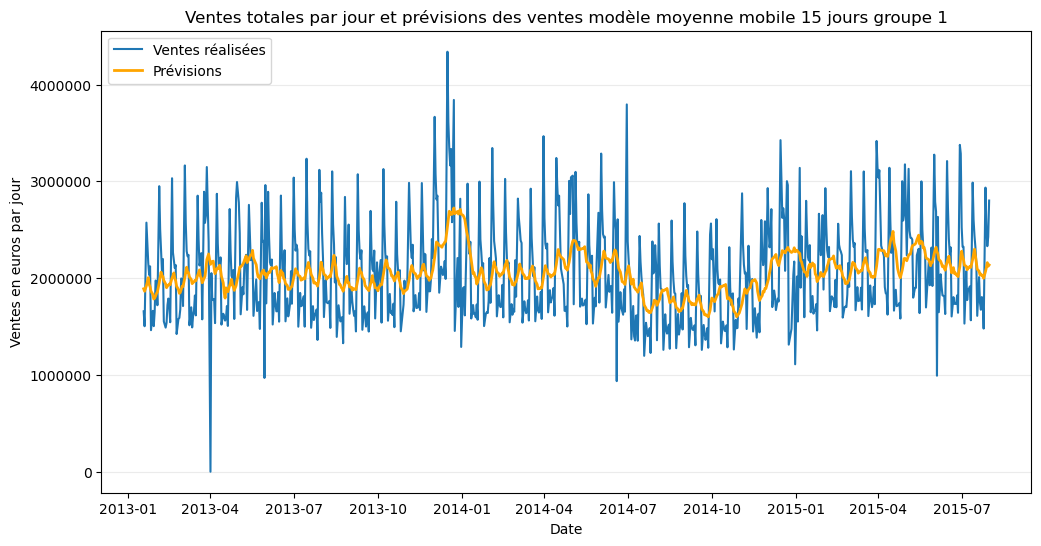

In [131]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_type1['Date'],df_cluster_type1['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_type1['Date'],df_cluster_type1['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours groupe 1")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

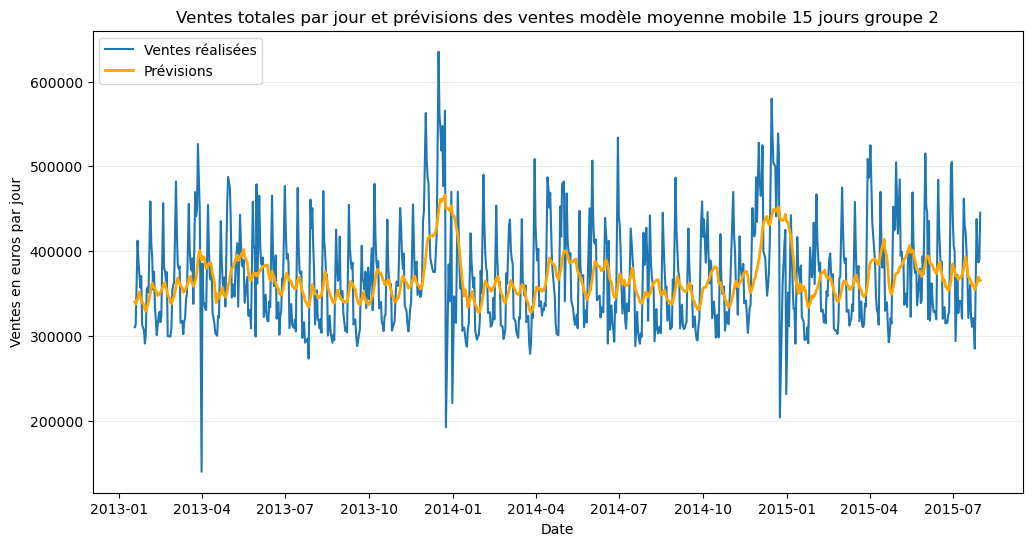

In [132]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_type2['Date'],df_cluster_type2['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_type2['Date'],df_cluster_type2['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours groupe 2")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

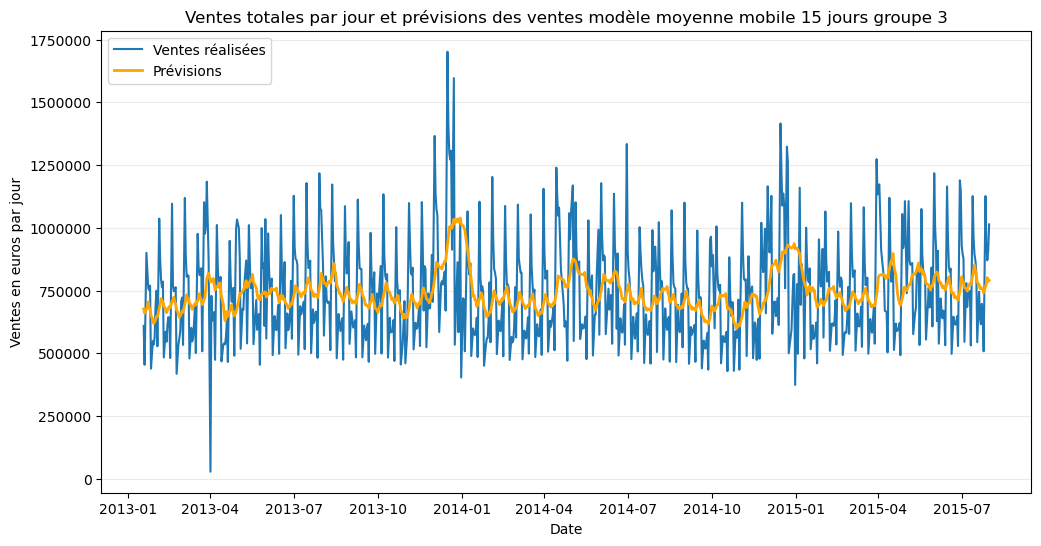

In [133]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_type3['Date'],df_cluster_type3['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_type3['Date'],df_cluster_type3['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours groupe 3")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

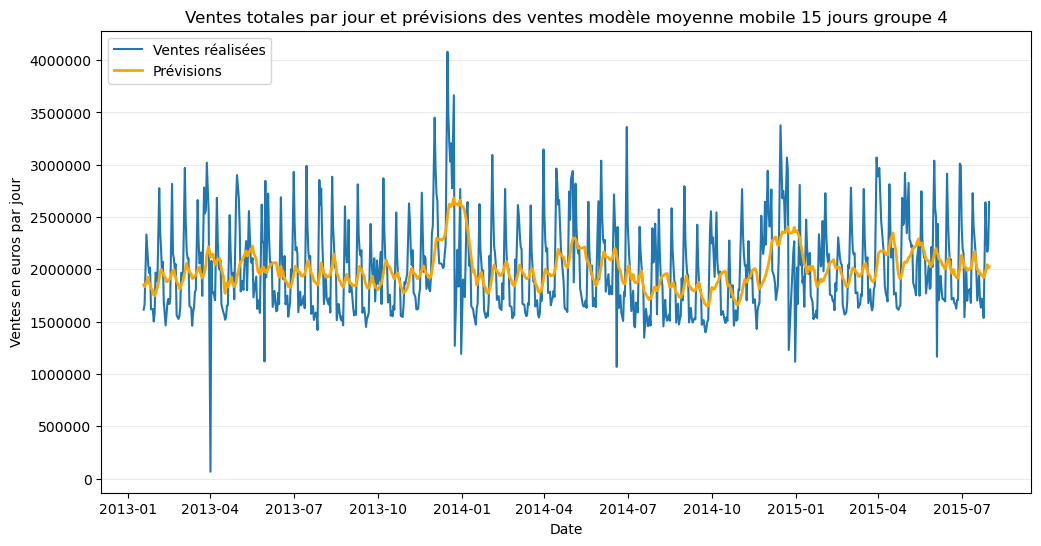

In [134]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_type4['Date'],df_cluster_type4['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_type4['Date'],df_cluster_type4['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours groupe 4")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

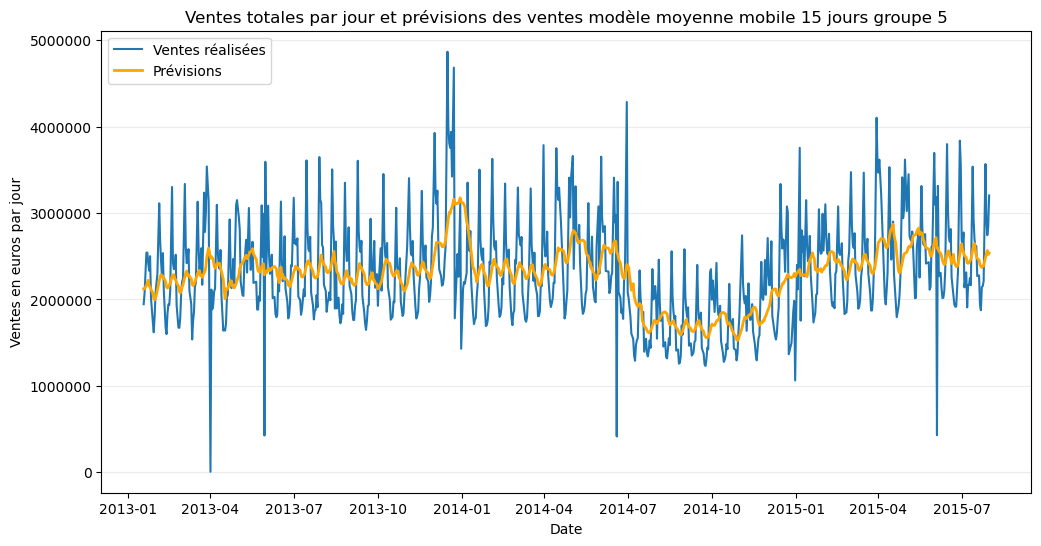

In [135]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_type5['Date'],df_cluster_type5['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_type5['Date'],df_cluster_type5['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours groupe 5")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

In [136]:
#
# Prévision des ventes modèle Facebook prophet
#

In [137]:
# Tableau des données de ventes des magasins de type 1
df_prophet_store_type1 = df_cluster_type1
df_prophet_store_type1 = df_prophet_store_type1[['Date','Sales_day']]
df_prophet_store_type1.columns = ["ds", "y"]
#df_prophet_store_type1

In [138]:
# Tableau des données de ventes des magasins de type 2
df_prophet_store_type2 = df_cluster_type2
df_prophet_store_type2 = df_prophet_store_type2[['Date','Sales_day']]
df_prophet_store_type2.columns = ["ds", "y"]
#df_prophet_store_type2

In [139]:
# Tableau des données de ventes des magasins de type 3
df_prophet_store_type3 = df_cluster_type3
df_prophet_store_type3 = df_prophet_store_type3[['Date','Sales_day']]
df_prophet_store_type3.columns = ["ds", "y"]
#df_prophet_store_type3

In [140]:
# Tableau des données de ventes des magasins de type 4
df_prophet_store_type4 = df_cluster_type4
df_prophet_store_type4 = df_prophet_store_type4[['Date','Sales_day']]
df_prophet_store_type4.columns = ["ds", "y"]
#df_prophet_store_type4

In [141]:
# Tableau des données de ventes des magasins de type 5
df_prophet_store_type5 = df_cluster_type5
df_prophet_store_type5 = df_prophet_store_type5[['Date','Sales_day']]
df_prophet_store_type5.columns = ["ds", "y"]
#df_prophet_store_type5

In [142]:
# Prévision des ventes des magasins de type 1
m_store_type1 = Prophet()
m_store_type1.add_country_holidays(country_name='FR')
m_store_type1.fit(df_prophet_store_type1)
future_store_type1 = m_store_type1.make_future_dataframe(periods=153)
forecast_store_type1 = m_store_type1.predict(future_store_type1)
#show(forecast_store_type1)

16:10:54 - cmdstanpy - INFO - Chain [1] start processing
16:10:54 - cmdstanpy - INFO - Chain [1] done processing


In [143]:
# Prévision des ventes des magasins de type 2
m_store_type2 = Prophet()
m_store_type2.add_country_holidays(country_name='FR')
m_store_type2.fit(df_prophet_store_type2)
future_store_type2 = m_store_type2.make_future_dataframe(periods=153)
forecast_store_type2 = m_store_type2.predict(future_store_type2)
#show(forecast_store_type2)

16:10:54 - cmdstanpy - INFO - Chain [1] start processing
16:10:54 - cmdstanpy - INFO - Chain [1] done processing


In [144]:
# Prévision des ventes des magasins de type 3
m_store_type3 = Prophet()
m_store_type3.add_country_holidays(country_name='FR')
m_store_type3.fit(df_prophet_store_type3)
future_store_type3 = m_store_type3.make_future_dataframe(periods=153)
forecast_store_type3 = m_store_type3.predict(future_store_type3)
#show(forecast_store_type3)

16:10:55 - cmdstanpy - INFO - Chain [1] start processing
16:10:55 - cmdstanpy - INFO - Chain [1] done processing


In [145]:
# Prévision des ventes des magasins de type 4
m_store_type4 = Prophet()
m_store_type4.add_country_holidays(country_name='FR')
m_store_type4.fit(df_prophet_store_type4)
future_store_type4 = m_store_type4.make_future_dataframe(periods=153)
forecast_store_type4 = m_store_type4.predict(future_store_type4)
#show(forecast_store_type4)

16:10:55 - cmdstanpy - INFO - Chain [1] start processing
16:10:55 - cmdstanpy - INFO - Chain [1] done processing


In [146]:
# Prévision des ventes des magasins de type 5
m_store_type5 = Prophet()
m_store_type5.add_country_holidays(country_name='FR')
m_store_type5.fit(df_prophet_store_type5)
future_store_type5 = m_store_type5.make_future_dataframe(periods=153)
forecast_store_type5 = m_store_type5.predict(future_store_type5)
#show(forecast_store_type5)

16:10:55 - cmdstanpy - INFO - Chain [1] start processing
16:10:56 - cmdstanpy - INFO - Chain [1] done processing


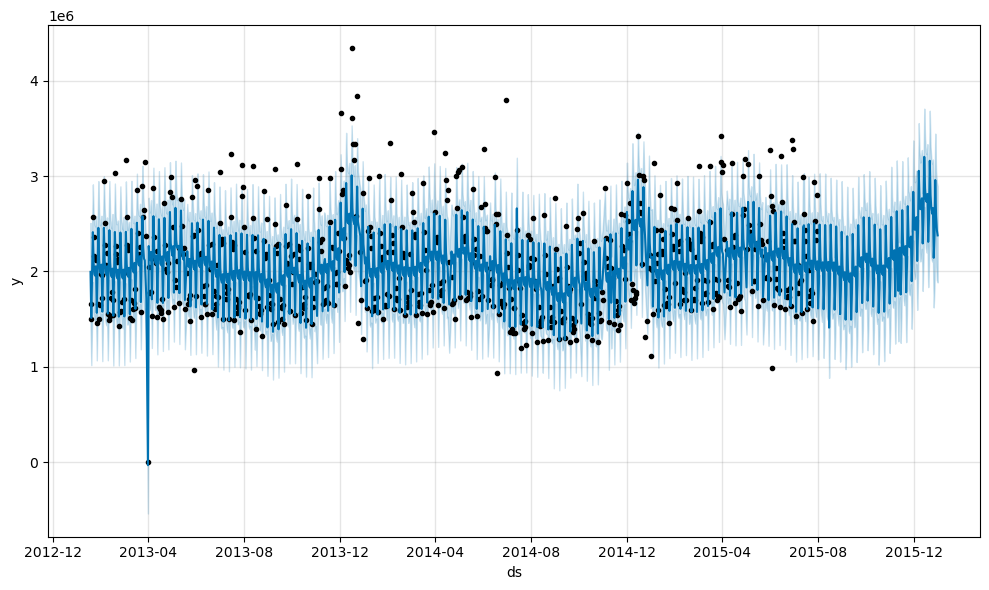

In [147]:
# Graphique de prévision des ventes des magasins de type 1
fig_store_type1 = m_store_type1.plot(forecast_store_type1)
#fig_components_store_type1 = m_store_type1.plot_components(forecast_store_type1)

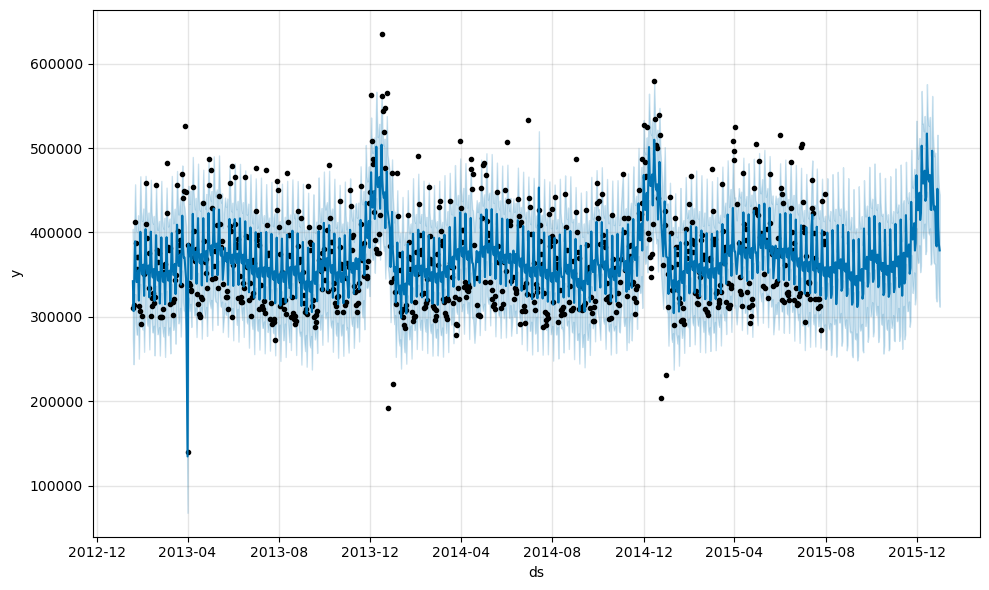

In [148]:
# Graphique de prévision des ventes des magasins de type 2
fig_store_type2 = m_store_type2.plot(forecast_store_type2)
#fig_components_store_type2 = m_store_type2.plot_components(forecast_store_type2)

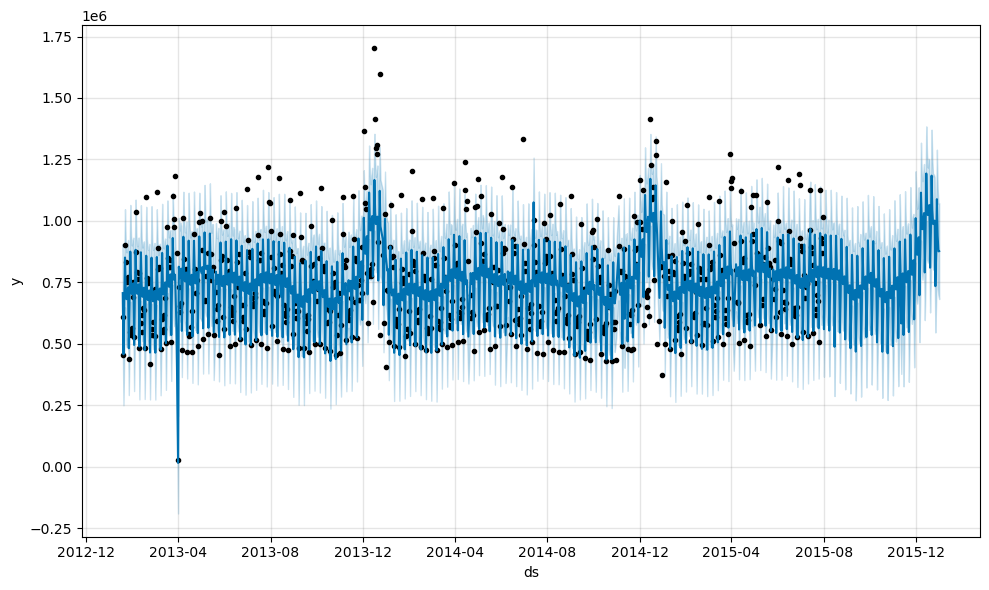

In [149]:
# Graphique de prévision des ventes des magasins de type 3
fig_store_type3 = m_store_type3.plot(forecast_store_type3)
#fig_components_store_type3 = m_store_type3.plot_components(forecast_store_type3)

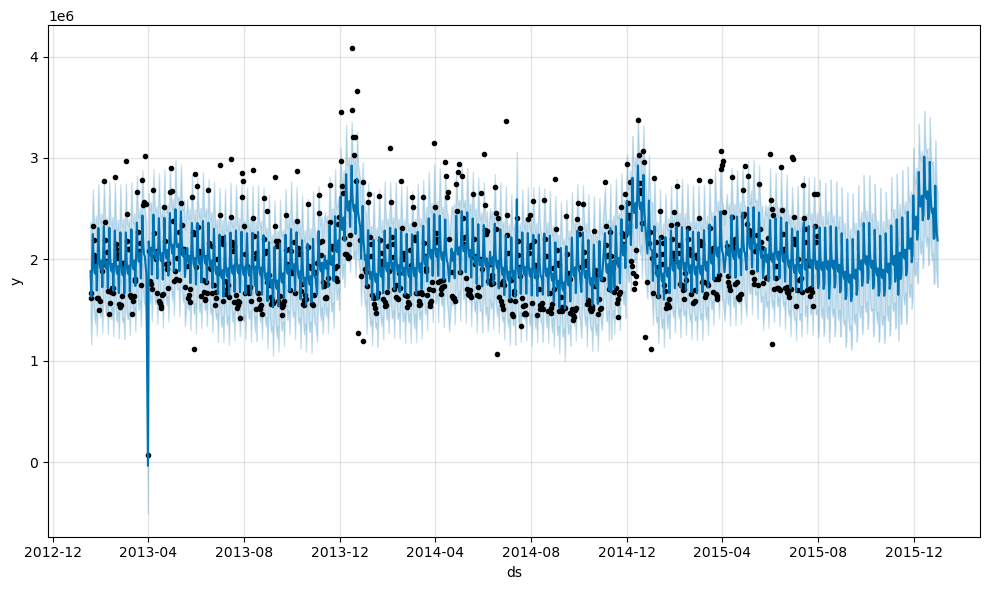

In [150]:
# Graphique de prévision des ventes des magasins de type 4
fig_store_type4 = m_store_type4.plot(forecast_store_type4)
#fig_components_store_type4 = m_store_type4.plot_components(forecast_store_type4)

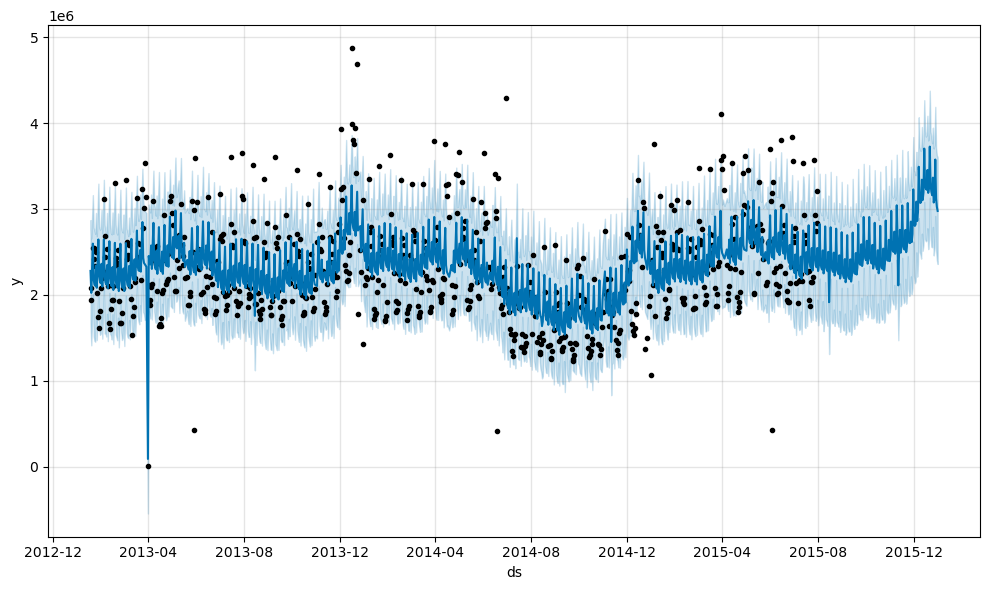

In [151]:
# Graphique de prévision des ventes des magasins de type 5
fig_store_type5 = m_store_type5.plot(forecast_store_type5)
#fig_components_store_type5 = m_store_type5.plot_components(forecast_store_type5)

In [152]:
#
# Prévision un magasin par type de cluster
#

In [153]:
# Tableau d'identification d'un numéro de magasin par cluster
table_cluster_store_select = df_merge_cluster
table_cluster_store_select = table_cluster_store_select.drop_duplicates(subset=['cluster'], keep='first')
table_cluster_store_select = table_cluster_store_select[['cluster','Store']]
table_cluster_store_select = table_cluster_store_select.sort_values(by='cluster', ascending=True) 
table_cluster_store_select

,cluster,Store
0,1,1
250,2,251
2,3,3
3,4,4
8,5,9


In [154]:
list_holidays = ['2013-01-01','2014-01-01','2015-01-01',
                 '2013-03-29','2014-04-18','2014-04-21','2015-04-03','2015-04-06',
                 '2013-05-01','2014-05-01','2015-05-01',
                '2013-05-09','2013-05-20','2014-05-29','2015-05-14','2015-05-25','2014-06-09',
                '2013-10-03','2014-10-03','2013-11-01','2014-11-01',
                '2013-12-25','2014-12-25','2013-12-26','2014-12-26']

In [155]:
# Table des ventes du magasin identifiant 1 du type de magasin 1
df_cluster_store_type1 = df_merge_cluster
df_cluster_store_type1 = df_cluster_store_type1[df_cluster_store_type1['Store'] == 1]
df_cluster_store_type1 = df_cluster_store_type1[['Date','DayOfWeek','Sales']]
df_cluster_store_type1['Sales_day'] = df_cluster_store_type1.groupby(['Date'])['Sales'].transform('sum')
df_cluster_store_type1 = df_cluster_store_type1[df_cluster_store_type1['DayOfWeek'] != 7]
df_cluster_store_type1 = df_cluster_store_type1[df_cluster_store_type1['Sales_day'] != 0]
#df_cluster_store_type1 = df_cluster_store_type1[~df_cluster_type1['Date'].isin(list_holidays)]
df_cluster_store_type1 = df_cluster_store_type1[['Date','Sales_day']]
df_cluster_store_type1 = df_cluster_store_type1.drop_duplicates(subset=['Date'],keep='first')
df_cluster_store_type1 = df_cluster_store_type1.dropna()
df_cluster_store_type1 = df_cluster_store_type1.sort_values(by='Date', ascending=True) 
df_cluster_store_type1 = df_cluster_store_type1.reset_index(drop=True)
#df_cluster_store_type1

In [156]:
# Table des ventes du magasin identifiant 251 du type de magasin 2
df_cluster_store_type2 = df_merge_cluster
df_cluster_store_type2 = df_cluster_store_type2[df_cluster_store_type2['Store'] == 251]
df_cluster_store_type2 = df_cluster_store_type2[['Date','DayOfWeek','Sales']]
df_cluster_store_type2['Sales_day'] = df_cluster_store_type2.groupby(['Date'])['Sales'].transform('sum')
df_cluster_store_type2 = df_cluster_store_type2[df_cluster_store_type2['DayOfWeek'] != 7]
df_cluster_store_type2 = df_cluster_store_type2[df_cluster_store_type2['Sales_day'] != 0]
#df_cluster_store_type2 = df_cluster_store_type2[~df_cluster_type2['Date'].isin(list_holidays)]
df_cluster_store_type2 = df_cluster_store_type2[['Date','Sales_day']]
df_cluster_store_type2 = df_cluster_store_type2.drop_duplicates(subset=['Date'],keep='first')
df_cluster_store_type2 = df_cluster_store_type2.dropna()
df_cluster_store_type2 = df_cluster_store_type2.sort_values(by='Date', ascending=True) 
df_cluster_store_type2 = df_cluster_store_type2.reset_index(drop=True)
#df_cluster_store_type2

In [157]:
# Table des ventes du magasin identifiant 3 du type de magasin 3
df_cluster_store_type3 = df_merge_cluster
df_cluster_store_type3 = df_cluster_store_type3[df_cluster_store_type3['Store'] == 3]
df_cluster_store_type3 = df_cluster_store_type3[['Date','DayOfWeek','Sales']]
df_cluster_store_type3['Sales_day'] = df_cluster_store_type3.groupby(['Date'])['Sales'].transform('sum')
df_cluster_store_type3 = df_cluster_store_type3[df_cluster_store_type3['DayOfWeek'] != 7]
df_cluster_store_type3 = df_cluster_store_type3[df_cluster_store_type3['Sales_day'] != 0]
#df_cluster_store_type3 = df_cluster_store_type3[~df_cluster_type3['Date'].isin(list_holidays)]
df_cluster_store_type3 = df_cluster_store_type3[['Date','Sales_day']]
df_cluster_store_type3 = df_cluster_store_type3.drop_duplicates(subset=['Date'],keep='first')
df_cluster_store_type3 = df_cluster_store_type3.dropna()
df_cluster_store_type3 = df_cluster_store_type3.sort_values(by='Date', ascending=True) 
df_cluster_store_type3 = df_cluster_store_type3.reset_index(drop=True)
#df_cluster_store_type3

In [158]:
# Table des ventes du magasin identifiant 4 du type de magasin 4
df_cluster_store_type4 = df_merge_cluster
df_cluster_store_type4 = df_cluster_store_type4[df_cluster_store_type4['Store'] == 4]
df_cluster_store_type4 = df_cluster_store_type4[['Date','DayOfWeek','Sales']]
df_cluster_store_type4['Sales_day'] = df_cluster_store_type4.groupby(['Date'])['Sales'].transform('sum')
df_cluster_store_type4 = df_cluster_store_type4[df_cluster_store_type4['DayOfWeek'] != 7]
df_cluster_store_type4 = df_cluster_store_type4[df_cluster_store_type4['Sales_day'] != 0]
#df_cluster_store_type4 = df_cluster_store_type4[~df_cluster_type4['Date'].isin(list_holidays)]
df_cluster_store_type4 = df_cluster_store_type4[['Date','Sales_day']]
df_cluster_store_type4 = df_cluster_store_type4.drop_duplicates(subset=['Date'],keep='first')
df_cluster_store_type4 = df_cluster_store_type4.dropna()
df_cluster_store_type4 = df_cluster_store_type4.sort_values(by='Date', ascending=True) 
df_cluster_store_type4 = df_cluster_store_type4.reset_index(drop=True)
#df_cluster_store_type4

In [159]:
# Table des ventes du magasin identifiant 4 du type de magasin 4
df_cluster_store_type5 = df_merge_cluster
df_cluster_store_type5 = df_cluster_store_type5[df_cluster_store_type5['Store'] == 9]
df_cluster_store_type5 = df_cluster_store_type5[['Date','DayOfWeek','Sales']]
df_cluster_store_type5['Sales_day'] = df_cluster_store_type5.groupby(['Date'])['Sales'].transform('sum')
df_cluster_store_type5 = df_cluster_store_type5[df_cluster_store_type5['DayOfWeek'] != 7]
df_cluster_store_type5 = df_cluster_store_type5[df_cluster_store_type5['Sales_day'] != 0]
#df_cluster_store_type5 = df_cluster_store_type5[~df_cluster_type5['Date'].isin(list_holidays)]
df_cluster_store_type5 = df_cluster_store_type5[['Date','Sales_day']]
df_cluster_store_type5 = df_cluster_store_type5.drop_duplicates(subset=['Date'],keep='first')
df_cluster_store_type5 = df_cluster_store_type5.dropna()
df_cluster_store_type5 = df_cluster_store_type5.sort_values(by='Date', ascending=True) 
df_cluster_store_type5 = df_cluster_store_type5.reset_index(drop=True)
#df_cluster_store_type5

In [160]:
# Table des ventes et prévisions moyenne mobile 15 jours du magasin identifiant 1 du type 1
df_cluster_store_type1['SMA_15'] = df_cluster_store_type1['Sales_day'].rolling(window=15).mean()
df_cluster_store_type1 = df_cluster_store_type1.dropna()
#df_cluster_store_type1

In [161]:
# Table des ventes et prévisions moyenne mobile 15 jours du magasin identifiant 1 du type 2
df_cluster_store_type2['SMA_15'] = df_cluster_store_type2['Sales_day'].rolling(window=15).mean()
df_cluster_store_type2 = df_cluster_store_type2.dropna()
#df_cluster_store_type2

In [162]:
# Table des ventes et prévisions moyenne mobile 15 jours du magasin identifiant 1 du type 3
df_cluster_store_type3['SMA_15'] = df_cluster_store_type3['Sales_day'].rolling(window=15).mean()
df_cluster_store_type3 = df_cluster_store_type3.dropna()
#df_cluster_store_type3

In [163]:
# Table des ventes et prévisions moyenne mobile 15 jours du magasin identifiant 1 du type 4
df_cluster_store_type4['SMA_15'] = df_cluster_store_type4['Sales_day'].rolling(window=15).mean()
df_cluster_store_type4 = df_cluster_store_type4.dropna()
#df_cluster_store_type4

In [164]:
# Table des ventes et prévisions moyenne mobile 15 jours du magasin identifiant 1 du type 4
df_cluster_store_type5['SMA_15'] = df_cluster_store_type5['Sales_day'].rolling(window=15).mean()
df_cluster_store_type5 = df_cluster_store_type5.dropna()
#df_cluster_store_type5

In [165]:
# Prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 1
next_forecast_store_type1 = df_cluster_store_type1['SMA_15'].iloc[-1]
print(next_forecast_store_type1)

4525.733333333334


In [166]:
# Prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 2
next_forecast_store_type2 = df_cluster_store_type2['SMA_15'].iloc[-1]
print(next_forecast_store_type2)

18003.2


In [167]:
# Prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 3
next_forecast_store_type3 = df_cluster_store_type3['SMA_15'].iloc[-1]
print(next_forecast_store_type3)

6723.533333333334


In [168]:
# Prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 4
next_forecast_store_type4 = df_cluster_store_type4['SMA_15'].iloc[-1]
print(next_forecast_store_type4)

10176.666666666666


In [169]:
# Prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 4
next_forecast_store_type5 = df_cluster_store_type5['SMA_15'].iloc[-1]
print(next_forecast_store_type5)

7145.133333333333


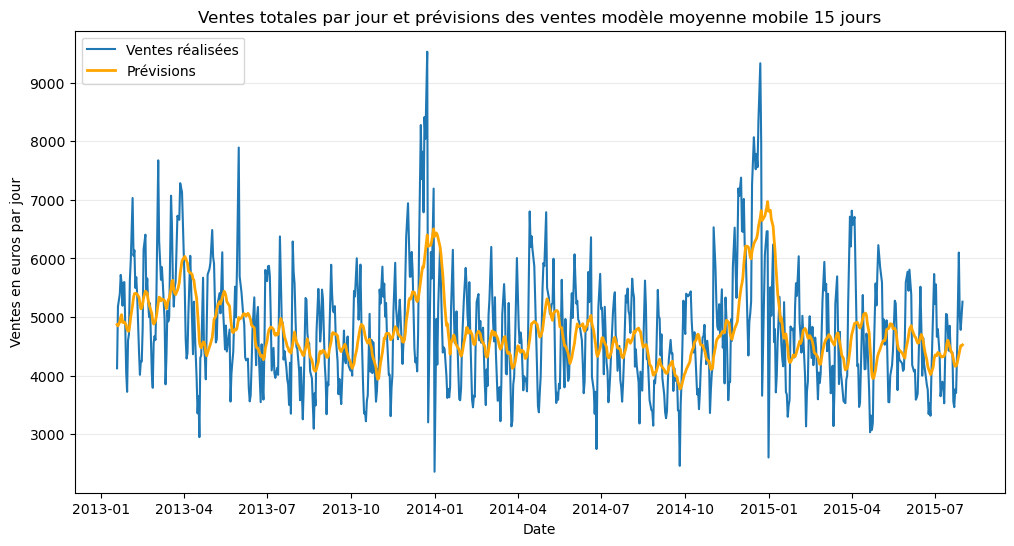

In [170]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_store_type1['Date'],df_cluster_store_type1['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_store_type1['Date'],df_cluster_store_type1['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

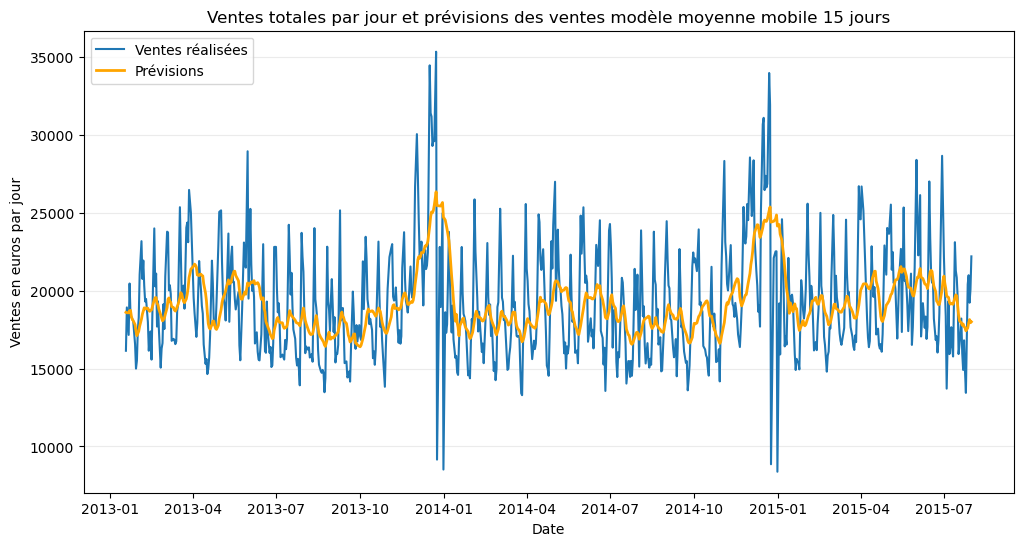

In [171]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_store_type2['Date'],df_cluster_store_type2['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_store_type2['Date'],df_cluster_store_type2['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

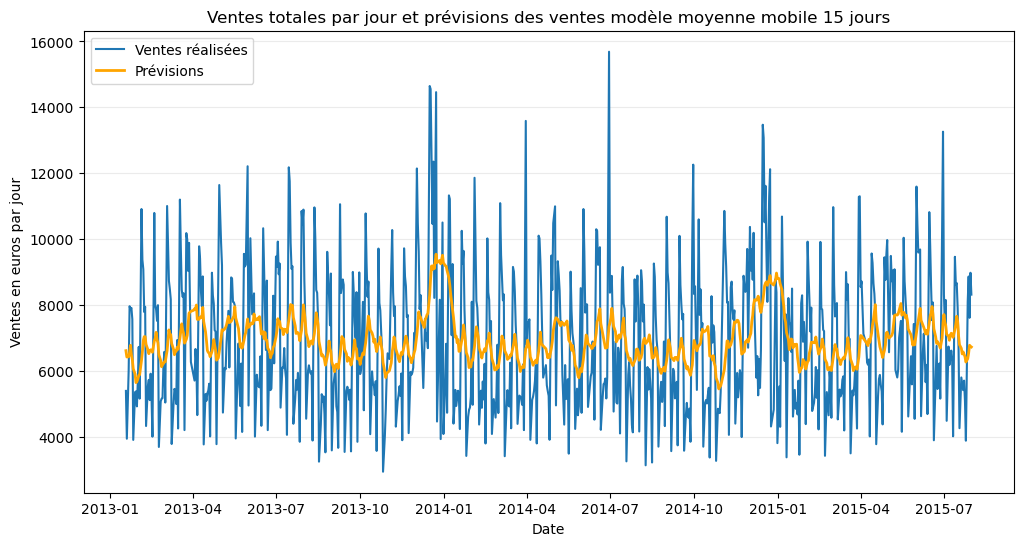

In [172]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_store_type3['Date'],df_cluster_store_type3['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_store_type3['Date'],df_cluster_store_type3['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

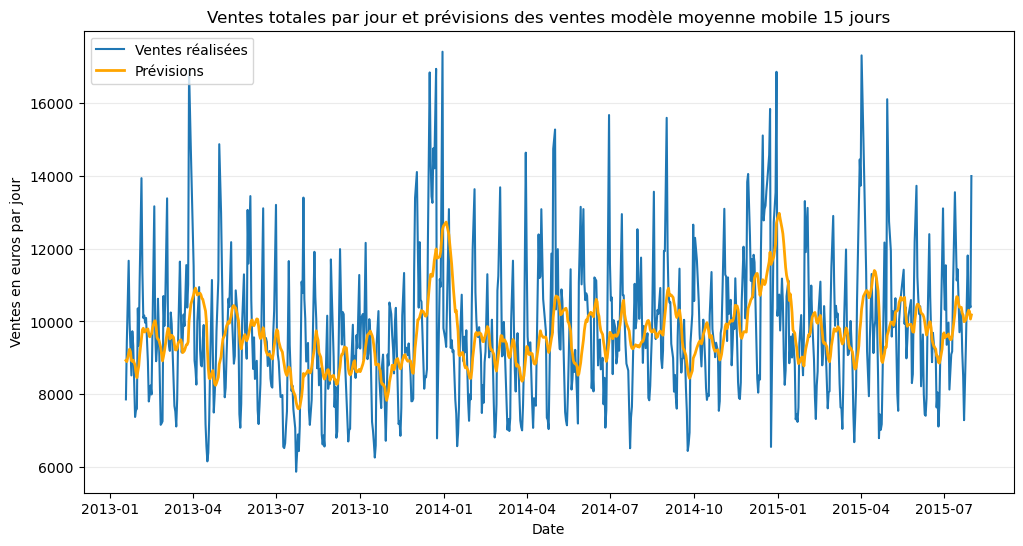

In [173]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_store_type4['Date'],df_cluster_store_type4['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_store_type4['Date'],df_cluster_store_type4['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

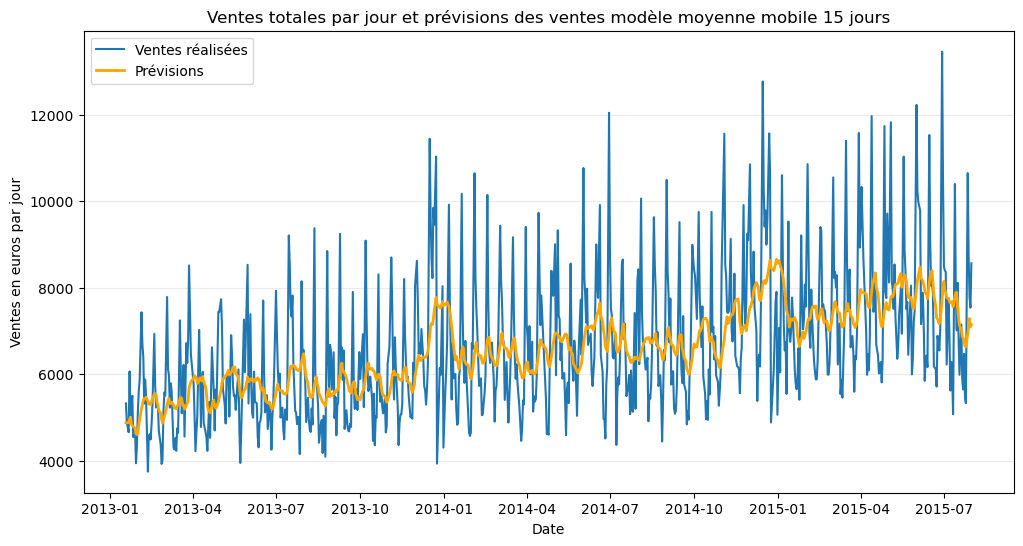

In [174]:
# Graphique des ventes et prévisions du modèle moyenne mobile 15 jours
plt.figure(figsize=(12, 6))
plt.plot(df_cluster_store_type5['Date'],df_cluster_store_type5['Sales_day'], label='Ventes réalisées')
plt.plot(df_cluster_store_type5['Date'],df_cluster_store_type5['SMA_15'], label='Prévisions', color='orange', linewidth=2)
plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes totales par jour et prévisions des ventes modèle moyenne mobile 15 jours")
plt.xlabel("Date")
plt.ylabel("Ventes en euros par jour")
plt.legend(loc="upper left")
plt.grid(axis='y', alpha=0.25)
plt.show()

In [175]:
#
# Prévisions des ventes d'un magasin par typologie avec le modèle Facebook prophet 
#

In [176]:
# Table des ventes du magasin identifiant 1 de typologie 1
df_prophet_storeid_type1 = df_cluster_store_type1
df_prophet_storeid_type1 = df_prophet_storeid_type1[['Date','Sales_day']]
df_prophet_storeid_type1.columns = ["ds", "y"]
#df_prophet_storeid_type1

In [177]:
# Table des ventes du magasin identifiant 1 de typologie 2
df_prophet_storeid_type2 = df_cluster_store_type2
df_prophet_storeid_type2 = df_prophet_storeid_type2[['Date','Sales_day']]
df_prophet_storeid_type2.columns = ["ds", "y"]
#df_prophet_storeid_type2

In [178]:
# Table des ventes du magasin identifiant 1 de typologie 3
df_prophet_storeid_type3 = df_cluster_store_type3
df_prophet_storeid_type3 = df_prophet_storeid_type3[['Date','Sales_day']]
df_prophet_storeid_type3.columns = ["ds", "y"]
#df_prophet_storeid_type3

In [179]:
# Table des ventes du magasin identifiant 1 de typologie 4
df_prophet_storeid_type4 = df_cluster_store_type4
df_prophet_storeid_type4 = df_prophet_storeid_type4[['Date','Sales_day']]
df_prophet_storeid_type4.columns = ["ds", "y"]
#df_prophet_storeid_type4

In [180]:
# Table des ventes du magasin identifiant 1 de typologie 5
df_prophet_storeid_type5 = df_cluster_store_type5
df_prophet_storeid_type5 = df_prophet_storeid_type5[['Date','Sales_day']]
df_prophet_storeid_type5.columns = ["ds", "y"]
#df_prophet_storeid_type5

In [181]:
# Prévision des ventes avec le modèle Facebook Prophet du magasin identifiant 1 de typologie 1
m_storeid_type1 = Prophet()
m_storeid_type1.add_country_holidays(country_name='FR')
m_storeid_type1.fit(df_prophet_storeid_type1)
future_storeid_type1 = m_storeid_type1.make_future_dataframe(periods=153)
forecast_storeid_type1 = m_storeid_type1.predict(future_storeid_type1)
#show(forecast_storeid_type1)

16:11:01 - cmdstanpy - INFO - Chain [1] start processing
16:11:01 - cmdstanpy - INFO - Chain [1] done processing


In [182]:
# Prévision des ventes avec le modèle Facebook Prophet du magasin identifiant 1 de typologie 2
m_storeid_type2 = Prophet()
m_storeid_type2.add_country_holidays(country_name='FR')
m_storeid_type2.fit(df_prophet_storeid_type2)
future_storeid_type2 = m_storeid_type2.make_future_dataframe(periods=153)
forecast_storeid_type2 = m_storeid_type2.predict(future_storeid_type2)
#show(forecast_storeid_type2)

16:11:02 - cmdstanpy - INFO - Chain [1] start processing
16:11:02 - cmdstanpy - INFO - Chain [1] done processing


In [183]:
# Prévision des ventes avec le modèle Facebook Prophet du magasin identifiant 1 de typologie 3
m_storeid_type3 = Prophet()
m_storeid_type3.add_country_holidays(country_name='FR')
m_storeid_type3.fit(df_prophet_storeid_type3)
future_storeid_type3 = m_storeid_type3.make_future_dataframe(periods=153)
forecast_storeid_type3 = m_storeid_type3.predict(future_storeid_type3)
#show(forecast_storeid_type3)

16:11:02 - cmdstanpy - INFO - Chain [1] start processing
16:11:02 - cmdstanpy - INFO - Chain [1] done processing


In [184]:
# Prévision des ventes avec le modèle Facebook Prophet du magasin identifiant 1 de typologie 4
m_storeid_type4 = Prophet()
m_storeid_type4.add_country_holidays(country_name='FR')
m_storeid_type4.fit(df_prophet_storeid_type4)
future_storeid_type4 = m_storeid_type4.make_future_dataframe(periods=153)
forecast_storeid_type4 = m_storeid_type4.predict(future_storeid_type4)
#show(forecast_storeid_type4)

16:11:03 - cmdstanpy - INFO - Chain [1] start processing
16:11:03 - cmdstanpy - INFO - Chain [1] done processing


In [185]:
# Prévision des ventes avec le modèle Facebook Prophet du magasin identifiant 1 de typologie 4
m_storeid_type5 = Prophet()
m_storeid_type5.add_country_holidays(country_name='FR')
m_storeid_type5.fit(df_prophet_storeid_type5)
future_storeid_type5 = m_storeid_type5.make_future_dataframe(periods=153)
forecast_storeid_type5 = m_storeid_type5.predict(future_storeid_type5)
#show(forecast_storeid_type5)

16:11:03 - cmdstanpy - INFO - Chain [1] start processing
16:11:03 - cmdstanpy - INFO - Chain [1] done processing


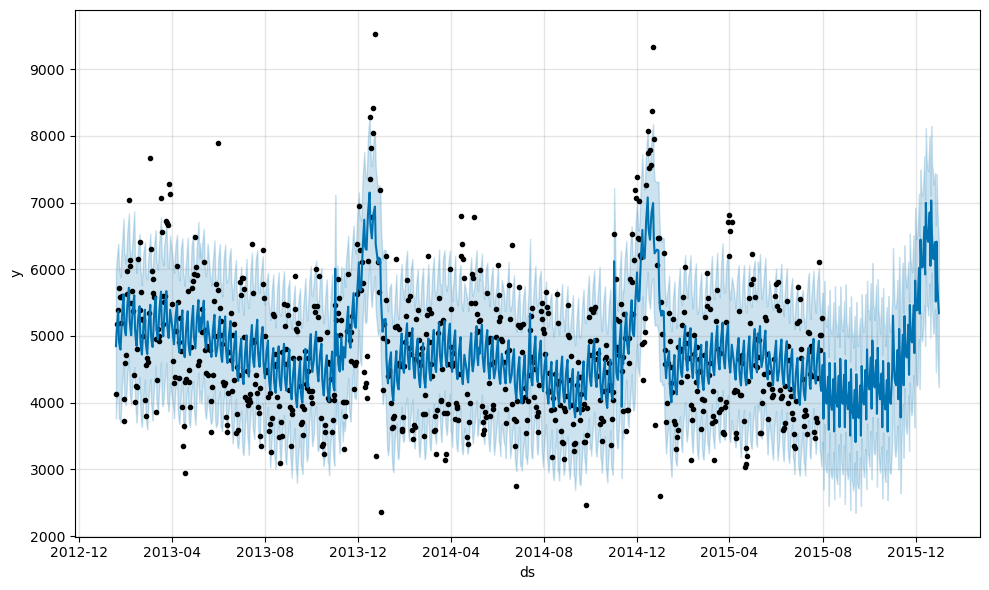

In [186]:
# Graphique des ventes et prévisions des ventes du magasin identifiant 1 de typologie 1 
fig_storeid_type1 = m_storeid_type1.plot(forecast_storeid_type1)
#fig_components_storeid_type1 = m_storeid_type1.plot_components(forecast_storeid_type1)

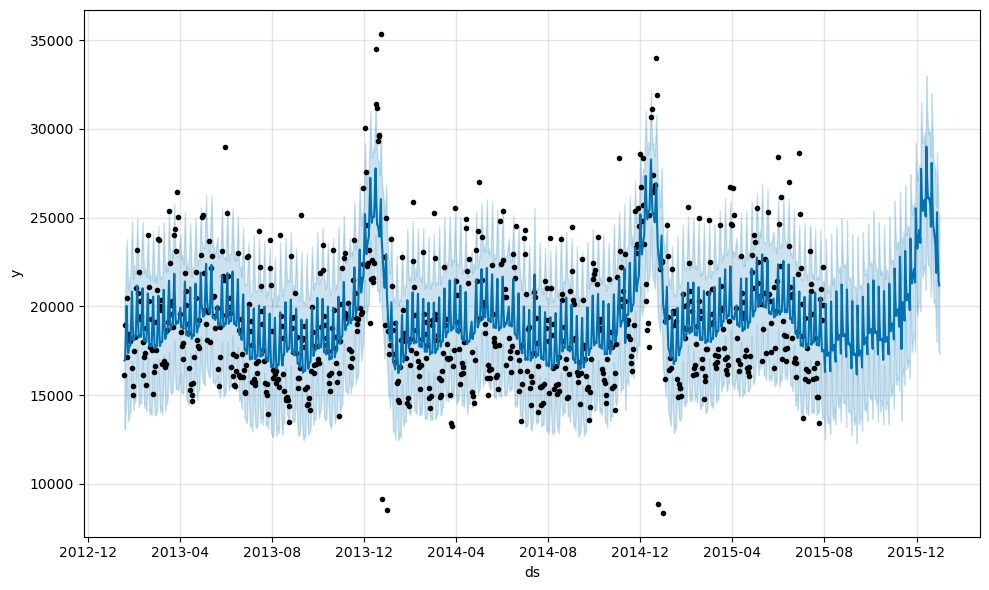

In [187]:
# Graphique des ventes et prévisions des ventes du magasin identifiant 1 de typologie 2
fig_storeid_type2 = m_storeid_type2.plot(forecast_storeid_type2)
#fig_components_storeid_type2 = m_storeid_type2.plot_components(forecast_storeid_type2)

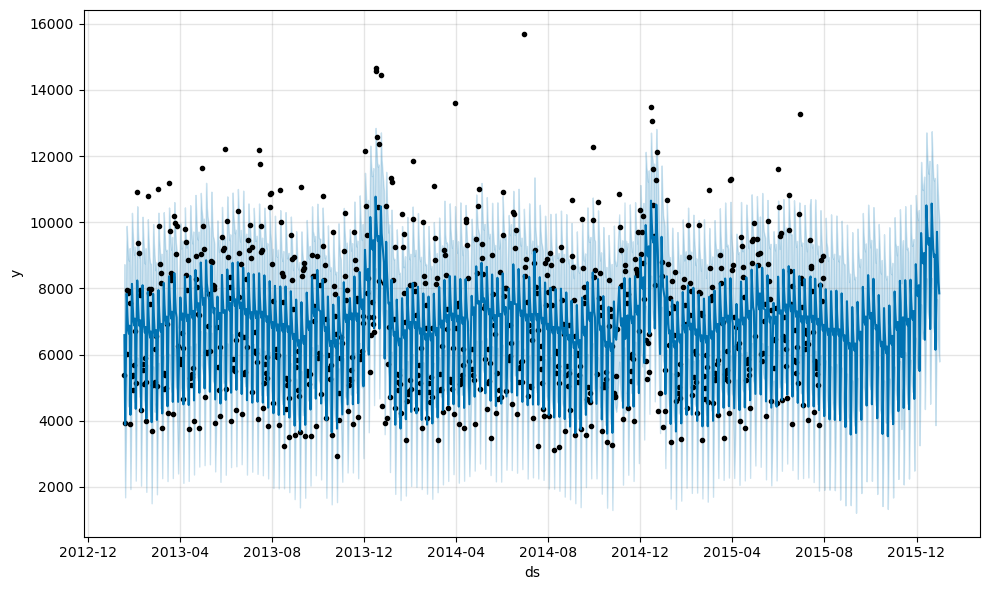

In [188]:
# Graphique des ventes et prévisions des ventes du magasin identifiant 1 de typologie 3
fig_storeid_type3 = m_storeid_type3.plot(forecast_storeid_type3)
#fig_components_storeid_type3 = m_storeid_type3.plot_components(forecast_storeid_type3)

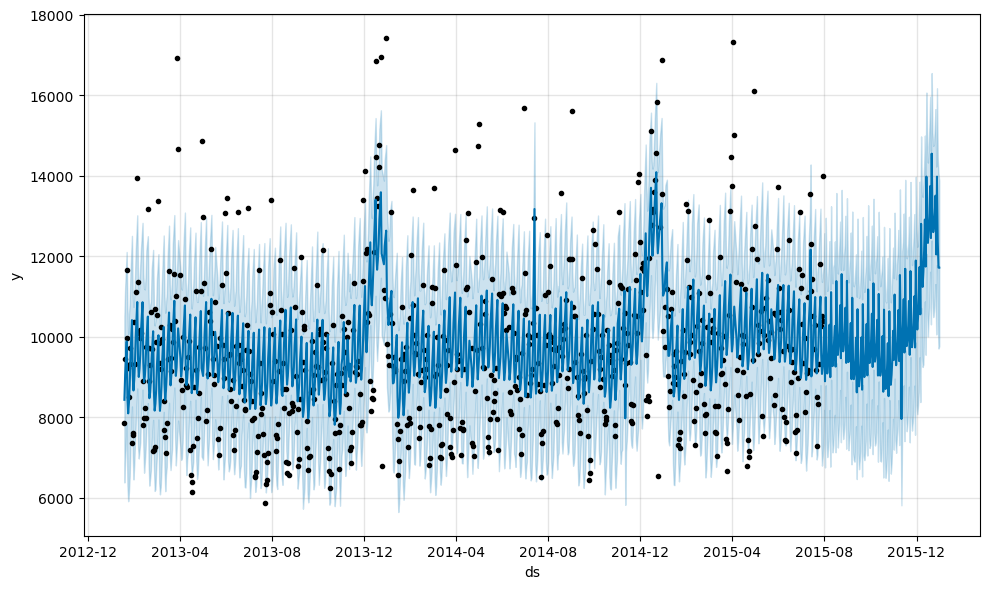

In [189]:
# Graphique des ventes et prévisions des ventes du magasin identifiant 1 de typologie 4
fig_storeid_type4 = m_storeid_type4.plot(forecast_storeid_type4)
#fig_components_storeid_type4 = m_storeid_type4.plot_components(forecast_storeid_type4)

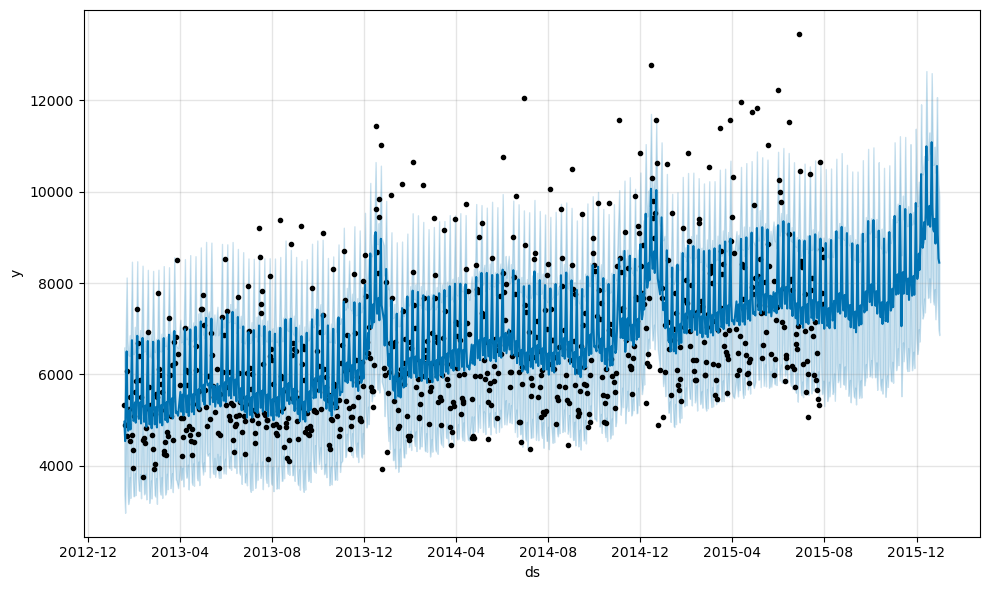

In [190]:
# Graphique des ventes et prévisions des ventes du magasin identifiant 1 de typologie 5
fig_storeid_type5 = m_storeid_type5.plot(forecast_storeid_type5)
#fig_components_storeid_type5 = m_storeid_type5.plot_components(forecast_storeid_type5)

In [191]:
# Partie 4 Evaluation de la performance des modèles de prévisions
#
# 4 - 1 Définition de la métrique la plus adaptée
# 4 - 2 Evaluation baseline simple
# 4 - 3 Comparaison méthode série temporelle
#

In [192]:
# 4 - 1 Définition de la métrique la plus adaptée

In [193]:
#
# La MAPE (Mean absolute percentage error - erreur absolue moyenne en pourcentage)
# est la mesure de précision la plus adaptée car elle permet une comparaison 
# entre toutes les séries de données et méthodes de prévision
#
#

In [194]:
# 4 - 2 Evaluation baseline simple

In [195]:
#
# Méthode moyenne mobile 15 jours
#

In [196]:
# fusion des données de ventes et les ventes moyenne mobile à 15 jours
df_rolling_sales_evaluation = df_rolling_sales
df_rolling_sales_evaluation = df_rolling_sales_evaluation[df_rolling_sales_evaluation['Date'] > '2015-01-01']
df_rolling_sales_evaluation = df_rolling_sales_evaluation[df_rolling_sales_evaluation['Date'] < '2015-07-01']
df_rolling_sales_evaluation = df_rolling_sales_evaluation.reset_index(drop=True)
#df_rolling_sales_evaluation

In [197]:
# mesure des résultats de prévision
observed_sales = df_rolling_sales_evaluation['Sales_day']
predict_sales = df_rolling_sales_evaluation['SMA_15']

mae_sales_sma15 = mean_absolute_error(observed_sales, predict_sales)
mape_sales_sma15 = mean_absolute_percentage_error(observed_sales, predict_sales)
#mse_sales = mean_squared_error(observed_sales, predict_sales)
rmse_sales_sma15 = root_mean_squared_error(observed_sales, predict_sales)

print("Mesures de précision des prévisions\nmoyenne mobile 15 jours")
print("-----------------------------------")
print("MAE:", round(mae_sales_sma15,0))
print("MAPE:", round(mape_sales_sma15,3))
#print("MSE_sales:", round(mse_sales,0))
print("RMSE:", round(rmse_sales_sma15,0))

Mesures de précision des prévisions
moyenne mobile 15 jours
-----------------------------------
MAE: 1262942.0
MAPE: 0.163
RMSE: 1574399.0


In [198]:
# Prévision des ventes pour mesure de précision des magasins de type 1
df_store_type1_evaluation = df_cluster_type1
df_store_type1_evaluation = df_store_type1_evaluation[df_store_type1_evaluation['Date'] > '2015-01-01']
df_store_type1_evaluation = df_store_type1_evaluation[df_store_type1_evaluation['Date'] < '2015-07-01']
df_store_type1_evaluation = df_store_type1_evaluation.reset_index(drop=True)
#df_store_type1_evaluation

In [199]:
# Prévision des ventes pour mesure de précision des magasins de type 2
df_store_type2_evaluation = df_cluster_type2
df_store_type2_evaluation = df_store_type2_evaluation[df_store_type2_evaluation['Date'] > '2015-01-01']
df_store_type2_evaluation = df_store_type2_evaluation[df_store_type2_evaluation['Date'] < '2015-07-01']
df_store_type2_evaluation = df_store_type2_evaluation.reset_index(drop=True)
#df_store_type2_evaluation

In [200]:
# Prévision des ventes pour mesure de précision des magasins de type 3
df_store_type3_evaluation = df_cluster_type3
df_store_type3_evaluation = df_store_type3_evaluation[df_store_type3_evaluation['Date'] > '2015-01-01']
df_store_type3_evaluation = df_store_type3_evaluation[df_store_type3_evaluation['Date'] < '2015-07-01']
df_store_type3_evaluation = df_store_type3_evaluation.reset_index(drop=True)
#df_store_type3_evaluation

In [201]:
# Prévision des ventes pour mesure de précision des magasins de type 4
df_store_type4_evaluation = df_cluster_type4
df_store_type4_evaluation = df_store_type4_evaluation[df_store_type4_evaluation['Date'] > '2015-01-01']
df_store_type4_evaluation = df_store_type4_evaluation[df_store_type4_evaluation['Date'] < '2015-07-01']
df_store_type4_evaluation = df_store_type4_evaluation.reset_index(drop=True)
#df_store_type4_evaluation

In [202]:
# Prévision des ventes pour mesure de précision des magasins de type 4
df_store_type5_evaluation = df_cluster_type5
df_store_type5_evaluation = df_store_type5_evaluation[df_store_type5_evaluation['Date'] > '2015-01-01']
df_store_type5_evaluation = df_store_type5_evaluation[df_store_type5_evaluation['Date'] < '2015-07-01']
df_store_type5_evaluation = df_store_type5_evaluation.reset_index(drop=True)
#df_store_type5_evaluation

In [203]:
# Création des variables pour les mesures de précision des prévisions moyenne mobile à 15 jours
observed_sales_type1 = df_store_type1_evaluation['Sales_day']
predict_sales_type1 = df_store_type1_evaluation['SMA_15']
observed_sales_type2 = df_store_type2_evaluation['Sales_day']
predict_sales_type2 = df_store_type2_evaluation['SMA_15']
observed_sales_type3 = df_store_type3_evaluation['Sales_day']
predict_sales_type3 = df_store_type3_evaluation['SMA_15']
observed_sales_type4 = df_store_type4_evaluation['Sales_day']
predict_sales_type4 = df_store_type4_evaluation['SMA_15']
observed_sales_type5 = df_store_type5_evaluation['Sales_day']
predict_sales_type5 = df_store_type5_evaluation['SMA_15']

In [204]:
# Mesures de précision des prévisions moyenne mobile à 15 jours
mae_sales_type1 = mean_absolute_error(observed_sales_type1, predict_sales_type1)
mape_sales_type1 = mean_absolute_percentage_error(observed_sales_type1, predict_sales_type1)
mse_sales_type1 = mean_squared_error(observed_sales_type1, predict_sales_type1)
rmse_sales_type1 = root_mean_squared_error(observed_sales_type1, predict_sales_type1)
mae_sales_type2 = mean_absolute_error(observed_sales_type2, predict_sales_type2)
mape_sales_type2 = mean_absolute_percentage_error(observed_sales_type2, predict_sales_type2)
mse_sales_type2 = mean_squared_error(observed_sales_type2, predict_sales_type2)
rmse_sales_type2 = root_mean_squared_error(observed_sales_type2, predict_sales_type2)
mae_sales_type3 = mean_absolute_error(observed_sales_type3, predict_sales_type3)
mape_sales_type3 = mean_absolute_percentage_error(observed_sales_type3, predict_sales_type3)
mse_sales_type3 = mean_squared_error(observed_sales_type3, predict_sales_type3)
rmse_sales_type3 = root_mean_squared_error(observed_sales_type3, predict_sales_type3)
mae_sales_type4 = mean_absolute_error(observed_sales_type4, predict_sales_type4)
mape_sales_type4 = mean_absolute_percentage_error(observed_sales_type4, predict_sales_type4)
mse_sales_type4 = mean_squared_error(observed_sales_type4, predict_sales_type4)
rmse_sales_type4 = root_mean_squared_error(observed_sales_type4, predict_sales_type4)
mae_sales_type5 = mean_absolute_error(observed_sales_type5, predict_sales_type5)
mape_sales_type5 = mean_absolute_percentage_error(observed_sales_type5, predict_sales_type5)
mse_sales_type5 = mean_squared_error(observed_sales_type5, predict_sales_type5)
rmse_sales_type5 = root_mean_squared_error(observed_sales_type5, predict_sales_type5)

print("MAE_sales_type1:", round(mae_sales_type1,0))
print("MAPE_sales_type1:", round(mape_sales_type1,3))
print("MSE_sales_type1:", round(mse_sales_type1,0))
print("RMSE_sales_type1:", round(rmse_sales_type1,0))
print("-----------------")
print("MAE_sales_type2:", round(mae_sales_type2,0))
print("MAPE_sales_type2:", round(mape_sales_type2,3))
print("MSE_sales_type2:", round(mse_sales_type2,0))
print("RMSE_sales_type2:", round(rmse_sales_type2,0))
print("-----------------")
print("MAE_sales_type3:", round(mae_sales_type3,0))
print("MAPE_sales_type3:", round(mape_sales_type3,3))
print("MSE_sales_type3:", round(mse_sales_type3,0))
print("RMSE_sales_type3:", round(rmse_sales_type3,0))
print("-----------------")
print("MAE_sales_type4:", round(mae_sales_type4,0))
print("MAPE_sales_type4:", round(mape_sales_type4,3))
print("MSE_sales_type4:", round(mse_sales_type4,0))
print("RMSE_sales_type4:", round(rmse_sales_type4,0))
print("-----------------")
print("MAE_sales_type5:", round(mae_sales_type5,0))
print("MAPE_sales_type5:", round(mape_sales_type5,3))
print("MSE_sales_type5:", round(mse_sales_type5,0))
print("RMSE_sales_type5:", round(rmse_sales_type5,0))

MAE_sales_type1: 376418.0
MAPE_sales_type1: 0.178
MSE_sales_type1: 218512920564.0
RMSE_sales_type1: 467454.0
-----------------
MAE_sales_type2: 43786.0
MAPE_sales_type2: 0.117
MSE_sales_type2: 2944279886.0
RMSE_sales_type2: 54261.0
-----------------
MAE_sales_type3: 145206.0
MAPE_sales_type3: 0.2
MSE_sales_type3: 33067899942.0
RMSE_sales_type3: 181846.0
-----------------
MAE_sales_type4: 310249.0
MAPE_sales_type4: 0.152
MSE_sales_type4: 147364368866.0
RMSE_sales_type4: 383881.0
-----------------
MAE_sales_type5: 406486.0
MAPE_sales_type5: 0.189
MSE_sales_type5: 280757662081.0
RMSE_sales_type5: 529866.0


In [205]:
# Table des ventes et prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 1
df_storeid_type1_evaluation = df_cluster_store_type1
df_storeid_type1_evaluation = df_storeid_type1_evaluation[df_storeid_type1_evaluation['Date'] > '2015-01-01']
df_storeid_type1_evaluation = df_storeid_type1_evaluation[df_storeid_type1_evaluation['Date'] < '2015-07-01']
df_storeid_type1_evaluation = df_storeid_type1_evaluation.reset_index(drop=True)
#df_storeid_type1_evaluation

In [206]:
# Table des ventes et prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 2
df_storeid_type2_evaluation = df_cluster_store_type2
df_storeid_type2_evaluation = df_storeid_type2_evaluation[df_storeid_type2_evaluation['Date'] > '2015-01-01']
df_storeid_type2_evaluation = df_storeid_type2_evaluation[df_storeid_type2_evaluation['Date'] < '2015-07-01']
df_storeid_type2_evaluation = df_storeid_type2_evaluation.reset_index(drop=True)
#df_storeid_type2_evaluation

In [207]:
# Table des ventes et prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 3
df_storeid_type3_evaluation = df_cluster_store_type3
df_storeid_type3_evaluation = df_storeid_type3_evaluation[df_storeid_type3_evaluation['Date'] > '2015-01-01']
df_storeid_type3_evaluation = df_storeid_type3_evaluation[df_storeid_type3_evaluation['Date'] < '2015-07-01']
df_storeid_type3_evaluation = df_storeid_type3_evaluation.reset_index(drop=True)
#df_storeid_type3_evaluation

In [208]:
# Table des ventes et prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 4
df_storeid_type4_evaluation = df_cluster_store_type4
df_storeid_type4_evaluation = df_storeid_type4_evaluation[df_storeid_type4_evaluation['Date'] > '2015-01-01']
df_storeid_type4_evaluation = df_storeid_type4_evaluation[df_storeid_type4_evaluation['Date'] < '2015-07-01']
df_storeid_type4_evaluation = df_storeid_type4_evaluation.reset_index(drop=True)
#df_storeid_type4_evaluation

In [209]:
# Table des ventes et prévision des ventes moyenne mobile 15 jours du magasin identifiant 1 de la typologie de magasin 4
df_storeid_type5_evaluation = df_cluster_store_type5
df_storeid_type5_evaluation = df_storeid_type5_evaluation[df_storeid_type5_evaluation['Date'] > '2015-01-01']
df_storeid_type5_evaluation = df_storeid_type5_evaluation[df_storeid_type5_evaluation['Date'] < '2015-07-01']
df_storeid_type5_evaluation = df_storeid_type5_evaluation.reset_index(drop=True)
#df_storeid_type5_evaluation

In [210]:
# Création des variables de mesures de précision des prévisions du modèle moyenne mobile 15 jours
observed_storeid_type1 = df_storeid_type1_evaluation['Sales_day']
predict_storeid_type1 = df_storeid_type1_evaluation['SMA_15']
observed_storeid_type2 = df_storeid_type2_evaluation['Sales_day']
predict_storeid_type2 = df_storeid_type2_evaluation['SMA_15']
observed_storeid_type3 = df_storeid_type3_evaluation['Sales_day']
predict_storeid_type3 = df_storeid_type3_evaluation['SMA_15']
observed_storeid_type4 = df_storeid_type4_evaluation['Sales_day']
predict_storeid_type4 = df_storeid_type4_evaluation['SMA_15']
observed_storeid_type5 = df_storeid_type5_evaluation['Sales_day']
predict_storeid_type5 = df_storeid_type5_evaluation['SMA_15']

In [211]:
# Mesures de précision des prévisions du modèle moyenne mobile 15 jours

mae_storeid_type1 = mean_absolute_error(observed_storeid_type1, predict_storeid_type1)
mape_storeid_type1 = mean_absolute_percentage_error(observed_storeid_type1, predict_storeid_type1)
mse_storeid_type1 = mean_squared_error(observed_storeid_type1, predict_storeid_type1)
rmse_storeid_type1 = root_mean_squared_error(observed_storeid_type1, predict_storeid_type1)
mae_storeid_type2 = mean_absolute_error(observed_storeid_type2, predict_storeid_type2)
mape_storeid_type2 = mean_absolute_percentage_error(observed_storeid_type2, predict_storeid_type2)
mse_storeid_type2 = mean_squared_error(observed_storeid_type2, predict_storeid_type2)
rmse_storeid_type2 = root_mean_squared_error(observed_storeid_type2, predict_storeid_type2)
mae_storeid_type3 = mean_absolute_error(observed_storeid_type3, predict_storeid_type3)
mape_storeid_type3 = mean_absolute_percentage_error(observed_storeid_type3, predict_storeid_type3)
mse_storeid_type3 = mean_squared_error(observed_storeid_type3, predict_storeid_type3)
rmse_storeid_type3 = root_mean_squared_error(observed_storeid_type3, predict_storeid_type3)
mae_storeid_type4 = mean_absolute_error(observed_storeid_type4, predict_storeid_type4)
mape_storeid_type4 = mean_absolute_percentage_error(observed_storeid_type4, predict_storeid_type4)
mse_storeid_type4 = mean_squared_error(observed_storeid_type4, predict_storeid_type4)
rmse_storeid_type4 = root_mean_squared_error(observed_storeid_type4, predict_storeid_type4)
mae_storeid_type5 = mean_absolute_error(observed_storeid_type5, predict_storeid_type5)
mape_storeid_type5 = mean_absolute_percentage_error(observed_storeid_type5, predict_storeid_type5)
mse_storeid_type5 = mean_squared_error(observed_storeid_type5, predict_storeid_type5)
rmse_storeid_type5 = root_mean_squared_error(observed_storeid_type5, predict_storeid_type5)

print("MAE_storeid_type1:", round(mae_storeid_type1,0))
print("MAPE_storeid_type1:", round(mape_storeid_type1,3))
print("MSE_storeid_type1:", round(mse_storeid_type1,0))
print("RMSE_storeid_type1:", round(rmse_storeid_type1,0))
print("-----------------")
print("MAE_storeid_type2:", round(mae_storeid_type2,0))
print("MAPE_storeid_type2:", round(mape_storeid_type2,3))
print("MSE_storeid_type2:", round(mse_storeid_type2,0))
print("RMSE_storeid_type2:", round(rmse_storeid_type2,0))
print("-----------------")
print("MAE_storeid_type3:", round(mae_storeid_type3,0))
print("MAPE_storeid_type3:", round(mape_storeid_type3,3))
print("MSE_storeid_type3:", round(mse_storeid_type3,0))
print("RMSE_storeid_type3:", round(rmse_storeid_type3,0))
print("-----------------")
print("MAE_storeid_type4:", round(mae_storeid_type4,0))
print("MAPE_storeid_type4:", round(mape_storeid_type4,3))
print("MSE_storeid_type4:", round(mse_storeid_type4,0))
print("RMSE_storeid_type4:", round(rmse_storeid_type4,0))
print("-----------------")
print("MAE_storeid_type5:", round(mae_storeid_type5,0))
print("MAPE_storeid_type5:", round(mape_storeid_type5,3))
print("MSE_storeid_type5:", round(mse_storeid_type5,0))
print("RMSE_storeid_type5:", round(rmse_storeid_type5,0))

MAE_storeid_type1: 715.0
MAPE_storeid_type1: 0.161
MSE_storeid_type1: 770286.0
RMSE_storeid_type1: 878.0
-----------------
MAE_storeid_type2: 2380.0
MAPE_storeid_type2: 0.121
MSE_storeid_type2: 8964712.0
RMSE_storeid_type2: 2994.0
-----------------
MAE_storeid_type3: 1552.0
MAPE_storeid_type3: 0.248
MSE_storeid_type3: 3671824.0
RMSE_storeid_type3: 1916.0
-----------------
MAE_storeid_type4: 1421.0
MAPE_storeid_type4: 0.147
MSE_storeid_type4: 3577621.0
RMSE_storeid_type4: 1891.0
-----------------
MAE_storeid_type5: 1154.0
MAPE_storeid_type5: 0.148
MSE_storeid_type5: 2355556.0
RMSE_storeid_type5: 1535.0


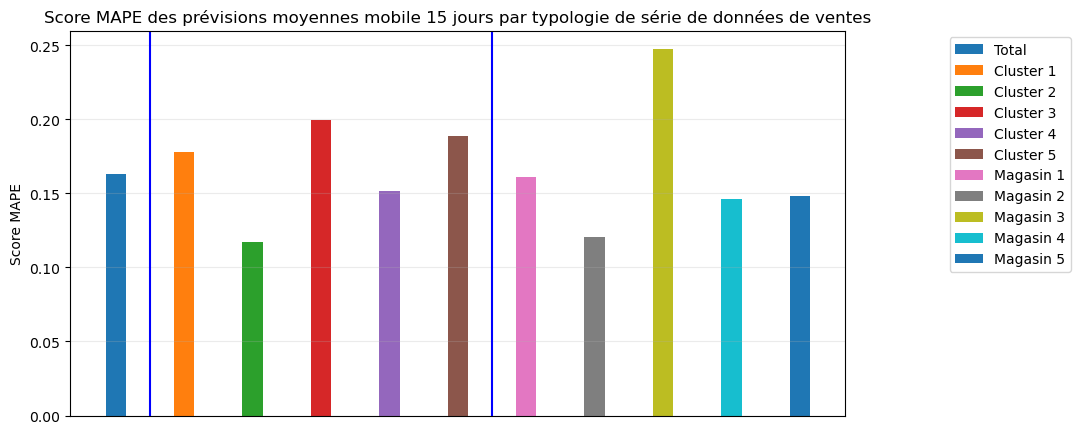

In [212]:
## Graphique de comparaison des scores MAPE du modèle de prévision moyenne mobile 15 jours
plt.figure(figsize=(10,5))
plt.title("Score MAPE des prévisions moyennes mobile 15 jours par typologie de série de données de ventes")
plt.ylabel('Score MAPE')
plt.bar(0,mape_sales_sma15, width=0.3, label = 'Total')
plt.axvline(x = 0.5, color = 'b')
plt.bar(1,mape_sales_type1, width=0.3, label = 'Cluster 1')
plt.bar(2,mape_sales_type2, width=0.3, label = 'Cluster 2')
plt.bar(3,mape_sales_type3, width=0.3, label = 'Cluster 3')
plt.bar(4,mape_sales_type4, width=0.3, label = 'Cluster 4')
plt.bar(5,mape_sales_type5, width=0.3, label = 'Cluster 5')
plt.axvline(x = 5.5, color = 'b')
plt.bar(6,mape_storeid_type1, width=0.3, label = 'Magasin 1')
plt.bar(7,mape_storeid_type2, width=0.3, label = 'Magasin 2')
plt.bar(8,mape_storeid_type3, width=0.3, label = 'Magasin 3')
plt.bar(9,mape_storeid_type4, width=0.3, label = 'Magasin 4')
plt.bar(10,mape_storeid_type5, width=0.3, label = 'Magasin 5')
plt.legend(bbox_to_anchor=(1.30, 1), loc='upper right') 
plt.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False)
plt.grid(axis='y', alpha=0.25)

In [213]:
#
# 4 - 3 Comparaison méthode série temporelle
#

In [214]:
# Prévisions des ventes sur les données de ventes passées
predict_sarima = model_sarima.predict()
#predict_sarima

In [215]:
# Fusion des données de ventes et prévisions du modèle SARIMAX
df_sarima_evaluation = df_forecast
df_sarima_evaluation['sarima_forecast'] = predict_sarima
df_sarima_evaluation = df_sarima_evaluation[df_sarima_evaluation['Date'] > '2015-01-01']
df_sarima_evaluation = df_sarima_evaluation[df_sarima_evaluation['Date'] < '2015-07-01']
df_sarima_evaluation = df_sarima_evaluation.reset_index(drop=True)
#df_sarima_evaluation

In [216]:
# Mesure de précision du modèle SARIMAX
observed_sales = df_sarima_evaluation['Sales_day']
predict_sales_sarima = df_sarima_evaluation['sarima_forecast']
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error,root_mean_squared_error
mae_sarima = mean_absolute_error(observed_sales, predict_sales_sarima)
mape_sarima = mean_absolute_percentage_error(observed_sales, predict_sales)
#mse_sales = mean_squared_error(observed_sales, predict_sales)
rmse_sarima = root_mean_squared_error(observed_sales, predict_sales_sarima)

print("Mesures de précision des prévisions\nmodèle SARIMA")
print("-----------------------------------")
print("MAE_sales:", round(mae_sarima,0))
print("MAPE_sales:", round(mape_sarima,3))
#print("MSE_sales:", round(mse_sales,0))
print("RMSE_sales:", round(rmse_sarima,0))

Mesures de précision des prévisions
modèle SARIMA
-----------------------------------
MAE_sales: 949121.0
MAPE_sales: 0.163
RMSE_sales: 1387035.0


In [217]:
# Table des données de ventes et de prévisions Facebook Prophet
df_prophet_evaluation = forecast
df_prophet_evaluation = df_prophet_evaluation[['ds','yhat']]
df_prophet_evaluation = df_prophet_evaluation[df_prophet_evaluation['ds'] > '2015-01-01']
df_prophet_evaluation = df_prophet_evaluation[df_prophet_evaluation['ds'] < '2015-07-01']
df_prophet_evaluation = df_prophet_evaluation.reset_index(drop=True)
df_prophet_evaluation['Sales_day'] = df_sarima_evaluation['Sales_day']
#df_prophet_evaluation

In [218]:
## Mesure de précision des prévisions Facebook Prophet
observed_sales = df_prophet_evaluation['Sales_day']
predict_sales_prophet = df_prophet_evaluation['yhat']
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error,root_mean_squared_error
mae_prophet = mean_absolute_error(observed_sales, predict_sales_prophet)
mape_prophet = mean_absolute_percentage_error(observed_sales, predict_sales_prophet)
#mse_sales = mean_squared_error(observed_sales, predict_sales_prophet)
rmse_prophet = root_mean_squared_error(observed_sales, predict_sales_prophet)

print("Mesures de précision des prévisions\nmodèle Facebook Prophet")
print("-----------------------------------")
print("MAE_sales:", round(mae_prophet,0))
print("MAPE_sales:", round(mape_prophet,3))
#print("MSE_sales:", round(mse_sales,0))
print("RMSE_sales:", round(rmse_prophet,0))

Mesures de précision des prévisions
modèle Facebook Prophet
-----------------------------------
MAE_sales: 1179161.0
MAPE_sales: 0.154
RMSE_sales: 1451145.0


In [219]:
# Table des ventes et prévisions des ventes des magasins de type 1
df_prophet_store_type1_evaluation = forecast_store_type1
df_prophet_store_type1_evaluation = df_prophet_store_type1_evaluation[['ds','yhat']]
df_prophet_store_type1_evaluation = df_prophet_store_type1_evaluation[df_prophet_store_type1_evaluation['ds'] > '2015-01-01']
df_prophet_store_type1_evaluation = df_prophet_store_type1_evaluation[df_prophet_store_type1_evaluation['ds'] < '2015-07-01']
df_prophet_store_type1_evaluation = df_prophet_store_type1_evaluation.dropna()
df_prophet_store_type1_evaluation = df_prophet_store_type1_evaluation.reset_index(drop=True)
df_prophet_store_type1_evaluation['Sales_day'] = df_store_type1_evaluation['Sales_day']
#df_prophet_store_type1_evaluation

In [220]:
# Table des ventes et prévisions des ventes des magasins de type 2
df_prophet_store_type2_evaluation = forecast_store_type2
df_prophet_store_type2_evaluation = df_prophet_store_type2_evaluation[['ds','yhat']]
df_prophet_store_type2_evaluation = df_prophet_store_type2_evaluation[df_prophet_store_type2_evaluation['ds'] > '2015-01-01']
df_prophet_store_type2_evaluation = df_prophet_store_type2_evaluation[df_prophet_store_type2_evaluation['ds'] < '2015-07-01']
df_prophet_store_type2_evaluation = df_prophet_store_type2_evaluation.dropna()
df_prophet_store_type2_evaluation = df_prophet_store_type2_evaluation.reset_index(drop=True)
df_prophet_store_type2_evaluation['Sales_day'] = df_store_type2_evaluation['Sales_day']
#df_prophet_store_type2_evaluation

In [221]:
# Table des ventes et prévisions des ventes des magasins de type 3
df_prophet_store_type3_evaluation = forecast_store_type3
df_prophet_store_type3_evaluation = df_prophet_store_type3_evaluation[['ds','yhat']]
df_prophet_store_type3_evaluation = df_prophet_store_type3_evaluation[df_prophet_store_type3_evaluation['ds'] > '2015-01-01']
df_prophet_store_type3_evaluation = df_prophet_store_type3_evaluation[df_prophet_store_type3_evaluation['ds'] < '2015-07-01']
df_prophet_store_type3_evaluation = df_prophet_store_type3_evaluation.dropna()
df_prophet_store_type3_evaluation = df_prophet_store_type3_evaluation.reset_index(drop=True)
df_prophet_store_type3_evaluation['Sales_day'] = df_store_type3_evaluation['Sales_day']
#df_prophet_store_type3_evaluation

In [222]:
# Table des ventes et prévisions des ventes des magasins de type 4
df_prophet_store_type4_evaluation = forecast_store_type4
df_prophet_store_type4_evaluation = df_prophet_store_type4_evaluation[['ds','yhat']]
df_prophet_store_type4_evaluation = df_prophet_store_type4_evaluation[df_prophet_store_type4_evaluation['ds'] > '2015-01-01']
df_prophet_store_type4_evaluation = df_prophet_store_type4_evaluation[df_prophet_store_type4_evaluation['ds'] < '2015-07-01']
df_prophet_store_type4_evaluation = df_prophet_store_type4_evaluation.dropna()
df_prophet_store_type4_evaluation = df_prophet_store_type4_evaluation.reset_index(drop=True)
df_prophet_store_type4_evaluation['Sales_day'] = df_store_type4_evaluation['Sales_day']
#df_prophet_store_type4_evaluation

In [223]:
# Table des ventes et prévisions des ventes des magasins de type 4
df_prophet_store_type5_evaluation = forecast_store_type5
df_prophet_store_type5_evaluation = df_prophet_store_type5_evaluation[['ds','yhat']]
df_prophet_store_type5_evaluation = df_prophet_store_type5_evaluation[df_prophet_store_type5_evaluation['ds'] > '2015-01-01']
df_prophet_store_type5_evaluation = df_prophet_store_type5_evaluation[df_prophet_store_type5_evaluation['ds'] < '2015-07-01']
df_prophet_store_type5_evaluation = df_prophet_store_type5_evaluation.dropna()
df_prophet_store_type5_evaluation = df_prophet_store_type5_evaluation.reset_index(drop=True)
df_prophet_store_type5_evaluation['Sales_day'] = df_store_type5_evaluation['Sales_day']
#df_prophet_store_type5_evaluation

In [224]:
# Création des variables de mesures de précision des prévisions du modèle facebook prophet
observed_prophet_store_type1 = df_prophet_store_type1_evaluation['Sales_day']
predict_prophet_store_type1 = df_prophet_store_type1_evaluation['yhat']
observed_prophet_store_type2 = df_prophet_store_type2_evaluation['Sales_day']
predict_prophet_store_type2 = df_prophet_store_type2_evaluation['yhat']
observed_prophet_store_type3 = df_prophet_store_type3_evaluation['Sales_day']
predict_prophet_store_type3 = df_prophet_store_type3_evaluation['yhat']
observed_prophet_store_type4 = df_prophet_store_type4_evaluation['Sales_day']
predict_prophet_store_type4 = df_prophet_store_type4_evaluation['yhat']
observed_prophet_store_type5 = df_prophet_store_type5_evaluation['Sales_day']
predict_prophet_store_type5 = df_prophet_store_type5_evaluation['yhat']

In [225]:
# Mesures de précision des prévisions du modèle facebook prophet
mae_sales_store_type1 = mean_absolute_error(observed_prophet_store_type1, predict_prophet_store_type1)
mape_sales_store_type1 = mean_absolute_percentage_error(observed_prophet_store_type1, predict_prophet_store_type1)
rmse_sales_store_type1 = root_mean_squared_error(observed_prophet_store_type1, predict_prophet_store_type1)
mae_sales_store_type2 = mean_absolute_error(observed_prophet_store_type2, predict_prophet_store_type2)
mape_sales_store_type2 = mean_absolute_percentage_error(observed_prophet_store_type2, predict_prophet_store_type2)
rmse_sales_store_type2 = root_mean_squared_error(observed_prophet_store_type2, predict_prophet_store_type2)
mae_sales_store_type3 = mean_absolute_error(observed_prophet_store_type3, predict_prophet_store_type3)
mape_sales_store_type3 = mean_absolute_percentage_error(observed_prophet_store_type3, predict_prophet_store_type3)
rmse_sales_store_type3 = root_mean_squared_error(observed_prophet_store_type3, predict_prophet_store_type3)
mae_sales_store_type4 = mean_absolute_error(observed_prophet_store_type4, predict_prophet_store_type4)
mape_sales_store_type4 = mean_absolute_percentage_error(observed_prophet_store_type4, predict_prophet_store_type4)
rmse_sales_store_type4 = root_mean_squared_error(observed_prophet_store_type4, predict_prophet_store_type4)
mae_sales_store_type5 = mean_absolute_error(observed_prophet_store_type5, predict_prophet_store_type5)
mape_sales_store_type5 = mean_absolute_percentage_error(observed_prophet_store_type5, predict_prophet_store_type5)
rmse_sales_store_type5 = root_mean_squared_error(observed_prophet_store_type5, predict_prophet_store_type5)

print("MAE_sales:", round(mae_sales_store_type1,0))
print("MAPE_sales:", round(mape_sales_store_type1,3))
print("RMSE_sales:", round(rmse_sales_store_type1,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_store_type2,0))
print("MAPE_sales:", round(mape_sales_store_type2,3))
print("RMSE_sales:", round(rmse_sales_store_type2,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_store_type3,0))
print("MAPE_sales:", round(mape_sales_store_type3,3))
print("RMSE_sales:", round(rmse_sales_store_type3,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_store_type4,0))
print("MAPE_sales:", round(mape_sales_store_type4,3))
print("RMSE_sales:", round(rmse_sales_store_type4,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_store_type5,0))
print("MAPE_sales:", round(mape_sales_store_type5,3))
print("RMSE_sales:", round(rmse_sales_store_type5,0))

MAE_sales: 329941.0
MAPE_sales: 0.155
RMSE_sales: 405021.0
-----------------
MAE_sales: 39831.0
MAPE_sales: 0.107
RMSE_sales: 48949.0
-----------------
MAE_sales: 117484.0
MAPE_sales: 0.154
RMSE_sales: 146775.0
-----------------
MAE_sales: 281693.0
MAPE_sales: 0.139
RMSE_sales: 350607.0
-----------------
MAE_sales: 413021.0
MAPE_sales: 0.192
RMSE_sales: 514274.0


In [226]:
# Table des ventes et prévisions des ventes des magasins de type 1
df_prophet_storeid_type1_evaluation = forecast_storeid_type1
df_prophet_storeid_type1_evaluation = df_prophet_storeid_type1_evaluation[['ds','yhat']]
df_prophet_storeid_type1_evaluation = df_prophet_storeid_type1_evaluation[df_prophet_storeid_type1_evaluation['ds'] > '2015-01-01']
df_prophet_storeid_type1_evaluation = df_prophet_storeid_type1_evaluation[df_prophet_storeid_type1_evaluation['ds'] < '2015-07-01']
df_prophet_storeid_type1_evaluation = df_prophet_storeid_type1_evaluation.dropna()
df_prophet_storeid_type1_evaluation = df_prophet_storeid_type1_evaluation.reset_index(drop=True)
df_prophet_storeid_type1_evaluation['Sales_day'] = df_storeid_type1_evaluation['Sales_day']
#df_prophet_storeid_type1_evaluation

In [227]:
# Table des ventes et prévisions des ventes des magasins de type 1
df_prophet_storeid_type2_evaluation = forecast_storeid_type2
df_prophet_storeid_type2_evaluation = df_prophet_storeid_type2_evaluation[['ds','yhat']]
df_prophet_storeid_type2_evaluation = df_prophet_storeid_type2_evaluation[df_prophet_storeid_type2_evaluation['ds'] > '2015-01-01']
df_prophet_storeid_type2_evaluation = df_prophet_storeid_type2_evaluation[df_prophet_storeid_type2_evaluation['ds'] < '2015-07-01']
df_prophet_storeid_type2_evaluation = df_prophet_storeid_type2_evaluation.dropna()
df_prophet_storeid_type2_evaluation = df_prophet_storeid_type2_evaluation.reset_index(drop=True)
df_prophet_storeid_type2_evaluation['Sales_day'] = df_storeid_type2_evaluation['Sales_day']
#df_prophet_storeid_type2_evaluation

In [228]:
# Table des ventes et prévisions des ventes des magasins de type 1
df_prophet_storeid_type3_evaluation = forecast_storeid_type3
df_prophet_storeid_type3_evaluation = df_prophet_storeid_type3_evaluation[['ds','yhat']]
df_prophet_storeid_type3_evaluation = df_prophet_storeid_type3_evaluation[df_prophet_storeid_type3_evaluation['ds'] > '2015-01-01']
df_prophet_storeid_type3_evaluation = df_prophet_storeid_type3_evaluation[df_prophet_storeid_type3_evaluation['ds'] < '2015-07-01']
df_prophet_storeid_type3_evaluation = df_prophet_storeid_type3_evaluation.dropna()
df_prophet_storeid_type3_evaluation = df_prophet_storeid_type3_evaluation.reset_index(drop=True)
df_prophet_storeid_type3_evaluation['Sales_day'] = df_storeid_type3_evaluation['Sales_day']
#df_prophet_storeid_type3_evaluation

In [229]:
# Table des ventes et prévisions des ventes des magasins de type 1
df_prophet_storeid_type4_evaluation = forecast_storeid_type4
df_prophet_storeid_type4_evaluation = df_prophet_storeid_type4_evaluation[['ds','yhat']]
df_prophet_storeid_type4_evaluation = df_prophet_storeid_type4_evaluation[df_prophet_storeid_type4_evaluation['ds'] > '2015-01-01']
df_prophet_storeid_type4_evaluation = df_prophet_storeid_type4_evaluation[df_prophet_storeid_type4_evaluation['ds'] < '2015-07-01']
df_prophet_storeid_type4_evaluation = df_prophet_storeid_type4_evaluation.dropna()
df_prophet_storeid_type4_evaluation = df_prophet_storeid_type4_evaluation.reset_index(drop=True)
df_prophet_storeid_type4_evaluation['Sales_day'] = df_storeid_type4_evaluation['Sales_day']
#df_prophet_storeid_type4_evaluation

In [230]:
# Table des ventes et prévisions des ventes des magasins de type 1
df_prophet_storeid_type5_evaluation = forecast_storeid_type5
df_prophet_storeid_type5_evaluation = df_prophet_storeid_type5_evaluation[['ds','yhat']]
df_prophet_storeid_type5_evaluation = df_prophet_storeid_type5_evaluation[df_prophet_storeid_type5_evaluation['ds'] > '2015-01-01']
df_prophet_storeid_type5_evaluation = df_prophet_storeid_type5_evaluation[df_prophet_storeid_type5_evaluation['ds'] < '2015-07-01']
df_prophet_storeid_type5_evaluation = df_prophet_storeid_type5_evaluation.dropna()
df_prophet_storeid_type5_evaluation = df_prophet_storeid_type5_evaluation.reset_index(drop=True)
df_prophet_storeid_type5_evaluation['Sales_day'] = df_storeid_type5_evaluation['Sales_day']
#df_prophet_storeid_type5_evaluation

In [231]:
# Création des variables de mesures de précision des prévisions du modèle facebook prophet
observed_prophet_storeid_type1 = df_prophet_storeid_type1_evaluation['Sales_day']
predict_prophet_storeid_type1 = df_prophet_storeid_type1_evaluation['yhat']
observed_prophet_storeid_type2 = df_prophet_storeid_type2_evaluation['Sales_day']
predict_prophet_storeid_type2 = df_prophet_storeid_type2_evaluation['yhat']
observed_prophet_storeid_type3 = df_prophet_storeid_type3_evaluation['Sales_day']
predict_prophet_storeid_type3 = df_prophet_storeid_type3_evaluation['yhat']
observed_prophet_storeid_type4 = df_prophet_storeid_type4_evaluation['Sales_day']
predict_prophet_storeid_type4 = df_prophet_storeid_type4_evaluation['yhat']
observed_prophet_storeid_type5 = df_prophet_storeid_type5_evaluation['Sales_day']
predict_prophet_storeid_type5 = df_prophet_storeid_type5_evaluation['yhat']

In [232]:
# Mesures de précision des prévisions du modèle facebook prophet
mae_sales_storeid_type1 = mean_absolute_error(observed_prophet_storeid_type1, predict_prophet_storeid_type1)
mape_sales_storeid_type1 = mean_absolute_percentage_error(observed_prophet_storeid_type1, predict_prophet_storeid_type1)
rmse_sales_storeid_type1 = root_mean_squared_error(observed_prophet_storeid_type1, predict_prophet_storeid_type1)
mae_sales_storeid_type2 = mean_absolute_error(observed_prophet_storeid_type2, predict_prophet_storeid_type2)
mape_sales_storeid_type2 = mean_absolute_percentage_error(observed_prophet_storeid_type2, predict_prophet_storeid_type2)
rmse_sales_storeid_type2 = root_mean_squared_error(observed_prophet_storeid_type2, predict_prophet_storeid_type2)
mae_sales_storeid_type3 = mean_absolute_error(observed_prophet_storeid_type3, predict_prophet_storeid_type3)
mape_sales_storeid_type3 = mean_absolute_percentage_error(observed_prophet_storeid_type3, predict_prophet_storeid_type3)
rmse_sales_storeid_type3 = root_mean_squared_error(observed_prophet_storeid_type3, predict_prophet_storeid_type3)
mae_sales_storeid_type4 = mean_absolute_error(observed_prophet_storeid_type4, predict_prophet_storeid_type4)
mape_sales_storeid_type4 = mean_absolute_percentage_error(observed_prophet_storeid_type4, predict_prophet_storeid_type4)
rmse_sales_storeid_type4 = root_mean_squared_error(observed_prophet_storeid_type4, predict_prophet_storeid_type4)
mae_sales_storeid_type5 = mean_absolute_error(observed_prophet_storeid_type5, predict_prophet_storeid_type5)
mape_sales_storeid_type5 = mean_absolute_percentage_error(observed_prophet_storeid_type5, predict_prophet_storeid_type5)
rmse_sales_storeid_type5 = root_mean_squared_error(observed_prophet_storeid_type5, predict_prophet_storeid_type5)

print("MAE_sales:", round(mae_sales_storeid_type1,0))
print("MAPE_sales:", round(mape_sales_storeid_type1,3))
print("RMSE_sales:", round(rmse_sales_storeid_type1,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_storeid_type2,0))
print("MAPE_sales:", round(mape_sales_storeid_type2,3))
print("RMSE_sales:", round(rmse_sales_storeid_type2,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_storeid_type3,0))
print("MAPE_sales:", round(mape_sales_storeid_type3,3))
print("RMSE_sales:", round(rmse_sales_storeid_type3,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_storeid_type4,0))
print("MAPE_sales:", round(mape_sales_storeid_type4,3))
print("RMSE_sales:", round(rmse_sales_storeid_type4,0))
print("-----------------")
print("MAE_sales:", round(mae_sales_storeid_type5,0))
print("MAPE_sales:", round(mape_sales_storeid_type5,3))
print("RMSE_sales:", round(rmse_sales_storeid_type5,0))

MAE_sales: 641.0
MAPE_sales: 0.147
RMSE_sales: 790.0
-----------------
MAE_sales: 2267.0
MAPE_sales: 0.115
RMSE_sales: 2778.0
-----------------
MAE_sales: 1264.0
MAPE_sales: 0.186
RMSE_sales: 1549.0
-----------------
MAE_sales: 1272.0
MAPE_sales: 0.134
RMSE_sales: 1723.0
-----------------
MAE_sales: 1094.0
MAPE_sales: 0.143
RMSE_sales: 1371.0


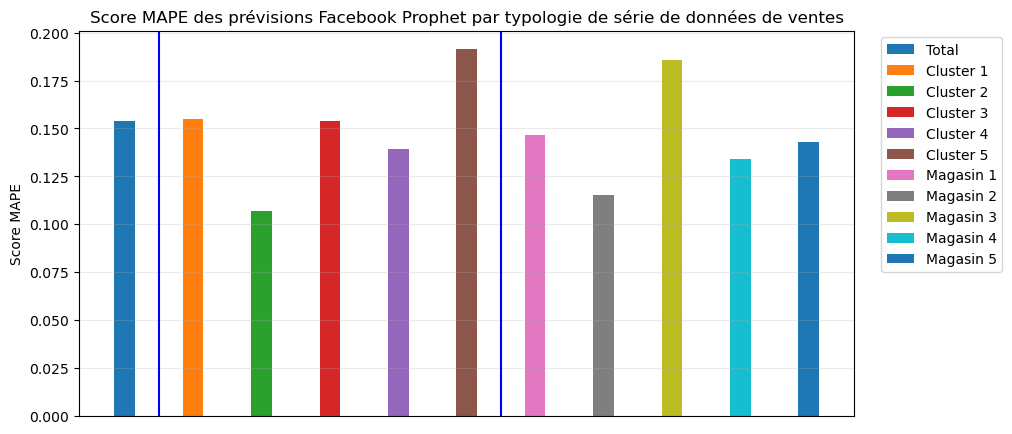

In [233]:
## Graphique de comparaison des scores MAPE du modèle de prévision Facebook Prophet
plt.figure(figsize=(10,5))
plt.title("Score MAPE des prévisions Facebook Prophet par typologie de série de données de ventes")
plt.ylabel('Score MAPE')
plt.bar(0,mape_prophet, width=0.3, label = 'Total')
plt.axvline(x = 0.5, color = 'b')
plt.bar(1,mape_sales_store_type1, width=0.3, label = 'Cluster 1')
plt.bar(2,mape_sales_store_type2, width=0.3, label = 'Cluster 2')
plt.bar(3,mape_sales_store_type3, width=0.3, label = 'Cluster 3')
plt.bar(4,mape_sales_store_type4, width=0.3, label = 'Cluster 4')
plt.bar(5,mape_sales_store_type5, width=0.3, label = 'Cluster 5')
plt.axvline(x = 5.5, color = 'b')
plt.bar(6,mape_sales_storeid_type1, width=0.3, label = 'Magasin 1')
plt.bar(7,mape_sales_storeid_type2, width=0.3, label = 'Magasin 2')
plt.bar(8,mape_sales_storeid_type3, width=0.3, label = 'Magasin 3')
plt.bar(9,mape_sales_storeid_type4, width=0.3, label = 'Magasin 4')
plt.bar(10,mape_sales_storeid_type5, width=0.3, label = 'Magasin 5')
plt.legend(bbox_to_anchor=(1.2, 1), loc='upper right') 
plt.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False)
plt.grid(axis='y', alpha=0.25)

In [234]:
#
# Comparaison des méthodes de prévision moyenne mobile 15 jours et Facebook Prophet
#

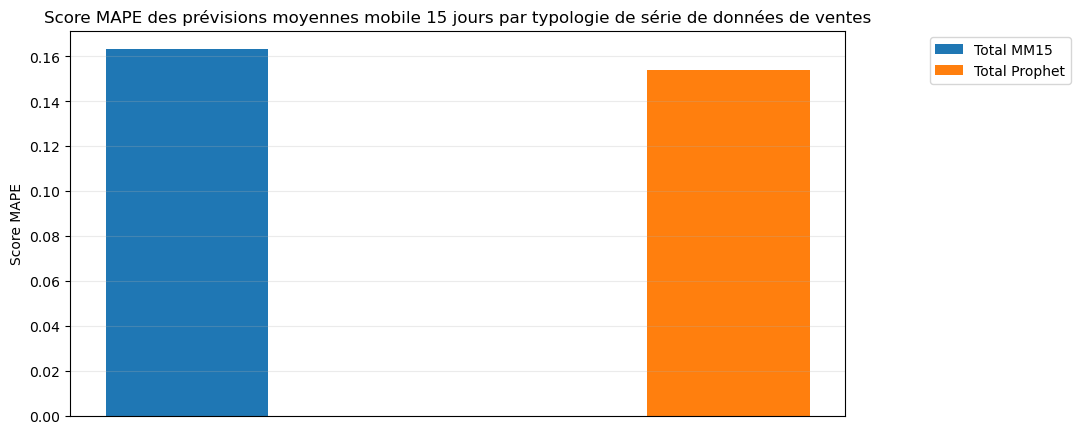

In [235]:
## Graphique de comparaison des scores MAPE de la série de données complète
plt.figure(figsize=(10,5))
plt.title("Score MAPE des prévisions moyennes mobile 15 jours par typologie de série de données de ventes")
plt.ylabel('Score MAPE')
plt.bar(0,mape_sales_sma15, width=0.3, label = 'Total MM15')
plt.bar(1,mape_prophet, width=0.3, label = 'Total Prophet')
plt.legend(bbox_to_anchor=(1.3, 1), loc='upper right') 
plt.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False)
plt.grid(axis='y', alpha=0.25)

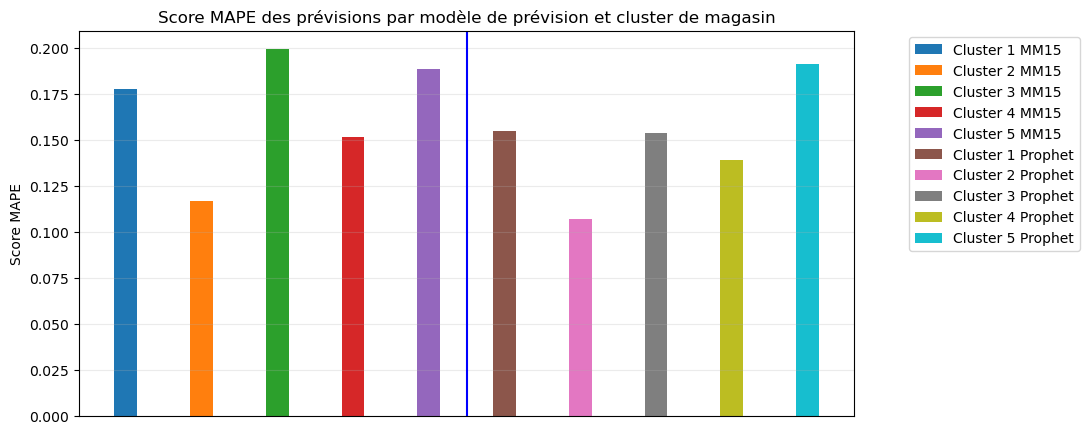

In [236]:
## Graphique de comparaison des scores MAPE du modèle moyenne mobile 15 jours et Facebook Prophet par cluster de magasin
plt.figure(figsize=(10,5))
plt.title("Score MAPE des prévisions par modèle de prévision et cluster de magasin")
plt.ylabel('Score MAPE')
plt.bar(0,mape_sales_type1, width=0.3, label = 'Cluster 1 MM15')
plt.bar(1,mape_sales_type2, width=0.3, label = 'Cluster 2 MM15')
plt.bar(2,mape_sales_type3, width=0.3, label = 'Cluster 3 MM15')
plt.bar(3,mape_sales_type4, width=0.3, label = 'Cluster 4 MM15')
plt.bar(4,mape_sales_type5, width=0.3, label = 'Cluster 5 MM15')
plt.axvline(x = 4.5, color = 'b')
plt.bar(5,mape_sales_store_type1, width=0.3, label = 'Cluster 1 Prophet')
plt.bar(6,mape_sales_store_type2, width=0.3, label = 'Cluster 2 Prophet')
plt.bar(7,mape_sales_store_type3, width=0.3, label = 'Cluster 3 Prophet')
plt.bar(8,mape_sales_store_type4, width=0.3, label = 'Cluster 4 Prophet')
plt.bar(9,mape_sales_store_type5, width=0.3, label = 'Cluster 5 Prophet')
plt.legend(bbox_to_anchor=(1.3, 1), loc='upper right') 
plt.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False)
plt.grid(axis='y', alpha=0.25)

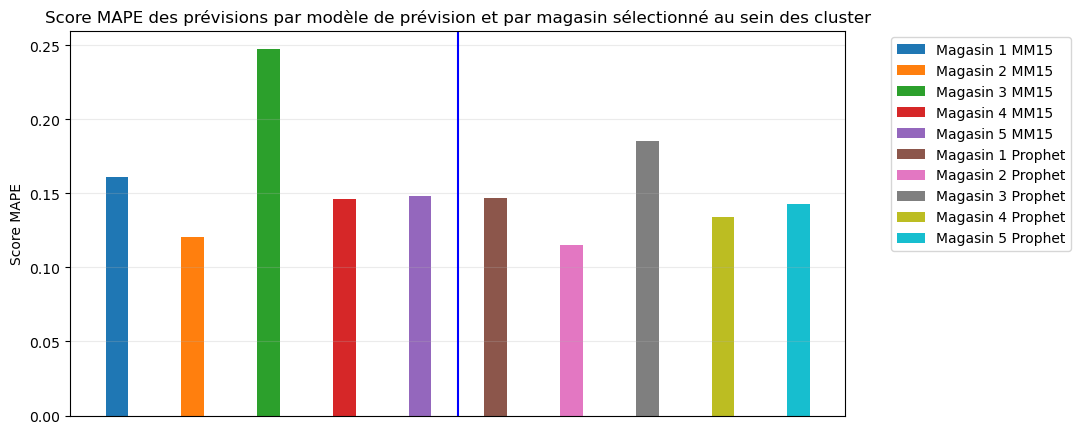

In [237]:
## Graphique de comparaison des scores MAPE du modèle moyenne mobile 15 jours et Facebook Prophet par magasin sélectionné au sein d'un cluster
plt.figure(figsize=(10,5))
plt.title("Score MAPE des prévisions par modèle de prévision et par magasin sélectionné au sein des cluster")
plt.ylabel('Score MAPE')
plt.bar(0,mape_storeid_type1, width=0.3, label = 'Magasin 1 MM15')
plt.bar(1,mape_storeid_type2, width=0.3, label = 'Magasin 2 MM15')
plt.bar(2,mape_storeid_type3, width=0.3, label = 'Magasin 3 MM15')
plt.bar(3,mape_storeid_type4, width=0.3, label = 'Magasin 4 MM15')
plt.bar(4,mape_storeid_type5, width=0.3, label = 'Magasin 5 MM15')
plt.axvline(x = 4.5, color = 'b')
plt.bar(5,mape_sales_storeid_type1, width=0.3, label = 'Magasin 1 Prophet')
plt.bar(6,mape_sales_storeid_type2, width=0.3, label = 'Magasin 2 Prophet')
plt.bar(7,mape_sales_storeid_type3, width=0.3, label = 'Magasin 3 Prophet')
plt.bar(8,mape_sales_storeid_type4, width=0.3, label = 'Magasin 4 Prophet')
plt.bar(9,mape_sales_storeid_type5, width=0.3, label = 'Magasin 5 Prophet')
plt.legend(bbox_to_anchor=(1.3, 1), loc='upper right') 
plt.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False)
plt.grid(axis='y', alpha=0.25)